# 01 · Construir el dataset y la tabla SCARF (Etapa 2)

Corran las celdas en orden (`Shift + Enter`). Cada paso dice **qué hace**, **con qué llave** y **qué cuidar**.

| Parte | Una fila = | Para qué |
|---|---|---|
| **A** (Pasos 1–9) | una planta eléctrica | **Entrenar** el modelo. Target: intensidad hídrica (= WUE_off) |
| **B** (Pasos 10–16) | una región (PCA) | **Calcular** el AWI con PUE, WUE y WSF. No se entrena |

**SCARF:** $AWI = (WUE_{on} + PUE \cdot WUE_{off}) \times WSF$ por MWh de TI.
Solo **WUE_off** se aprende con ML. PUE y WUE_on son parámetros; WSF es una consulta.

**Reglas:** (1) nada que contenga el target entra como feature; (2) no imputar ni escalar aquí (eso va en el
Pipeline); (3) los joins siempre con `how="left"` para no perder plantas.

---
# Parte A · Dataset de entrenamiento

# 1. Creación y Enriquecimiento del Dataset

En esta sección se consolida la información proveniente de múltiples fuentes oficiales correspondientes al año **2018** para construir el dataset de entrenamiento base.

### Fuentes de Datos integradas:
*   **Table 2 & 5 (Siddik et al., 2021):** Información base de plantas eléctricas e intensidades hídricas observadas (`y_water_intensity`), junto con el factor de estrés hídrico de la subcuenca (`cf_aware`).
*   **EIA-860 (2018):** Tipo de sistema de enfriamiento (`cool_*`), clave para explicar la variabilidad de intensidad hídrica en plantas de generación térmica.
*   **EPA eGRID (2018):** Capacidad nominal de la planta (`capacity_mw`), factores de planta (`capacity_factor`) y número de generadores (`n_generadores`).
*   **WRI Aqueduct 4.0:** Puntuación de estrés hídrico de la zona geográfica (`bws_score`) mediante join espacial.

### Puntos de Atención para Refinamiento:
1.  **El problema de Hydro (Hidroeléctricas):** El dataset contiene un subgrupo crítico (`HYDRO`) con intensidades hídricas gigantescas (por evaporación en embalses) y un 45% de valores imputados exactamente a cero. Esta distorsión física es el principal cuello de botella del entrenamiento.
```

## Paso 1 · Preparar carpetas y archivos

```
proyecto/
├── data/raw/         ← archivos descargados (no se editan)
├── data/processed/   ← lo que genera este notebook
└── notebooks/01_construir_dataset.ipynb
```

**La primera celda descarga todo sola** (en Colab o en su computadora) y no repite lo que ya está:

| Archivo en `data/raw/` | De dónde | ¿Automático? |
|---|---|---|
| `Input_data.xlsx` | Siddik (repositorio Virginia Tech) | Nop, figshare bloquea google collab asi que tiene que ser manual |
| `6_2_EnviroEquip_Y2018.xlsx` | ZIP de **EIA-860 2018** | Sí (se extrae del ZIP) |
| `egrid2018_data_v2.xlsx` | **eGRID2018** (EPA) | Sí |
| `Global_Analysis_SI_Final.xlsx` | Modelo de **Masanet et al. (2020)** en GitHub → PUE | Sí |
| carpeta `aqueduct/` | WRI Aqueduct 4.0 | No: es opcional y pesa mucho; a mano si lo quieren |

Si una descarga falla, la celda dice cuál y dónde ponerla a mano. **Año 2018** en todo, igual que Siddik.

In [ ]:
# Descarga automática de los archivos (Colab o computadora). Si un archivo ya está, no lo vuelve a bajar.
import os
import sys
import shutil
import zipfile
import urllib.request
from pathlib import Path

RAW = Path("../data/raw") if Path.cwd().name == "notebooks" else Path("data/raw")
RAW.mkdir(parents=True, exist_ok=True)

input_file = RAW / "Input_data.xlsx"


def _es_xlsx_valido(path):
    try:
        with zipfile.ZipFile(path, 'r'):
            return True
    except Exception:
        return False


# --- Validar/borrar Input_data.xlsx corrupto ---
if input_file.exists() and not _es_xlsx_valido(input_file):
    print("⚠ 'Input_data.xlsx' inválido o corrupto. Eliminando...")
    input_file.unlink()

FUENTES = {
    "6_2_EnviroEquip_Y2018.xlsx": "https://www.eia.gov/electricity/data/eia860/archive/xls/eia8602018.zip",
    "egrid2018_data_v2.xlsx": "https://www.epa.gov/sites/default/files/2020-03/egrid2018_data_v2.xlsx",
    "Global_Analysis_SI_Final.xlsx": "https://raw.githubusercontent.com/emasanet/GlobalDCAnalysis/60bdff3cf601c522dd1e27b2dca9f12ad2f7e910/Global_Analysis_SI_Final.xlsx",
}

URL_GITHUB = "https://raw.githubusercontent.com/MoonFoxCake/Proyecto-IA-Investigacion-Datacenters/main/SI_XLS.zip"
URL_FIGSHARE = "https://ndownloader.figshare.com/files/27856827"

if not input_file.exists():
    zip_temp = RAW / "input_data_temp.zip"
    exito = False

    # 1. Intento con GitHub (Prioritario)
    print("↓ Intentando descarga automática desde GitHub...")
    headers_gh = {
        "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/120.0.0.0 Safari/537.36"
    }
    try:
        import requests
        with requests.Session() as s:
            s.headers.update(headers_gh)
            r = s.get(URL_GITHUB, stream=True, allow_redirects=True, timeout=30)
            if r.status_code == 200:
                with open(zip_temp, "wb") as f:
                    for chunk in r.iter_content(1024 * 256):
                        if chunk:
                            f.write(chunk)
                if zipfile.is_zipfile(zip_temp):
                    exito = True
                    print("✔ Descarga exitosa desde GitHub.")
    except Exception as e:
        print(f"  Descarga desde GitHub falló: {e}")

    # 2. Intento con Figshare (Respaldo en caso de error)
    if not exito:
        print("↓ GitHub no disponible. Intentando enlace de respaldo (Figshare)...")
        headers_fs = {
            "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/120.0.0.0 Safari/537.36",
            "Accept": "application/zip, application/octet-stream, */*",
            "Referer": "https://figshare.com/"
        }
        try:
            import requests
            with requests.Session() as s:
                s.headers.update(headers_fs)
                r = s.get(URL_FIGSHARE, stream=True, allow_redirects=True, timeout=60)
                if r.status_code == 200:
                    with open(zip_temp, "wb") as f:
                        for chunk in r.iter_content(1024 * 256):
                            if chunk:
                                f.write(chunk)
                    if zipfile.is_zipfile(zip_temp):
                        exito = True
                        print("✔ Descarga exitosa desde Figshare.")
        except Exception as e:
            print(f"  Descarga desde Figshare falló: {e}")

    # Extracción de Input_data.xlsx
    if exito:
        with zipfile.ZipFile(zip_temp) as z:
            xlsx_files = [n for n in z.namelist() if n.lower().endswith(".xlsx")]
            elegido = [n for n in xlsx_files if "input_data" in n.lower()] or xlsx_files
            if elegido:
                input_file.write_bytes(z.read(elegido[0]))
                print(f"✔ Extraído: {elegido[0]} -> Input_data.xlsx")
        zip_temp.unlink()
    else:
        if zip_temp.exists():
            zip_temp.unlink()
        print("✗ Descarga automática no disponible de ninguna fuente. Se requiere subida manual.")
else:
    print("ya existe      Input_data.xlsx")


# --- Plan B: subida interactiva (Colab o local) ---
if not input_file.exists():
    print("\n" + "=" * 62)
    print("⚠  Descarga automática no disponible.")
    print("   Descarga manualmente el ZIP desde GitHub:")
    print(f"   https://github.com/MoonFoxCake/Proyecto-IA-Investigacion-Datacenters/blob/main/SI_XLS.zip")
    print("   O desde el repositorio original de Figshare (enlace original):")
    print(f"   {URL_FIGSHARE}")
    print("   (o directamente Input_data.xlsx si lo tienes a mano)")
    print("=" * 62)

    if "google.colab" in sys.modules:
        # --- Colab ---
        from google.colab import files
        print("\nSube el archivo 'Input_data.xlsx' o el ZIP completo:\n")
        subidos = files.upload()
        for nombre in subidos:
            p = Path(nombre)
            if nombre.lower().endswith(".zip"):
                with zipfile.ZipFile(p) as z:
                    xlsx_files = [n for n in z.namelist() if n.lower().endswith(".xlsx")]
                    elegido = [n for n in xlsx_files if "input_data" in n.lower()] or xlsx_files
                    if elegido:
                        input_file.write_bytes(z.read(elegido[0]))
                        print(f"Extraído del ZIP: {elegido[0]} -> Input_data.xlsx")
                    else:
                        print("El ZIP no contiene ningún .xlsx.")
                p.unlink()
            elif nombre.lower().endswith(".xlsx"):
                shutil.move(str(p), str(input_file))
                print(" Archivo guardado como Input_data.xlsx")
    else:
        # --- Local: diálogo de archivo con tkinter ---
        try:
            import tkinter as tk
            from tkinter import filedialog
            root = tk.Tk()
            root.withdraw()
            ruta = filedialog.askopenfilename(
                title="Selecciona Input_data.xlsx o el ZIP de GitHub / Figshare",
                filetypes=[("Excel o ZIP", "*.xlsx *.zip"), ("Todos", "*.*")],
            )
            root.destroy()
            if ruta:
                p = Path(ruta)
                if p.suffix.lower() == ".zip":
                    with zipfile.ZipFile(p) as z:
                        xlsx_files = [n for n in z.namelist() if n.lower().endswith(".xlsx")]
                        elegido = [n for n in xlsx_files if "input_data" in n.lower()] or xlsx_files
                        if elegido:
                            input_file.write_bytes(z.read(elegido[0]))
                            print(f"✔ Extraído del ZIP: {elegido[0]} -> Input_data.xlsx")
                elif p.suffix.lower() == ".xlsx":
                    shutil.copy(str(p), str(input_file))
                    print(f"✔ Copiado: {p.name} -> Input_data.xlsx")
            else:
                print("  Diálogo cancelado.")
        except Exception as e:
            print(f"  (No se pudo abrir diálogo: {e})")
            print(f"  Coloca manualmente el archivo en: {input_file.resolve()}")
            print("  y vuelve a ejecutar esta celda.")


# 2. eGRID
egrid_file = RAW / "egrid2018_data_v2.xlsx"
if not egrid_file.exists():
    print("↓ Descargando egrid2018_data_v2.xlsx...")
    os.system(f'curl -L -A "Mozilla/5.0" -o "{egrid_file}" "{FUENTES["egrid2018_data_v2.xlsx"]}"')
else:
    print("ya existe      egrid2018_data_v2.xlsx")

# 3. Global Analysis (PUE)
pue_file = RAW / "Global_Analysis_SI_Final.xlsx"
if not pue_file.exists():
    print("↓ Descargando Global_Analysis_SI_Final.xlsx...")
    os.system(f'curl -L -A "Mozilla/5.0" -o "{pue_file}" "{FUENTES["Global_Analysis_SI_Final.xlsx"]}"')
else:
    print("ya existe      Global_Analysis_SI_Final.xlsx")

# 4. EIA-860
eia_file = RAW / "6_2_EnviroEquip_Y2018.xlsx"
if not eia_file.exists():
    print("↓ Descargando y extrayendo EIA-860 ZIP...")
    zip_temp = RAW / "eia860_temp.zip"
    os.system(f'curl -L -A "Mozilla/5.0" -o "{zip_temp}" "{FUENTES["6_2_EnviroEquip_Y2018.xlsx"]}"')
    if zip_temp.exists():
        with zipfile.ZipFile(zip_temp) as z:
            xlsx_files = [n for n in z.namelist() if n.lower().endswith(".xlsx")]
            elegido = [n for n in xlsx_files if "enviroequip" in n.lower()] or xlsx_files
            if elegido:
                eia_file.write_bytes(z.read(elegido[0]))
                print(f"   (extraído de: {elegido[0]})")
        zip_temp.unlink()
else:
    print(" ya existe      6_2_EnviroEquip_Y2018.xlsx")

print("\nArchivos finales en data/raw:", sorted(os.listdir(RAW)))

↓ Intentando descarga automática desde GitHub...
✔ Descarga exitosa desde GitHub.
✔ Extraído: SI_XLS/Input data.xlsx -> Input_data.xlsx
↓ Descargando egrid2018_data_v2.xlsx...
↓ Descargando Global_Analysis_SI_Final.xlsx...
↓ Descargando y extrayendo EIA-860 ZIP...
   (extraído de: 6_2_EnviroEquip_Y2018.xlsx)

Archivos finales en data/raw: ['6_2_EnviroEquip_Y2018.xlsx', 'Global_Analysis_SI_Final.xlsx', 'Input_data.xlsx', 'egrid2018_data_v2.xlsx']


In [ ]:
from pathlib import Path
import json
import numpy as np
import pandas as pd

pd.set_option("display.max_columns", 50)

# --- Rutas: el notebook funciona si lo corren desde la raíz del proyecto o desde notebooks/ ---
if Path("data/raw").exists():
    BASE = Path(".")
elif Path("../data/raw").exists():
    BASE = Path("..")
else:
    raise FileNotFoundError("No encuentro data/raw. Revisen la estructura de carpetas del Paso 1.")

RAW_DIR = BASE / "data" / "raw"
OUT_DIR = BASE / "data" / "processed"
OUT_DIR.mkdir(parents=True, exist_ok=True)

SIDDIK_XLSX = RAW_DIR / "Input_data.xlsx"
EIA860_XLSX = RAW_DIR / "6_2_EnviroEquip_Y2018.xlsx"
EGRID_XLSX = RAW_DIR / "egrid2018_data_v2.xlsx"
AQUEDUCT_DIR = RAW_DIR / "aqueduct"

for f in [SIDDIK_XLSX, EIA860_XLSX, EGRID_XLSX, AQUEDUCT_DIR]:
    print(("Encontrado:   " if f.exists() else "No está:     ") + str(f))

Encontrado:   data/raw/Input_data.xlsx
Encontrado:   data/raw/6_2_EnviroEquip_Y2018.xlsx
Encontrado:   data/raw/egrid2018_data_v2.xlsx
No está:     data/raw/aqueduct


In [ ]:
def leer_excel_con_encabezado(ruta, hoja, palabra_clave, max_filas=10):
    '''Muchos Excel oficiales traen filas de título ANTES de los nombres de columna.
    Esta función busca en qué fila aparece `palabra_clave` y la usa como encabezado.'''
    crudo = pd.read_excel(ruta, sheet_name=hoja, header=None, nrows=max_filas)
    for i, fila in crudo.iterrows():
        if any(str(v).strip() == palabra_clave for v in fila.values):
            return pd.read_excel(ruta, sheet_name=hoja, header=i)
    raise ValueError(f"No encontré la columna '{palabra_clave}' en las primeras {max_filas} filas de {hoja}")


# Aquí se va guardando cuántas plantas encontraron dato en cada join (para el README)
cobertura = []

## Paso 2 · Cargar la Table 2 (la base)

- 8 403 plantas, sin IDs repetidos y sin faltantes en el target.
- Se renombran las columnas a nombres cortos. Las de fuga quedan marcadas con `LEAK_` y se eliminan en el Paso 7.
- `fuel_group` **no es duplicado** de `fuel`: es el grupo (11) vs. el combustible detallado (33).

In [ ]:
t2 = pd.read_excel(SIDDIK_XLSX, sheet_name="Table 2", header=2, engine="openpyxl")
t2 = t2.dropna(how="all")          # por si hay filas totalmente vacías al final

print("Filas y columnas:", t2.shape)
print("Plant Id repetidos:", t2["Plant Id"].duplicated().sum())
print("Faltantes en el target:", t2["Water intensity (m3/MWh)"].isna().sum())
t2.head()

Filas y columnas: (8403, 19)
Plant Id repetidos: 0
Faltantes en el target: 0


,Plant state,Plant name,Plant Id,Balancing Authority Name,Balancing Authority Code,PCA Generation (MWh),Latitude,Longitude,Plant primary fuel,Plant primary fuel code,Net generation (MWh),CO2-e Emission (tons),Water intensity (m3/MWh),Carbon intensity (Tons/MWh),Generation Ratio of Power plant,Water Consumption (m3),Subbasin,HUC8,HUC8 ID
0,AL,ABC Coke,56076,"Southern Company Services, Inc. - Trans",SOCO,2.554145e+08,33.582793,-86.779866,COG,COAL,5290.00,1552.988,1.847267,0.293571,0.000021,9772.043741,Locust,3160111,3160111
1,AL,Alabama Pine Pulp,54429,"Southern Company Services, Inc. - Trans",SOCO,2.554145e+08,31.582500,-87.488900,BLQ,BIOMASS,413079.77,10436.106,1.937552,0.025264,0.001617,800363.491644,Lower Alabama,3150204,3150204
2,AL,Alabama River Pulp,10216,"Southern Company Services, Inc. - Trans",SOCO,2.554145e+08,31.582500,-87.488900,BLQ,BIOMASS,308063.28,12986.077,1.937552,0.042154,0.001206,596888.592313,Lower Alabama,3150204,3150204
3,AL,AMEA Sylacauga Plant,56018,"Southern Company Services, Inc. - Trans",SOCO,2.554145e+08,33.166100,-86.282500,NG,GAS,34570.00,22786.699,0.797026,0.659147,0.000135,27553.194096,Lower Coosa,3150107,3150107
4,AL,ANAD Solar Array,60680,"Southern Company Services, Inc. - Trans",SOCO,2.554145e+08,33.626728,-85.969481,SUN,SOLAR,17168.00,0.000,0.007600,0.000000,0.000067,130.476800,Middle Coosa,3150106,3150106


In [ ]:
renombrar = {
    "Plant Id": "plant_id",
    "Plant name": "plant_name",
    "Plant state": "state",
    "Balancing Authority Name": "ba_name",
    "Balancing Authority Code": "ba_code",
    "PCA Generation (MWh)": "pca_generation_mwh",
    "Latitude": "lat",
    "Longitude": "lon",
    "Plant primary fuel": "fuel",
    "Plant primary fuel code": "fuel_group",
    "Net generation (MWh)": "net_generation_mwh",
    "Generation Ratio of Power plant": "generation_ratio",
    "Subbasin": "subbasin_name",
    "HUC8": "huc8_dup",
    "HUC8 ID": "huc8_id",
    # --- columnas de FUGA se eliminan despues---
    "Water Consumption (m3)": "LEAK_water_consumption_m3",
    "CO2-e Emission (tons)": "LEAK_co2e_tons",
    "Carbon intensity (Tons/MWh)": "LEAK_carbon_intensity",
    # --- Columna princi9pal ---
    "Water intensity (m3/MWh)": "y_water_intensity",
}
df = t2.rename(columns=renombrar)

# HUC8 se guarda como texto de 8 dígitos (los códigos que empiezan con 0 perdieron el cero en Excel)
df["huc8"] = df["huc8_id"].astype(int).astype(str).str.zfill(8)

print(df.columns.tolist())

['state', 'plant_name', 'plant_id', 'ba_name', 'ba_code', 'pca_generation_mwh', 'lat', 'lon', 'fuel', 'fuel_group', 'net_generation_mwh', 'LEAK_co2e_tons', 'y_water_intensity', 'LEAK_carbon_intensity', 'generation_ratio', 'LEAK_water_consumption_m3', 'subbasin_name', 'huc8_dup', 'huc8_id', 'huc8']


## Paso 3 · Unir Table 5: escasez hídrica (WSF)

- **Aporta:** `cf_aware`, el factor de escasez de la subcuenca. **Llave:** `huc8_id`.
- **Fuga:** no. Describe la cuenca, no el agua de la planta.
- **Cuidar:** `validate="many_to_one"` hace que pandas falle si el join fuera a duplicar filas.

In [ ]:
t5 = pd.read_excel(SIDDIK_XLSX, sheet_name="Table 5", header=2).dropna(how="all")
t5 = t5.rename(columns={"HUC8 ID": "huc8_id", "Characterization factor": "cf_aware"})[["huc8_id", "cf_aware"]]

filas_antes = len(df)
df = df.merge(t5, on="huc8_id", how="left", validate="many_to_one")
assert len(df) == filas_antes, "¡El join duplicó filas!"

pct = df["cf_aware"].notna().mean() * 100
cobertura.append({"fuente": "Siddik Table 5", "columna": "cf_aware", "plantas_con_dato_%": round(pct, 2)})
print(f"Plantas con factor AWARE: {pct:.2f}%")
df[["plant_id", "huc8", "cf_aware"]].head()

Plantas con factor AWARE: 99.99%


,plant_id,huc8,cf_aware
0,56076,03160111,0.288336
1,54429,03150204,0.100000
2,10216,03150204,0.100000
3,56018,03150107,0.100000
4,60680,03150106,0.100000


## Paso 4 · Unir EIA-860: tipo de enfriamiento

- **Aporta:** banderas 0/1 `cool_un_paso`, `cool_recirculacion`, `cool_seco`, `cool_hibrido`, `cool_otro`.
  Explica por qué dos plantas de gas tienen intensidades distintas. **Llave:** `plant_id` (= `Plant Code` de EIA).
- **Fuga:** no. Es una decisión de diseño.
- **Cuidar:** las plantas sin enfriamiento (solar, eólica, hidro) quedan con `cool_sin_registro = 1`: no es un faltante.

In [ ]:
def grupo_enfriamiento(codigo):
    c = str(codigo).strip().upper()
    if c in ("", "NAN", "NONE"):
        return None
    if c in ("HT", "OT"):
        return "otro"
    if c.startswith("D"):
        return "seco"
    if c.startswith("H"):
        return "hibrido"
    if c.startswith("O"):
        return "un_paso"
    if c.startswith("R"):
        return "recirculacion"
    return "otro"


GRUPOS_COOL = ["un_paso", "recirculacion", "seco", "hibrido", "otro"]

if EIA860_XLSX.exists():
    cool = leer_excel_con_encabezado(EIA860_XLSX, hoja="Cooling", palabra_clave="Plant Code")
    print("Hoja Cooling:", cool.shape)

    # Solo sistemas en operación (si existe la columna de estado)
    if "Cooling Status" in cool.columns:
        print(cool["Cooling Status"].value_counts().head())
        cool = cool[cool["Cooling Status"].astype(str).str.upper().isin(["OP", "SB"])]

    cols_tipo = [c for c in cool.columns if str(c).startswith("Cooling Type")]
    print("Columnas de tipo:", cols_tipo)

    # Pasar de formato ancho (Type 1..4) a largo: una fila por (planta, tipo)
    largo = cool.melt(id_vars="Plant Code", value_vars=cols_tipo, value_name="codigo")
    largo["grupo"] = largo["codigo"].map(grupo_enfriamiento)
    largo = largo.dropna(subset=["grupo"])

    # Una fila por planta, una columna 0/1 por grupo
    banderas = (pd.crosstab(largo["Plant Code"], largo["grupo"]) > 0).astype(int)
    banderas = banderas.reindex(columns=GRUPOS_COOL, fill_value=0).add_prefix("cool_")
    banderas["n_sistemas_enfriamiento"] = cool.groupby("Plant Code").size()
    banderas = banderas.reset_index().rename(columns={"Plant Code": "plant_id"})
    banderas["plant_id"] = pd.to_numeric(banderas["plant_id"], errors="coerce")
    banderas = banderas.dropna(subset=["plant_id"]).astype({"plant_id": int})

    filas_antes = len(df)
    df = df.merge(banderas, on="plant_id", how="left", validate="one_to_one")
    assert len(df) == filas_antes

    # Plantas sin registro de enfriamiento → banderas en 0 y bandera "sin_registro" en 1
    df["cool_sin_registro"] = df["cool_un_paso"].isna().astype(int)
    cols_cool = [f"cool_{g}" for g in GRUPOS_COOL] + ["n_sistemas_enfriamiento"]
    df[cols_cool] = df[cols_cool].fillna(0).astype(int)

    pct = (1 - df["cool_sin_registro"].mean()) * 100
    cobertura.append({"fuente": "EIA-860 2018", "columna": "cool_*", "plantas_con_dato_%": round(pct, 2)})
    print(f"Plantas con enfriamiento reportado: {pct:.2f}%")
    print("\n¿Tiene sentido? Revisen esta tabla: térmicas con enfriamiento, renovables sin registro.")
    print(pd.crosstab(df["fuel_group"], df["cool_sin_registro"]))
else:
    print("No está el archivo de EIA-860: se salta el Paso 4. Repita esto cuando lo tenga.")

Hoja Cooling: (1900, 42)
Cooling Status
OP    1390
RE     442
OS      19
CO      14
PL      14
Name: count, dtype: int64
Columnas de tipo: ['Cooling Type 1', 'Cooling Type 2', 'Cooling Type 3', 'Cooling Type 4']
Plantas con enfriamiento reportado: 9.41%

¿Tiene sentido? Revisen esta tabla: térmicas con enfriamiento, renovables sin registro.
cool_sin_registro    0     1
fuel_group                  
BIOMASS             17   656
COAL               257    73
GAS                429  1165
GEOTHERMAL           0    57
HYDRO                0  1339
NUCLEAR             59     1
OFSL                 3    11
OIL                 16   551
OTHF                 3    52
SOLAR                7  2629
WIND                 0  1078


## Paso 5 · Unir eGRID 2018: características de la planta

- **Aporta:** `capacity_mw`, `capacity_factor`, `n_generadores`. **Llave:** `plant_id` (= `ORISPL`).
- **Fuga:** solo si se traen las emisiones. Por eso se seleccionan columnas **por nombre**.

In [ ]:
if EGRID_XLSX.exists():
    egrid = leer_excel_con_encabezado(EGRID_XLSX, hoja="PLNT18", palabra_clave="ORISPL")
    egrid = egrid[["ORISPL", "NAMEPCAP", "CAPFAC", "NUMGEN"]].rename(columns={
        "ORISPL": "plant_id", "NAMEPCAP": "capacity_mw",
        "CAPFAC": "capacity_factor", "NUMGEN": "n_generadores"})
    egrid["plant_id"] = pd.to_numeric(egrid["plant_id"], errors="coerce")
    egrid = egrid.dropna(subset=["plant_id"]).astype({"plant_id": int})
    egrid = egrid.drop_duplicates("plant_id")

    filas_antes = len(df)
    df = df.merge(egrid, on="plant_id", how="left", validate="one_to_one")
    assert len(df) == filas_antes

    pct = df["capacity_mw"].notna().mean() * 100
    cobertura.append({"fuente": "eGRID 2018", "columna": "capacity_mw, capacity_factor, n_generadores",
                      "plantas_con_dato_%": round(pct, 2)})
    print(f"Plantas encontradas en eGRID: {pct:.2f}%")
    print("Factores de planta fuera de [0, 1] (outliers conocidos de eGRID):",
          ((df["capacity_factor"] < 0) | (df["capacity_factor"] > 1)).sum())
else:
    print("No está el archivo de eGRID 2018: se salta el Paso 5.")

Plantas encontradas en eGRID: 100.00%
Factores de planta fuera de [0, 1] (outliers conocidos de eGRID): 5


In [ ]:
# Descargar Aqueduct 4.0 (solo si no está). Va JUSTO ANTES de la celda del Paso 6.
import shutil, zipfile, urllib.request
from pathlib import Path

# Si las celdas de arriba no se corrieron en esta sesión, definir las rutas aquí
if "RAW_DIR" not in globals():
    RAW_DIR = Path("../data/raw") if Path.cwd().name == "notebooks" else Path("data/raw")
    RAW_DIR.mkdir(parents=True, exist_ok=True)
AQUEDUCT_DIR = RAW_DIR / "aqueduct"

URL_AQ = "https://files.wri.org/aqueduct/aqueduct-4-0-water-risk-data.zip"

if not AQUEDUCT_DIR.exists():
    zip_aq = RAW_DIR / "aqueduct.zip"
    try:
        print("Descargando Aqueduct (puede tardar varios minutos)...")
        pedido = urllib.request.Request(URL_AQ, headers={"User-Agent": "Mozilla/5.0"})
        with urllib.request.urlopen(pedido, timeout=600) as r, open(zip_aq, "wb") as f:
            shutil.copyfileobj(r, f, length=16 * 1024 * 1024)
        print(f"Descargado: {zip_aq.stat().st_size / 1e6:,.0f} MB. Descomprimiendo...")
        with zipfile.ZipFile(zip_aq) as z:
            z.extractall(AQUEDUCT_DIR)
    except Exception as e:
        shutil.rmtree(AQUEDUCT_DIR, ignore_errors=True)
        print("✘ No se pudo descargar Aqueduct:", e)
    finally:
        zip_aq.unlink(missing_ok=True)

if AQUEDUCT_DIR.exists():
    geo = [p for p in AQUEDUCT_DIR.rglob("*") if p.suffix in (".gdb", ".gpkg", ".shp")]
    print("Archivos geográficos encontrados:", [str(p.relative_to(AQUEDUCT_DIR)) for p in geo])

Descargando Aqueduct (puede tardar varios minutos)...
Descargado: 262 MB. Descomprimiendo...
Archivos geográficos encontrados: ['Aqueduct40_waterrisk_download_Y2023M07D05/GDB/Aq40_Y2023D07M05.gdb']


## Paso 6 · (Opcional) Unir Aqueduct: estrés hídrico de la zona

- **Aporta:** `bws_score` (0–5). **Llave:** coordenadas → *join espacial* (¿en qué polígono cae cada planta?).
- **Fuga:** no. Si se complica, sáltenlo.

In [ ]:
def buscar_capa_aqueduct(carpeta):
    '''Busca el archivo geográfico de Aqueduct (.gdb, .gpkg o .shp) y la capa "baseline annual".'''
    import pyogrio
    candidatos = list(carpeta.rglob("*.gdb")) + list(carpeta.rglob("*.gpkg")) + list(carpeta.rglob("*.shp"))
    for ruta in candidatos:
        capas = [c[0] for c in pyogrio.list_layers(ruta)]
        for capa in capas:
            nombre = capa.lower()
            if "baseline" in nombre and "annual" in nombre:
                return ruta, capa
        if ruta.suffix == ".shp" or len(capas) == 1:
            return ruta, capas[0]
    return None, None


if AQUEDUCT_DIR.exists():
    import geopandas as gpd

    ruta, capa = buscar_capa_aqueduct(AQUEDUCT_DIR)
    print("Usando:", ruta, "| capa:", capa)

    # Solo leemos el rectángulo de EE. UU. continental (si no, carga el mundo entero)
    bbox_usa = (-125.0, 24.0, -66.0, 50.0)
    aq = gpd.read_file(ruta, layer=capa, bbox=bbox_usa, columns=["bws_score"])
    aq = aq.to_crs("EPSG:4326")
    aq["bws_score"] = aq["bws_score"].where(aq["bws_score"] >= 0)   # -9999 = sin dato → NaN

    puntos = gpd.GeoDataFrame(df[["plant_id"]],
                              geometry=gpd.points_from_xy(df["lon"], df["lat"]), crs="EPSG:4326")
    unido = gpd.sjoin(puntos, aq[["bws_score", "geometry"]], how="left", predicate="within")
    unido = unido.drop_duplicates("plant_id")          # por si un punto cae en el borde de 2 polígonos

    filas_antes = len(df)
    df = df.merge(unido[["plant_id", "bws_score"]], on="plant_id", how="left", validate="one_to_one")
    assert len(df) == filas_antes

    pct = df["bws_score"].notna().mean() * 100
    cobertura.append({"fuente": "WRI Aqueduct 4.0", "columna": "bws_score", "plantas_con_dato_%": round(pct, 2)})
    print(f"Plantas con estrés hídrico de Aqueduct: {pct:.2f}%")
else:
    print("⚠ No está la carpeta de Aqueduct: se salta el Paso 6 (es opcional).")

Usando: data/raw/aqueduct/Aqueduct40_waterrisk_download_Y2023M07D05/GDB/Aq40_Y2023D07M05.gdb | capa: baseline_annual


/usr/local/lib/python3.13/dist-packages/pyogrio/raw.py:200: RuntimeWarning: organizePolygons() received a polygon with more than 100 parts. The processing may be really slow.  You can skip the processing by setting METHOD=SKIP, or only make it analyze counter-clock wise parts by setting METHOD=ONLY_CCW if you can assume that the outline of holes is counter-clock wise defined
  return ogr_read(


Plantas con estrés hídrico de Aqueduct: 100.00%


## Paso 7 · Quitar la fuga y definir el papel de cada columna

| Papel | Columnas |
|---|---|
| ID (no entra al modelo) | `plant_id` |
| Grupo (para partir train/test) | `state`, `ba_code` |
| Target | `y_water_intensity` |
| Eliminadas | `LEAK_*` (consumo de agua, CO₂, intensidad de carbono), nombres, duplicados |

- `huc8_id` **no** entra como feature (~1 400 categorías, el modelo las memorizaría): lo reemplazan `cf_aware` y `bws_score`.
- Si parten por `state`, no usen `state` como feature. Se decide en el notebook 02.

In [ ]:
ID = ["plant_id"]
GRUPOS = ["state", "ba_code"]
TARGET = "y_water_intensity"

FEATURES_CATEGORICAS = ["fuel", "fuel_group", "state", "ba_code"]
FEATURES_NUMERICAS = ["lat", "lon", "net_generation_mwh", "pca_generation_mwh", "generation_ratio", "cf_aware"]

# Las de fuentes externas solo se agregan si el paso correspondiente corrió
opcionales = ([f"cool_{g}" for g in GRUPOS_COOL] + ["cool_sin_registro", "n_sistemas_enfriamiento",
              "capacity_mw", "capacity_factor", "n_generadores", "bws_score"])
FEATURES_NUMERICAS += [c for c in opcionales if c in df.columns]

ELIMINADAS = [c for c in df.columns if c.startswith("LEAK_")] + ["plant_name", "ba_name", "subbasin_name", "huc8_dup"]

columnas_finales = list(dict.fromkeys(ID + ["huc8"] + GRUPOS + FEATURES_CATEGORICAS + FEATURES_NUMERICAS + [TARGET]))
dataset = df[columnas_finales].copy()

# Chequeo de seguridad: ninguna columna de fuga llegó al dataset final
assert not any(c.startswith("LEAK_") for c in dataset.columns), "¡Se coló una columna con fuga!"

print("Dataset final:", dataset.shape)
print("Features:", len(FEATURES_CATEGORICAS) + len(FEATURES_NUMERICAS))
dataset.head()

Dataset final: (8403, 24)
Features: 21


,plant_id,huc8,state,ba_code,fuel,fuel_group,lat,lon,net_generation_mwh,pca_generation_mwh,generation_ratio,cf_aware,cool_un_paso,cool_recirculacion,cool_seco,cool_hibrido,cool_otro,cool_sin_registro,n_sistemas_enfriamiento,capacity_mw,capacity_factor,n_generadores,bws_score,y_water_intensity
0,56076,03160111,AL,SOCO,COG,COAL,33.582793,-86.779866,5290.00,2.554145e+08,0.000021,0.288336,0,0,0,0,0,1,0,3.8,0.15892,1,2.861046,1.847267
1,54429,03150204,AL,SOCO,BLQ,BIOMASS,31.582500,-87.488900,413079.77,2.554145e+08,0.001617,0.100000,0,0,0,0,0,1,0,69.0,0.68341,1,0.000000,1.937552
2,10216,03150204,AL,SOCO,BLQ,BIOMASS,31.582500,-87.488900,308063.28,2.554145e+08,0.001206,0.100000,0,0,0,0,0,1,0,48.0,0.73265,1,0.000000,1.937552
3,56018,03150107,AL,SOCO,NG,GAS,33.166100,-86.282500,34570.00,2.554145e+08,0.000135,0.100000,0,0,0,0,0,1,0,98.6,0.04002,2,1.525380,0.797026
4,60680,03150106,AL,SOCO,SUN,SOLAR,33.626728,-85.969481,17168.00,2.554145e+08,0.000067,0.100000,0,0,0,0,0,1,0,7.4,0.26484,1,1.525380,0.007600


## Paso 8 · Revisar antes de guardar

- Faltantes por columna (no se rellenan aquí).
- Target por combustible: solar y eólica casi en 0; **hidroeléctricas con valores enormes** (embalses).
  Ahí estarán los errores grandes: reporten métricas **por combustible** y en escala log.

In [ ]:
faltantes = dataset.isna().mean().mul(100).round(2).sort_values(ascending=False)
print("% de faltantes por columna (solo las que tienen):")
print(faltantes[faltantes > 0].to_string() if (faltantes > 0).any() else "  ninguna")

print("\nTarget por grupo de combustible (mediana y máximo, m³/MWh):")
print(dataset.groupby("fuel_group")[TARGET].agg(["count", "median", "max"]).round(3).sort_values("count", ascending=False))

% de faltantes por columna (solo las que tienen):
cf_aware    0.01

Target por grupo de combustible (mediana y máximo, m³/MWh):
            count  median        max
fuel_group                          
SOLAR        2636   0.008      0.008
GAS          1594   0.797    215.034
HYDRO        1339   1.016  22345.902
WIND         1078   0.004      0.004
BIOMASS       673   1.938      6.805
OIL           567   2.063    825.089
COAL          330   1.847    100.000
NUCLEAR        60   2.390     10.763
GEOTHERMAL     57   2.640      2.640
OTHF           55   1.610      1.610
OFSL           14   1.610      1.610


## Paso 9 · Guardar

En `data/processed/`: `plants_enriched.parquet` (dataset), `columnas.json` (ID, grupos, features, target: el
notebook 02 lo lee), `diccionario_datos.csv` y `reporte_cobertura.csv` (ambos para el README).

In [ ]:
dataset.to_parquet(OUT_DIR / "plants_enriched.parquet", index=False)

with open(OUT_DIR / "columnas.json", "w", encoding="utf-8") as f:
    json.dump({"id": ID, "grupos": GRUPOS, "target": TARGET,
               "features_categoricas": FEATURES_CATEGORICAS,
               "features_numericas": FEATURES_NUMERICAS,
               "eliminadas_por_fuga_o_redundancia": ELIMINADAS}, f, indent=2, ensure_ascii=False)

fuente = {c: "Siddik et al. 2021, Table 2" for c in dataset.columns}
fuente["cf_aware"] = "Siddik et al. 2021, Table 5 (AWARE)"
for c in dataset.columns:
    if c.startswith("cool_") or c == "n_sistemas_enfriamiento":
        fuente[c] = "EIA-860 2018, hoja Cooling"
for c in ["capacity_mw", "capacity_factor", "n_generadores"]:
    fuente[c] = "EPA eGRID2018, hoja PLNT18"
fuente["bws_score"] = "WRI Aqueduct 4.0, baseline annual"

def papel(c):
    if c in ID: return "id"
    if c == TARGET: return "target"
    if c == "huc8": return "referencia"
    if c in FEATURES_CATEGORICAS + FEATURES_NUMERICAS:
        return "feature" + (" / grupo" if c in GRUPOS else "")
    return "grupo"

diccionario = pd.DataFrame({
    "columna": dataset.columns,
    "papel": [papel(c) for c in dataset.columns],
    "tipo": [str(t) for t in dataset.dtypes],
    "fuente": [fuente.get(c) for c in dataset.columns],
    "faltantes_%": dataset.isna().mean().mul(100).round(2).values,
})
diccionario.to_csv(OUT_DIR / "diccionario_datos.csv", index=False)
pd.DataFrame(cobertura).to_csv(OUT_DIR / "reporte_cobertura.csv", index=False)

print("Guardado en", OUT_DIR.resolve())
diccionario

Guardado en /content/data/processed


,columna,papel,tipo,fuente,faltantes_%
0,plant_id,id,int64,"Siddik et al. 2021, Table 2",0.00
1,huc8,referencia,object,"Siddik et al. 2021, Table 2",0.00
2,state,feature / grupo,object,"Siddik et al. 2021, Table 2",0.00
3,ba_code,feature / grupo,object,"Siddik et al. 2021, Table 2",0.00
4,fuel,feature,object,"Siddik et al. 2021, Table 2",0.00
5,fuel_group,feature,object,"Siddik et al. 2021, Table 2",0.00
6,lat,feature,float64,"Siddik et al. 2021, Table 2",0.00
7,lon,feature,float64,"Siddik et al. 2021, Table 2",0.00
8,net_generation_mwh,feature,float64,"Siddik et al. 2021, Table 2",0.00
9,pca_generation_mwh,feature,float64,"Siddik et al. 2021, Table 2",0.00


---
# Parte B · Tabla SCARF por región

Una fila = una región (PCA). Las tablas de Siddik se unen por **nombre de la PCA**. No se usa para entrenar.

## Paso 10 · PUE: parámetro según el tipo de data center

- El PUE depende del **tipo** de data center, no de la región. Se elige con `TIPO_ESCENARIO`.
- **Se lee solo** del modelo de Masanet et al. (2020), la fuente que usa Siddik: hoja *Regional PUE*,
  Norteamérica, 2018. Si el archivo no está, usa los mismos valores copiados como respaldo.
- Correspondencia de tipos: interno = *traditional*, colocation = *cloud (non-hyperscale)*, hyperscale = *hyperscale*.
  Declárenla en la Metodología.
- La Table 1 queda como contexto: qué tipo predomina hoy en cada región.

In [ ]:
# PUE por tipo de data center, leído del modelo de Masanet et al. (2020): hoja "Regional PUE",
# fila "North America", columna 2018. Siddik et al. toman sus PUE de esta misma fuente.
MASANET_XLSX = RAW_DIR / "Global_Analysis_SI_Final.xlsx"
REGION_MASANET, ANIO_MASANET = "North America", 2018

# Correspondencia de tipos: Siddik → Masanet
SECCIONES = {"internal": "Traditional",            # internos = "traditional" en Masanet
             "colocation": "Cloud (non-hyperscale)",  # proveedores de servicio no hyperscale
             "hyperscale": "Hyperscale"}

# Respaldo: los mismos valores, copiados de ese archivo (por si la descarga falla)
PUE_RESPALDO = {"internal": 2.056, "colocation": 1.643, "hyperscale": 1.176}


def leer_pue_masanet(ruta):
    hoja = pd.read_excel(ruta, sheet_name="Regional PUE", header=None)
    pue, seccion, col_anio = {}, None, None
    for _, fila in hoja.iterrows():
        textos = [str(v) for v in fila.values]
        for tipo, nombre in SECCIONES.items():
            if any(t.endswith(f"{nombre} data center PUE") for t in textos):
                seccion = tipo
                col_anio = [i for i, v in enumerate(fila.values) if v == ANIO_MASANET][0]
        if seccion and REGION_MASANET in textos and seccion not in pue:
            pue[seccion] = round(float(fila.values[col_anio]), 3)
    return pue


try:
    PUE_POR_TIPO = leer_pue_masanet(MASANET_XLSX)
    assert set(PUE_POR_TIPO) == set(SECCIONES)
    PUE_FUENTE = f"Masanet et al. (2020), {MASANET_XLSX.name}, {REGION_MASANET} {ANIO_MASANET}"
except Exception as e:
    print(f"⚠ No se pudo leer {MASANET_XLSX.name} ({e}). Se usan los valores de respaldo.")
    PUE_POR_TIPO = PUE_RESPALDO
    PUE_FUENTE = f"Masanet et al. (2020), valores de respaldo {REGION_MASANET} {ANIO_MASANET}"

print("PUE por tipo:", PUE_POR_TIPO)
print("Fuente:", PUE_FUENTE)
TIPOS_DC = list(PUE_POR_TIPO)

# Tipo de data center del escenario principal (el ranking se ordena por este tipo)
TIPO_ESCENARIO = "hyperscale"

pue_listo = all(v is not None for v in PUE_POR_TIPO.values())

# Table 1: solo contexto descriptivo (qué tipo de data center predomina hoy en cada región)
t1 = pd.read_excel(SIDDIK_XLSX, sheet_name="Table 1", header=3).dropna(how="all")
# Las 3 primeras columnas de energía tienen casi el mismo nombre en el Excel → las renombramos por posición
t1.columns = ["pca_name", "e_internal_mwh", "e_colocation_mwh", "e_hyperscale_mwh", "e_total_mwh"]
t1 = t1[t1["pca_name"] != "Grand Total"].copy()
for tipo in TIPOS_DC:
    t1[f"share_{tipo}"] = t1[f"e_{tipo}_mwh"] / t1["e_total_mwh"]
shares = t1[[f"share_{k}" for k in TIPOS_DC]].fillna(0)
t1["tipo_predominante"] = np.where(shares.sum(axis=1) > 0,
                                   shares.idxmax(axis=1).str.replace("share_", ""), "sin_datos")

print(t1["tipo_predominante"].value_counts())
t1[["pca_name", "share_internal", "share_colocation", "share_hyperscale", "tipo_predominante"]].head()

PUE por tipo: {'internal': 2.056, 'colocation': 1.643, 'hyperscale': 1.176}
Fuente: Masanet et al. (2020), Global_Analysis_SI_Final.xlsx, North America 2018
tipo_predominante
internal      45
hyperscale    25
sin_datos      2
Name: count, dtype: int64


,pca_name,share_internal,share_colocation,share_hyperscale,tipo_predominante
0,"Alcoa Power Generating, Inc. - Yadkin Division",0.621713,0.187324,0.190963,internal
1,Anchorage Municipal Light & Power,1.000000,0.000000,0.000000,internal
2,Arizona Public Service Company,0.144173,0.424126,0.431701,hyperscale
3,"Arlington Valley, LLC - AVBA",0.131030,0.430638,0.438332,hyperscale
4,"Associated Electric Cooperative, Inc.",0.729031,0.134290,0.136679,internal


## Paso 11 · WUE_off por región

- Promedio de las plantas de la región **ponderado por generación**. Unidad: m³/MWh = L/kWh.
- Se usan los valores **observados**. El modelo entra solo para plantas nuevas (Paso 15).
- **Limitación:** no descuenta importaciones entre regiones (Table 3).

In [ ]:
wue_off = (
    df.assign(agua=df["y_water_intensity"] * df["net_generation_mwh"])
      .groupby("ba_name")
      .agg(agua=("agua", "sum"), generacion=("net_generation_mwh", "sum"), n_plantas=("plant_id", "size"))
)
wue_off["wue_off_m3_mwh"] = wue_off["agua"] / wue_off["generacion"]
wue_off = wue_off.reset_index().rename(columns={"ba_name": "pca_name"})[["pca_name", "n_plantas", "wue_off_m3_mwh"]]

print("Regiones:", len(wue_off))
print(wue_off["wue_off_m3_mwh"].describe().round(3))

Regiones: 69
count     69.000
mean      21.517
std      100.438
min        0.000
25%        1.044
50%        1.783
75%        4.112
max      809.609
Name: wue_off_m3_mwh, dtype: float64


## Paso 12 · WUE_on

Constante de Siddik: **1,8 m³/MWh** para todos los tipos.

In [ ]:
WUE_ON_M3_MWH = 1.8   # Siddik et al. (2021), Methods

## Paso 13 · WSF por región

- Table 4 (subcuencas de cada región) + Table 5 (factor AWARE y energía de data centers por subcuenca).
- Promedio de las subcuencas **ponderado por la energía de data centers** (o por área si no hay).
- **Limitación:** una subcuenca que toca dos regiones cuenta en ambas.

In [ ]:
t4 = pd.read_excel(SIDDIK_XLSX, sheet_name="Table 4", header=2).dropna(how="all")
t4 = t4.rename(columns={"HUC8 ID": "huc8_id", "PCA Name": "pca_name", "Subbasin Area (m2)": "area_m2"})
t5_full = pd.read_excel(SIDDIK_XLSX, sheet_name="Table 5", header=2).dropna(how="all")
t5_full = t5_full.rename(columns={"HUC8 ID": "huc8_id", "Characterization factor": "cf_aware",
                                  "Scaled Power Consumption (MWh)": "e_dc_mwh"})

cuencas = t4[["pca_name", "huc8_id", "area_m2"]].merge(
    t5_full[["huc8_id", "cf_aware", "e_dc_mwh"]], on="huc8_id", how="left", validate="many_to_one")
cuencas = cuencas.dropna(subset=["cf_aware"])


def wsf_ponderado(g):
    peso = g["e_dc_mwh"].fillna(0)
    criterio = "energia_dc"
    if peso.sum() == 0:
        peso, criterio = g["area_m2"], "area"
    return pd.Series({"wsf": np.average(g["cf_aware"], weights=peso),
                      "n_subcuencas": len(g), "peso_wsf": criterio})


wsf = cuencas.groupby("pca_name").apply(wsf_ponderado, include_groups=False).reset_index()
print("Regiones con WSF:", len(wsf))
print(wsf["peso_wsf"].value_counts())
wsf.head()

Regiones con WSF: 56
peso_wsf
energia_dc    56
Name: count, dtype: int64


,pca_name,wsf,n_subcuencas,peso_wsf
0,"Alcoa Power Generating, Inc. - Yadkin Division",0.100000,1,energia_dc
1,Arizona Public Service Company,8.766773,30,energia_dc
2,"Associated Electric Cooperative, Inc.",0.211032,59,energia_dc
3,Avista Corporation,92.756440,37,energia_dc
4,Balancing Authority of Northern California,0.100964,3,energia_dc


## Paso 14 · AWI y ranking

- AWI por MWh de TI para cada tipo de data center; el ranking usa `TIPO_ESCENARIO`.
- Con PUE fijo por tipo, **el orden entre regiones lo deciden WUE_off y WSF**.
- Solo entran las regiones con todas las piezas (56 de 69).

In [ ]:
def calcular_awi(wue_off_m3_mwh, wsf, pue, wue_on=WUE_ON_M3_MWH):
    '''Ecuaciones (1)–(3) del artículo con P·t = 1 MWh de TI. Devuelve m³ equivalentes por MWh de TI.'''
    return (wue_on + pue * wue_off_m3_mwh) * wsf


scarf = (wue_off.merge(wsf, on="pca_name", how="outer", validate="one_to_one")
                .merge(t1[["pca_name", "tipo_predominante"]], on="pca_name", how="left", validate="one_to_one"))
scarf["wue_on_m3_mwh"] = WUE_ON_M3_MWH
scarf["completa"] = scarf[["wue_off_m3_mwh", "wsf"]].notna().all(axis=1)

if pue_listo:
    for tipo, pue in PUE_POR_TIPO.items():
        scarf[f"awi_{tipo}"] = calcular_awi(scarf["wue_off_m3_mwh"], scarf["wsf"], pue)
    col = f"awi_{TIPO_ESCENARIO}"
    scarf["rank_escenario"] = scarf.loc[scarf["completa"], col].rank(method="min")
    scarf = scarf.sort_values(col)
    print(f"Ranking para un data center tipo '{TIPO_ESCENARIO}' (PUE = {PUE_POR_TIPO[TIPO_ESCENARIO]}):")
else:
    print("⚠ Sin PUE no se calcula el AWI. Llenen PUE_POR_TIPO en el Paso 10 y vuelvan a correr la Parte B.")

print(f"Regiones con todas las piezas: {scarf['completa'].sum()} de {len(scarf)}")
print("Regiones incompletas:", scarf.loc[~scarf["completa"], "pca_name"].tolist())

scarf.to_parquet(OUT_DIR / "scarf_por_pca.parquet", index=False)
scarf.to_csv(OUT_DIR / "scarf_por_pca.csv", index=False)
print("\nGuardado: scarf_por_pca.parquet / .csv")
scarf.head(10)

Ranking para un data center tipo 'hyperscale' (PUE = 1.176):
Regiones con todas las piezas: 56 de 69
Regiones incompletas: ['Arlington Valley, LLC - AVBA', 'Avangrid Renewables LLC', 'City of Tallahassee', 'Constellation Energy Control and Dispatch, LLC', 'Gainesville Regional Utilities', 'Gila River Power, LLC', 'Gridforce South', 'Griffith Energy, LLC', 'NaturEner Wind Watch, LLC', 'No balancing authority', 'Ohio Valley Electric Corporation', 'Progress Energy Florida', 'Seattle City Light']

Guardado: scarf_por_pca.parquet / .csv


,pca_name,n_plantas,wue_off_m3_mwh,wsf,n_subcuencas,peso_wsf,tipo_predominante,wue_on_m3_mwh,completa,awi_internal,awi_colocation,awi_hyperscale,rank_escenario
17,"Electric Energy, Inc.",2,1.846703,0.100000,1.0,energia_dc,hyperscale,1.8,True,0.559682,0.483413,0.397172,1.0
46,PowerSouth Energy Cooperative,6,0.900356,0.139952,20.0,energia_dc,internal,1.8,True,0.510985,0.458944,0.400099,2.0
50,Public Utility District No. 1 of Chelan County,3,0.000000,0.226790,2.0,energia_dc,hyperscale,1.8,True,0.408221,0.408221,0.408221,3.0
30,Los Angeles Department of Water and Power,73,1.074951,0.134856,2.0,energia_dc,internal,1.8,True,0.540785,0.480915,0.413217,4.0
15,Duke Energy Progress West,1,0.007600,0.312372,5.0,energia_dc,internal,1.8,True,0.567150,0.566170,0.565061,5.0
20,Florida Power & Light Company,48,1.132117,0.181784,16.0,energia_dc,internal,1.8,True,0.750336,0.665341,0.569232,6.0
6,Balancing Authority of Northern California,54,4.111589,0.100964,3.0,energia_dc,internal,1.8,True,1.035223,0.863778,0.669917,7.0
19,Florida Municipal Power Pool,12,1.358868,0.198477,5.0,energia_dc,internal,1.8,True,0.911769,0.800381,0.674430,8.0
3,"Associated Electric Cooperative, Inc.",26,1.188943,0.211032,59.0,energia_dc,internal,1.8,True,0.895720,0.792096,0.674923,9.0
55,Seminole Electric Cooperative,3,0.995611,0.248568,16.0,energia_dc,internal,1.8,True,0.956236,0.854028,0.738456,10.0


**⚠ Regiones con WUE_off ≈ 0:** son regiones hidroeléctricas donde Siddik asigna intensidad 0 a las represas
(590 plantas). Suben al ranking por un **artefacto**, no por ser mejores. Aclárenlo si las muestran.

In [ ]:
print("Plantas hidroeléctricas con intensidad exactamente 0:",
      int(((df["fuel_group"] == "HYDRO") & (df["y_water_intensity"] == 0)).sum()))
print("\nRegiones con WUE_off < 0.1 m³/MWh:")
print(scarf.loc[scarf["wue_off_m3_mwh"] < 0.1, ["pca_name", "n_plantas", "wue_off_m3_mwh", "wsf"]].to_string(index=False))

Plantas hidroeléctricas con intensidad exactamente 0: 590

Regiones con WUE_off < 0.1 m³/MWh:
                                                 pca_name  n_plantas  wue_off_m3_mwh       wsf
           Public Utility District No. 1 of Chelan County          3        0.000000  0.226790
                                Duke Energy Progress West          1        0.007600  0.312372
                              PUD No. 1 of Douglas County          1        0.000000  0.567523
                         NaturEner Power Watch, LLC (GWA)          2        0.003800  1.565004
Public Utility District No. 2 of Grant County, Washington          3        0.000000 99.963805
                                  Avangrid Renewables LLC         11        0.003809       NaN
                                          Gridforce South          2        0.003800       NaN
                                NaturEner Wind Watch, LLC          1        0.003800       NaN


## Paso 15 · Escenario: planta nueva en una región

- **Aquí se conecta el modelo con el SCARF:** la intensidad de la planta nueva la predice el modelo
  (Etapa 3); la función recalcula WUE_off y AWI de la región.
- Por ahora la intensidad se escribe a mano (valor ilustrativo).

In [ ]:
def escenario_planta_nueva(pca_name, generacion_mwh, intensidad_m3_mwh, tipo_dc=TIPO_ESCENARIO):
    '''Recalcula WUE_off y AWI de una región si se le agrega una planta con la intensidad dada.
    En la Etapa 3, `intensidad_m3_mwh` sale de modelo.predict() sobre las features de la planta hipotética.'''
    plantas = df[df["ba_name"] == pca_name]
    if plantas.empty:
        raise ValueError(f"No hay plantas de la región '{pca_name}' en la Table 2")
    agua = (plantas["y_water_intensity"] * plantas["net_generation_mwh"]).sum()
    gen = plantas["net_generation_mwh"].sum()

    antes = agua / gen
    despues = (agua + intensidad_m3_mwh * generacion_mwh) / (gen + generacion_mwh)
    fila = scarf.loc[scarf["pca_name"] == pca_name]
    wsf_region = fila["wsf"].iloc[0] if not fila.empty else np.nan

    resultado = {"pca_name": pca_name, "wue_off_antes": antes, "wue_off_despues": despues,
                 "cambio_%": 100 * (despues - antes) / antes if antes > 0 else np.nan, "wsf": wsf_region}
    if pue_listo:
        pue = PUE_POR_TIPO[tipo_dc]
        resultado["awi_antes"] = calcular_awi(antes, wsf_region, pue)
        resultado["awi_despues"] = calcular_awi(despues, wsf_region, pue)
    return pd.Series(resultado)


# Ejemplo: una central de gas nueva de 500 MW operando ~60 % del año (≈ 2,6 millones de MWh)
# en la región con más generación. La intensidad (2,0 m³/MWh) es un valor ilustrativo escrito a mano;
# en la Etapa 3 la da el modelo.
region_ejemplo = df.groupby("ba_name")["net_generation_mwh"].sum().idxmax()
escenario_planta_nueva(region_ejemplo, generacion_mwh=500 * 8760 * 0.6, intensidad_m3_mwh=2.0)

,0
pca_name,"PJM Interconnection, LLC"
wue_off_antes,1.886065
wue_off_despues,1.886431
cambio_%,0.019421
wsf,0.194017
awi_antes,0.779564
awi_despues,0.779648


## Paso 16 · De coordenadas a región

- Asigna la región más común entre las 7 plantas más cercanas al punto. La usará el agente.
- `acuerdo_vecinos` bajo = punto cerca de una frontera: la asignación es dudosa.

In [ ]:
from sklearn.neighbors import BallTree

_arbol = BallTree(np.radians(df[["lat", "lon"]].to_numpy()), metric="haversine")


def asignar_region(lat, lon, k=7):
    '''Devuelve la región (PCA) más común entre las k plantas más cercanas al punto.'''
    dist, idx = _arbol.query(np.radians([[lat, lon]]), k=k)
    vecinos = df.iloc[idx[0]]["ba_name"]
    region = vecinos.mode().iloc[0]
    return pd.Series({"lat": lat, "lon": lon, "pca_name": region,
                      "acuerdo_vecinos": (vecinos == region).mean(),
                      "distancia_media_km": dist[0].mean() * 6371})


# Ejemplos: Phoenix (AZ), Ashburn (VA, zona con muchos data centers) y Des Moines (IA)
pd.DataFrame([asignar_region(33.45, -112.07), asignar_region(39.04, -77.49), asignar_region(41.59, -93.62)])

,lat,lon,pca_name,acuerdo_vecinos,distancia_media_km
0,33.45,-112.07,Arizona Public Service Company,0.714286,11.173116
1,39.04,-77.49,"PJM Interconnection, LLC",1.000000,22.557860
2,41.59,-93.62,Midcontinent Independent Transmission System O...,1.000000,9.111016


---
## Limitaciones (para la Metodología)

1. Solo WUE_off se aprende de datos; PUE y WUE_on son parámetros y WSF es una consulta.
2. PUE por tipo de data center, no por instalación.
3. La recomendación es por región (2018); las coordenadas se asignan de forma aproximada.
4. WUE_off no descuenta importaciones entre regiones.
5. Las subcuencas compartidas cuentan en ambas regiones.
6. Las represas con intensidad 0 favorecen a algunas regiones.
7. Solo 56 de 69 regiones tienen todas las piezas.

## Qué aporta el modelo (pregunta segura en la defensa)

1. **Explica** con SHAP qué determina la intensidad hídrica.
2. **Estima** plantas nuevas o hipotéticas (Paso 15).
3. **Mide** cuánto se aprende más allá del combustible (vs. el baseline de mediana por combustible).

No digan que "rellena vacíos": el target no tiene faltantes.



# 02 · Modelado, Baselines y Optimización de Hiperparámetros (Etapa 2)

En este notebook cubriremos el entrenamiento bajo un flujo metodológico riguroso y reproducible:

1.  **Carga del Dataset Enriquecido** generado en la primera parte.
2.  **Partición por Grupos (Prevención de Data Leakage Espacial):** Explicación y separación del Test Set usando `GroupShuffleSplit`.
3.  **Pipeline de Preprocesamiento:** Función `make_prep()` (`ColumnTransformer` dentro de un `Pipeline`) que encapsula imputación, escalado y one-hot, y se reajusta en cada fold solo con su train.
4.  **Implementación de Baselines:**
    *   *Trivial:* Predicción mediante la media del target.
    *   *Simple:* Regresión Ridge con las 17 features del conjunto A.
    *   *De Literatura:* Mediana del target por combustible (fuel), con respaldo a fuel_group y luego a la mediana global.
5.  **Optimización del Modelo Principal:** Búsqueda sistemática de hiperparámetros con **Optuna** y validación cruzada agrupada.



# 2. División de Datos (Data Splitting)

La división del conjunto de datos se realiza bajo un estricto enfoque de **prevención de Data Leakage Espacial**.

### Estrategia de Partición:
*   **Unidad de Agrupación:** Estado (`state`).
*   **Método:** `GroupShuffleSplit` (85% Train / 15% Test).
*   **Justificación:** Las plantas vecinas comparten regulaciones, cuencas hídricas y factores climáticos. Separar de forma puramente aleatoria causaría que plantas del mismo estado estuvieran en train y test, inflando artificialmente el score del modelo. Al separar por estados completos, simulamos la capacidad real del modelo de predecir en zonas geográficas nunca vistas por el algoritmo.
```

In [ ]:
# ============================================================
# CELDA 1 · Rutas y carga del dataset
# ============================================================
import json
from pathlib import Path
import pandas as pd
import numpy as np

# Definir rutas relativas
BASE = Path(".") if Path("data/raw").exists() else Path("..")
PROCESSED_DIR = BASE / "data" / "processed"

# 1. Cargar el dataset enriquecido
df_model = pd.read_parquet(PROCESSED_DIR / "plants_enriched.parquet")

# 2. Cargar la configuración de roles de las columnas
with open(PROCESSED_DIR / "columnas.json", "r", encoding="utf-8") as f:
    roles = json.load(f)

print("Dataset cargado correctamente:")
print(f" - Filas: {df_model.shape[0]}")
print(f" - Columnas: {df_model.shape[1]}")
print("Target:", roles["target"])
print("Grupos para validación:", roles["grupos"])

Dataset cargado correctamente:
 - Filas: 8403
 - Columnas: 24
Target: y_water_intensity
Grupos para validación: ['state', 'ba_code']



## Paso 2.1 · Partición por Grupos (Group Train-Test Split)

### Justificación metodológica:
Las plantas de energía están correlacionadas espacialmente (por ejemplo, las regulaciones estatales o las condiciones climáticas regionales afectan la disponibilidad de agua de manera similar dentro de un mismo estado o zona de balance).
Si realizamos una partición aleatoria simple, el modelo evaluará plantas en el conjunto de prueba que pertenecen al mismo estado que las plantas del conjunto de entrenamiento. Esto inflaría artificialmente las métricas del modelo (sobreajuste espacial).

Para simular un escenario real en donde el modelo predice la intensidad hídrica para plantas en estados o regiones completamente no observados:
*   Utilizaremos el **Estado (`state`)** como variable de agrupación.
*   Usaremos `GroupShuffleSplit` para separar un **15%** de los estados de forma exclusiva para el **Test Set** final, dejando el **85%** de los estados restantes para el entrenamiento y optimización.


In [ ]:
# ============================================================
# CELDA 2 · Partición por grupos (state)
# ============================================================
from sklearn.model_selection import GroupShuffleSplit

# Se dividen como en la tarea, pero aca se usa el estado
X = df_model.drop(columns=[roles["target"]])
y = df_model[roles["target"]]
grupos_split = df_model["state"]
SPLIT_BY = "state"  # Por lo que se decide separar
# Configuramos la partición manteniendo la consistencia de grupo
gss = GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=2053)
grupos_split = df_model[SPLIT_BY]
train_idx, test_idx = next(gss.split(X, y, groups=grupos_split))
# se pone como 85-15 la division, y semilla  2053 TEC en numeros jeje


# Creación de los conjuntos de datos
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
grupos_train = grupos_split.iloc[train_idx]
grupos_test = grupos_split.iloc[test_idx]

print("--- Resumen de la Partición Agrupada ---")
print(f"Train Set: {X_train.shape[0]} plantas | {grupos_train.nunique()} estados únicos")
print(f"Test Set:  {X_test.shape[0]} plantas | {grupos_test.nunique()} estados únicos")

# Verificación de que no hay solapamiento de grupos entre train y test
fugas = set(grupos_train).intersection(set(grupos_test))
assert len(fugas) == 0, f"¡Error! Hay estados compartidos: {fugas}"
print("Todo se ve bien, no parece haber mezclas entre la division de datos")

--- Resumen de la Partición Agrupada ---
Train Set: 7221 plantas | 41 estados únicos
Test Set:  1182 plantas | 8 estados únicos
Todo se ve bien, no parece haber mezclas entre la division de datos



## Paso 3 · Pipeline de preprocesamiento y prevención de data leakage

**Partición.** Por estado (`GroupShuffleSplit`), 85/15, semilla 2053; los índices se guardan en `splits.json`. La partición es espacial y no cronológica: todos los datos son de 2018 y la pregunta es predecir en lugares no vistos.

**Pipeline.** Todo preprocesamiento (imputación, escalado, one-hot) va dentro de un `Pipeline` (`make_prep`, definido en la celda de baselines) y se reajusta en cada fold usando solo el train de ese fold. La mediana por combustible también se calcula dentro de `fit()`. Ninguna transformación se ajusta sobre el conjunto completo.

**Variables excluidas por riesgo de fuga.**
- `Water Consumption (m3)`: contiene el target por construcción (intensidad = consumo / generación).
- `CO2-e Emission`, `Carbon intensity` y emisiones de eGRID: no estarían disponibles al predecir una planta nueva.
- `plant_id`, `huc8` y nombres: identificadores que permitirían memorizar filas o subcuencas.
- `state`, `ba_code`, `pca_generation_mwh`, `generation_ratio`: identifican la región. No son target leakage, pero dejan memorizar vecindad (fuga espacial blanda). Por eso el conjunto A no las incluye.

**Variables disponibles al predecir pero ligadas al target.** `net_generation_mwh` es el denominador del target y `capacity_factor` se deriva de ella. El agente las conoce al consultar una planta, así que no son target leakage, pero se declaran.

**Test.** Intacto hasta la evaluación final, una sola vez.

**Limitación honesta.** Elegir features y arquitectura con los mismos folds de train hace la CV algo optimista. Por eso el test se reserva para el final.


In [ ]:
# ============================================================
# CELDA 3 · Imports del pipeline
# ============================================================
# Imports del pipeline. El preprocesamiento real está en make_prep() (celda de baselines),
# que se arma dentro de cada modelo y se reajusta en cada fold solo con su train.
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer


# 3. Creación del Pipeline y Prevención de Data Leakage

El preprocesamiento de datos se encapsula estrictamente dentro de un pipeline (`ColumnTransformer`) que se ajusta (**fit**) únicamente utilizando el conjunto de entrenamiento de cada fold de la Validación Cruzada.

### Reglas de Oro contra el Leakage:
*   **Cero transformaciones globales:** Operaciones como imputación de nulos (`SimpleImputer` con mediana) y escalado estándar (`StandardScaler`) no se aplican sobre todo el dataset antes de la partición. Se calculan dinámicamente en cada partición de validación.
*   **Exclusión de features prohibidas:** Columnas como el consumo total de agua hídrica (`Water Consumption`) se descartan por completo ya que contienen matemáticamente el target (Intensidad = Consumo / Generación).
*   **Remoción de variables de fuga blanda:** Identificadores como `plant_id`, nombres o códigos `huc8` se eliminan para evitar que los algoritmos de árboles los memoricen como sustitutos geográficos.
```

## Baselines y optimización de hiperparámetros (Etapa 2)

In [ ]:
# ============================================================
# CELDA 4 · Representatividad de los grupos en el split
# ============================================================
# Se fija en el split, usa grupos de gasolina para ver si por lo menos hay algo un poco representativo y que no sea desbalanceado
comp = pd.DataFrame({
    "train": X_train["fuel_group"].value_counts(),
    "test": X_test["fuel_group"].value_counts(),
}).fillna(0).astype(int)
comp["test_%"] = (comp["test"] / (comp["train"] + comp["test"]) * 100).round(1)
print(comp.sort_values("train", ascending=False))

print("\nEstados en test:", sorted(grupos_test.unique()))
print("\nPlantas por estado en test:")
print(grupos_test.value_counts().to_string())

            train  test  test_%
fuel_group                     
SOLAR        2416   220     8.3
GAS          1401   193    12.1
HYDRO        1219   120     9.0
WIND          781   297    27.6
BIOMASS       602    71    10.5
OIL           369   198    34.9
COAL          271    59    17.9
GEOTHERMAL     57     0     0.0
NUCLEAR        50    10    16.7
OTHF           44    11    20.0
OFSL           11     3    21.4

Estados en test: ['IA', 'LA', 'ME', 'MN', 'NE', 'OH', 'RI', 'TN']

Plantas por estado en test:
state
MN    423
IA    231
OH    157
NE    100
ME     96
LA     72
TN     70
RI     33


In [ ]:
# ============================================================
# CELDA 5 · Fracción que repite la moda por combustible (train)
# ============================================================
# Solo train: ¿qué fracción repite el valor más común de su combustible?
tr = X_train[["fuel"]].assign(y=y_train.values)
tr["y_r"] = tr["y"].round(6)
moda = tr.groupby("fuel")["y_r"].transform(lambda s: s.mode().iloc[0])
coincide = (tr["y_r"] == moda)
print(coincide.groupby(tr["fuel"]).agg(["mean", "size"]).round(3).sort_values("size", ascending=False))
print("\nGlobal:", round(coincide.mean(), 3))

       mean  size
fuel             
SUN   1.000  2416
NG    0.819  1401
WAT   0.452  1219
WND   1.000   781
DFO   0.994   334
LFG   1.000   318
BIT   0.368   106
SUB   0.383    94
WDS   0.967    92
OBG   1.000    66
BLQ   0.949    59
GEO   1.000    57
MSW   0.982    57
NUC   0.480    50
RC    0.389    36
WH    1.000    24
WC    0.833    18
RFO   0.714    14
LIG   0.154    13
PRG   1.000    13
KER   1.000    11
OG    1.000    10
PC    1.000     8
AB    0.800     5
COG   1.000     3
PUR   1.000     3
WDL   1.000     3
JF    1.000     2
MWH   1.000     2
OTH   1.000     2
OBS   0.500     2
BFG   1.000     1
SGC   1.000     1

Global: 0.844


In [ ]:
# ============================================================
# CELDA 6 · Conjuntos de variables A y B (CV en train)
# ============================================================
# Revisión 1: dos conjuntos de features. La elección A vs B se decide con CV en train, nunca con test.
EXTRA_REGION = ["state", "ba_code", "pca_generation_mwh", "generation_ratio"]
FEATS_B = roles["features_numericas"] + roles["features_categoricas"]   # 21 features
FEATS_A = [c for c in FEATS_B if c not in EXTRA_REGION]                 # 17 features
print(len(FEATS_A), len(FEATS_B))
print("A:", FEATS_A)
assert not {"plant_id", "huc8"} & set(FEATS_A)
assert not any(c.startswith("LEAK_") for c in FEATS_A)

# ¿Las regiones se comparten entre train y test aunque los estados no? (solo X, no y)
print("\nba_code en train:", X_train["ba_code"].nunique(),
      "| en test:", X_test["ba_code"].nunique(),
      "| compartidos:", len(set(X_train["ba_code"]) & set(X_test["ba_code"])))
print("% de plantas de test cuya región aparece en train:",
      round(X_test["ba_code"].isin(X_train["ba_code"]).mean() * 100, 1))

17 21
A: ['lat', 'lon', 'net_generation_mwh', 'cf_aware', 'cool_un_paso', 'cool_recirculacion', 'cool_seco', 'cool_hibrido', 'cool_otro', 'cool_sin_registro', 'n_sistemas_enfriamiento', 'capacity_mw', 'capacity_factor', 'n_generadores', 'bws_score', 'fuel', 'fuel_group']

ba_code en train: 66 | en test: 10 | compartidos: 8
% de plantas de test cuya región aparece en train: 99.3


In [ ]:
# ============================================================
# CELDA 7 · Transformación del target: log1p
# ============================================================
# Revision del target, si se usa log o loglp
# Para qué sirve: justificar con números la transformación del target.
# Usa solo y_train (el test no se toca).

# 1) ¿Hay ceros o negativos? log(0) no existe, así que si hay ceros no sirve log simple
print("Ceros en y_train:", int((y_train == 0).sum()),
      "| negativos:", int((y_train < 0).sum()))

# 2) El valor positivo más chico: sirve para ver qué tan cerca de 0 queda la eólica/solar
print("Mínimo positivo:", y_train[y_train > 0].min())

# 3) Distribución: mediana, percentil 90 y 99 muestran lo sesgado que está el target
print(y_train.describe(percentiles=[.5, .9, .99]).round(3))

# 4) Cómo queda el máximo (hidro) después de log1p: de 22 346 a ~10
print("log1p del máximo:", round(float(np.log1p(y_train.max())), 2))

Ceros en y_train: 551 | negativos: 0
Mínimo positivo: 0.003539804644790607
count     7221.000
mean        25.051
std        442.874
min          0.000
50%          0.008
90%          2.390
99%        326.931
max      22345.902
Name: y_water_intensity, dtype: float64
log1p del máximo: 10.01


In [ ]:
# ============================================================
# CELDA 8 · Guardar las particiones
# ============================================================
# Guardar las particiones para mayor facilidad
# Evidencia de que se guarda y como se monta todo
#
# Usa variables que ya existen de la celda de partición (Paso 2.1):
#   X_train, X_test   -> tablas de entrenamiento y prueba
#   grupos_test       -> el estado de cada planta de test
#   PROCESSED_DIR     -> carpeta data/processed/
#   json              -> librería ya importada arriba

splits = {
    # Parámetros con los que se hizo la partición (para documentarla)
    "seed": 2053,            # semilla fija del GroupShuffleSplit
    "test_size": 0.15,       # 15 % de los estados van a test
    "group": "state",        # se separó por estado, no por planta


    "train_plant_ids": X_train["plant_id"].tolist(),
    "test_plant_ids": X_test["plant_id"].tolist(),

    #Estados de prueba
    "test_states": sorted(grupos_test.unique().tolist()),
}

# Escribir el diccionario en un archivo JSON dentro de data/processed/
with open(PROCESSED_DIR / "splits.json", "w") as f:
    json.dump(splits, f)

# Confirmación en pantalla: deben salir 7221 y 1182
print("splits.json guardado:",
      len(splits["train_plant_ids"]), "train |",
      len(splits["test_plant_ids"]), "test")

splits.json guardado: 7221 train | 1182 test


# 4. Creación de Baselines de Comparación

Para justificar la complejidad de un modelo de Machine Learning, evaluamos el rendimiento frente a tres referencias metodológicas:

1.  **B1 Media (Trivial):** Predice siempre la media global del target en escala `log1p`. Responde a la pregunta: *¿El modelo realmente está aprendiendo algo de las características?*
2.  **B2 Ridge (Simple):** Regresión lineal regularizada con las 17 features del Conjunto A. Responde a: *¿Justifica el problema un modelo no lineal complejo?*
3.  **B3 Mediana por Fuel (Literatura):** Replica el estándar de la industria (asignar a cada planta la mediana típica de su combustible). Es un baseline sumamente fuerte para energías limpias (Solar, Viento) que siempre están cerca de 0.
```

In [ ]:
# ============================================================
# CELDA 9 · Baselines B1, B2 y B3 con CV agrupada
# ============================================================

#Los tres baselines, evaluados con CV agrupada

# Para qué sirve: tener tres referencias contra las cuales interpretar el
# modelo principal. Si XGBoost no les gana, no aporta nada.
#   B1 media            -> trivial: "¿mi modelo aprende algo?"
#   B2 Ridge            -> simple: "¿vale la pena la complejidad?"
#   B3 mediana por fuel -> literatura: la regla "cada combustible tiene su valor típico"
# El TEST NO SE USA aquí: todo se calcula dentro de train.

from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


# Recibe los features
# Hace transformaciones dependiendo del tipo de dato que son
def make_prep(feats):
    num = [c for c in roles["features_numericas"] if c in feats]
    cat = [c for c in roles["features_categoricas"] if c in feats]
    return ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")),
                          ("sc", StandardScaler())]), num),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="constant", fill_value="missing")),
                          ("oh", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), cat)])


# --- Baseline de literatura: mediana por combustible ------------------------
# fit(): calcula la mediana del target para cada `fuel` (33 tipos), para cada
#        `fuel_group` (11) y la mediana global. Solo ve los datos que le pasen.
# predict(): para cada planta busca la mediana de su `fuel`; si ese combustible
#        no estaba en el entrenamiento, usa la de su grupo; si tampoco, la global.
class MedianaPorCombustible(BaseEstimator, RegressorMixin):
    def fit(self, X, y):
        d = pd.DataFrame({"fuel": X["fuel"].values,
                          "fg": X["fuel_group"].values,
                          "y": np.asarray(y)})
        self.m_fuel_ = d.groupby("fuel")["y"].median().to_dict()
        self.m_group_ = d.groupby("fg")["y"].median().to_dict()
        self.m_global_ = float(d["y"].median())
        return self

    def predict(self, X):
        return np.array([self.m_fuel_.get(f, self.m_group_.get(g, self.m_global_))
                         for f, g in zip(X["fuel"], X["fuel_group"])])


# --- Preparar target y validación cruzada ----------------------------------
y_tr_log = np.log1p(y_train.values)   # target en escala log1p (decisión de la Revisión 2)
g_tr = grupos_train.values            # el estado de cada planta de train
cv = GroupKFold(n_splits=5)           # 5 folds; un estado nunca está en dos folds a la vez

# --- Los tres modelos -------------------------------------------------------
modelos = {
    "B1 media": DummyRegressor(strategy="mean"),                       # siempre predice el promedio
    "B2 Ridge": Pipeline([("prep", make_prep(FEATS_A)),                # regresión lineal regularizada
                          ("m", Ridge(alpha=1.0))]),                   # con las 17 features del conjunto A
    "B3 mediana por fuel": MedianaPorCombustible(),
}

# cross_val_predict: para cada planta de train da la predicción hecha por un
# modelo que NO la vio (out-of-fold). Así la evaluación es honesta.
oof = {n: cross_val_predict(m, X_train, y_tr_log, cv=cv, groups=g_tr)
       for n, m in modelos.items()}

# --- Métricas globales y en el subconjunto "no trivial" ---------------------
# no trivial = todo menos solar y eólica (que valen casi 0 y son tabla de consulta).
# Ahí es donde un modelo puede demostrar que aprende algo.
nt = ~X_train["fuel_group"].isin(["SOLAR", "WIND"]).values

filas = []
for n, p in oof.items():
    filas.append({"modelo": n,
                  "MAE": mean_absolute_error(y_tr_log, p),
                  "RMSE": np.sqrt(mean_squared_error(y_tr_log, p)),
                  "R2": r2_score(y_tr_log, p),
                  "MAE_no_trivial": mean_absolute_error(y_tr_log[nt], p[nt]),
                  "R2_no_trivial": r2_score(y_tr_log[nt], p[nt])})
res = pd.DataFrame(filas).set_index("modelo").round(3)
print("CV agrupada por estado, solo train, escala log1p:\n")
print(res)
res.to_csv(PROCESSED_DIR / "baselines_cv.csv")   # queda guardado para el artículo

# --- MAE por grupo de combustible (solo grupos con 50+ plantas) -------------
grp = X_train["fuel_group"].values
tabla = {n: {g: mean_absolute_error(y_tr_log[grp == g], p[grp == g])
             for g in np.unique(grp) if (grp == g).sum() >= 50}
         for n, p in oof.items()}
print("\nMAE por grupo de combustible (n >= 50):\n")
print(pd.DataFrame(tabla).round(3))

CV agrupada por estado, solo train, escala log1p:

                       MAE   RMSE     R2  MAE_no_trivial  R2_no_trivial
modelo                                                                 
B1 media             0.687  1.121 -0.010           0.730         -0.159
B2 Ridge             0.437  0.907  0.339           0.668          0.131
B3 mediana por fuel  0.332  1.075  0.070           0.595         -0.244

MAE por grupo de combustible (n >= 50):

            B1 media  B2 Ridge  B3 mediana por fuel
BIOMASS        0.448     0.138                0.007
COAL           0.481     0.276                0.192
GAS            0.109     0.189                0.065
GEOTHERMAL     0.622     0.086                0.000
HYDRO          1.733     1.803                1.833
NUCLEAR        0.589     0.291                0.143
OIL            0.510     0.110                0.020
SOLAR          0.637     0.166                0.000
WIND           0.626     0.088                0.000


## 4.1 · Métricas de evaluación (justificación completa en 6.1)

El problema es de regresión, así que accuracy, precisión, recall y F1 no aplican. El target tiene desbalance estructural y una cola hidro que domina la varianza, por eso se trabaja en escala log1p. Se reportan MAE y RMSE en log1p. El MAE es el error absoluto medio y mide el error típico sin elevar al cuadrado, por lo que es robusto a outliers. El RMSE es la raíz del error cuadrático medio y penaliza más los errores grandes porque eleva al cuadrado antes de promediar. Se reportan juntos para no depender de una sola métrica y para detectar fallas sistemáticas en los extremos.

También se reporta R² en log1p. R², o coeficiente de determinación, mide qué fracción de la varianza del target explica el modelo respecto de predecir la media. Se calcula como 1 menos la suma de residuos al cuadrado dividida por la suma total de cuadrados. R² vale 1 si la predicción es perfecta, vale 0 si el modelo no supera a la media y puede ser negativo si es peor que la media. Se usa en log1p porque en escala original hidro domina la varianza. Un R² en log1p no equivale al R² en m³/MWh, por eso se acompaña con MAE en m³/MWh.

La evaluación se desagrega por grupo de combustible porque el comportamiento del error es distinto entre grupos. Se reporta MAE por grupo y, en test, hidro frente a no hidro. La comparación se hace contra B1 media, B2 Ridge y B3 mediana por combustible. B1 responde si el modelo aprende algo, B2 responde si vale la pena la complejidad no lineal y B3 es el baseline de literatura. Si el modelo no le gana a los tres, no justifica su complejidad.

In [ ]:
# ============================================================
# CELDA 10 · Verificaciones anti-fuga (evidencia ejecutable de la prevención de leakage)
# ============================================================
# 1) Ninguna columna de fuga ni identificador entra como feature
assert not any(c.startswith("LEAK_") for c in FEATS_A)
assert not {"plant_id", "huc8", roles["target"]} & set(FEATS_A)

# 2) La partición no mezcla estados ni plantas
assert set(grupos_train).isdisjoint(set(grupos_test)), "estados compartidos"
assert set(X_train["plant_id"]).isdisjoint(set(X_test["plant_id"])), "plantas compartidas"

# 3) La partición guardada coincide con la que se usa
with open(PROCESSED_DIR / "splits.json") as f:
    sp = json.load(f)
assert sp["train_plant_ids"] == X_train["plant_id"].tolist()
assert sp["test_plant_ids"] == X_test["plant_id"].tolist()

# 4) El escalador aprende estadísticas distintas en cada fold (solo con su train)
media_total = make_prep(FEATS_A).fit(X_train).named_transformers_["num"]["sc"].mean_[0]
print(f"Media de lat con todo train: {media_total:.3f}")
for k, (tr_i, va_i) in enumerate(cv.split(X_train, y_tr_log, g_tr)):
    m = make_prep(FEATS_A).fit(X_train.iloc[tr_i]).named_transformers_["num"]["sc"].mean_[0]
    print(f"  fold {k}: media de lat aprendida = {m:.3f}")

print("\nTodas las verificaciones pasaron.")

Media de lat con todo train: 38.354
  fold 0: media de lat aprendida = 38.931
  fold 1: media de lat aprendida = 38.735
  fold 2: media de lat aprendida = 37.552
  fold 3: media de lat aprendida = 38.548
  fold 4: media de lat aprendida = 38.003

Todas las verificaciones pasaron.


In [ ]:
# ============================================================
# CELDA 11 · Diagnóstico de hidro (solo train, el test no se toca)
# ============================================================
# Para qué sirve: ver cuánto del error total viene de hidro y si sus
# características (generación, capacidad, factor de planta) explican el target.

# 1) ¿Qué fracción del error cuadrático de B3 viene de cada grupo?
err2 = (y_tr_log - oof["B3 mediana por fuel"]) ** 2
parte = pd.Series(err2).groupby(X_train["fuel_group"].values).sum() / err2.sum()
print("Fracción del error de B3 por grupo:\n", parte.round(3).sort_values(ascending=False), "\n")

# 2) Hidro en train: cuántas valen 0 y cómo es el resto
hid = (X_train["fuel_group"] == "HYDRO").values
h = X_train.loc[hid].assign(y=y_train.values[hid])
h["y_log"] = np.log1p(h["y"])
print("Plantas hidro en train:", len(h))
print("Con intensidad exactamente 0:", int((h["y"] == 0).sum()),
      f"({(h['y'] == 0).mean():.1%})")
print(h["y"].describe(percentiles=[.25, .5, .75, .9, .99]).round(3), "\n")

# 3) ¿Qué features se relacionan con el target en hidro? (Spearman)
num = [c for c in FEATS_A if c in roles["features_numericas"]]
corr = h[num + ["y_log"]].corr(method="spearman")["y_log"].drop("y_log").dropna()
print("Correlación de Spearman con log1p(y) en hidro:\n",
      corr.reindex(corr.abs().sort_values(ascending=False).index).head(8).round(3), "\n")

# 4) Hidro con 0 vs hidro con valor: ¿se distinguen por tamaño o generación?
print(h.groupby(h["y"] == 0)[["net_generation_mwh", "capacity_mw", "capacity_factor"]]
        .median().round(2))

Fracción del error de B3 por grupo:
 HYDRO         0.974
GAS           0.015
COAL          0.006
OIL           0.004
BIOMASS       0.000
NUCLEAR       0.000
GEOTHERMAL    0.000
OFSL          0.000
OTHF          0.000
SOLAR         0.000
WIND          0.000
dtype: float64 

Plantas hidro en train: 1219
Con intensidad exactamente 0: 551 (45.2%)
count     1219.000
mean       143.871
std       1070.063
min          0.000
25%          0.000
50%          0.720
75%         25.068
90%        149.599
99%       2927.558
max      22345.902
Name: y, dtype: float64 

Correlación de Spearman con log1p(y) en hidro:
 lon                   0.296
n_generadores         0.133
capacity_factor       0.110
bws_score            -0.103
lat                   0.077
net_generation_mwh    0.067
cf_aware             -0.059
capacity_mw           0.033
Name: y_log, dtype: float64 

       net_generation_mwh  capacity_mw  capacity_factor
y                                                      
False             31861.5

In [ ]:
# ============================================================
# CELDA 12 · ¿Los ceros de hidro dependen del lugar? (solo train)
# ============================================================
# Usa el DataFrame `h` de la celda 11 (plantas hidro de train con su y).
# Si algunos estados tienen ~100 % de ceros y otros ~0 %, el "cero" es un
# fenómeno regional (probablemente de cómo se construyó el dato) y no algo
# que se pueda predecir con las características de la planta.
por_estado = h.groupby("state")["y"].agg(
    n="size", pct_ceros=lambda s: (s == 0).mean(), mediana="median")
print("Hidro por estado (n >= 10):\n")
print(por_estado[por_estado["n"] >= 10].sort_values("n", ascending=False).round(2), "\n")

por_region = h.groupby("ba_code")["y"].agg(
    n="size", pct_ceros=lambda s: (s == 0).mean(), mediana="median")
print("Hidro por región/BA (n >= 10):\n")
print(por_region[por_region["n"] >= 10].sort_values("n", ascending=False).round(2))

Hidro por estado (n >= 10):

         n  pct_ceros  mediana
state                         
CA     229       0.52     0.00
NY     158       0.19     6.80
ID      75       0.69     0.00
WA      72       0.68     0.00
OR      63       0.48     0.11
WI      62       0.24    26.98
MI      52       0.17    32.96
VT      46       0.07    13.42
CO      45       0.67     0.00
NC      39       0.28    29.67
NH      32       0.12     9.55
GA      29       0.45     7.89
UT      29       0.93     0.00
SC      29       0.17    81.98
MA      27       0.30     5.32
MT      23       0.52     0.00
AL      22       0.45    10.74
VA      20       0.80     0.00
TX      20       0.60     0.00
AR      18       0.78     0.00
PA      17       0.59     0.00
CT      15       0.20    15.39
WY      15       0.60     0.00
WV      12       0.83     0.00
KY      10       0.90     0.00
OK      10       0.90     0.00 

Hidro por región/BA (n >= 10):

           n  pct_ceros  mediana
ba_code                         
CIS

In [ ]:
# ============================================================
# CELDA 13 · XGBoost con hiperparámetros fijos: ¿A, B o C?
# ============================================================
# Para qué sirve: decidir QUÉ FEATURES usar antes de gastar tiempo en Optuna.
#   A = 17 features (sin identificadores de región)
#   B = 21 features (A + state, ba_code, pca_generation_mwh, generation_ratio)
#   C = 15 features (A sin lat/lon): ablación de las coordenadas
# Los hiperparámetros son fijos y razonables (sin ajustar): esto compara
# conjuntos de features, no modelos. Se declara así en la Metodología.
# El test NO se usa. Reutiliza make_prep, cv, g_tr, y_tr_log y oof (celda 9).
import xgboost as xgb    # si da error: se ejecuta antes  !pip install xgboost

FEATS_C = [c for c in FEATS_A if c not in ["lat", "lon"]]
conjuntos = {"A (17)": FEATS_A, "B (21)": FEATS_B, "C (15)": FEATS_C}


def xgb_pipe(feats):
    # El preprocesamiento va DENTRO del pipeline: en cada fold se ajusta solo con su train
    return Pipeline([
        ("prep", make_prep(feats)),
        ("m", xgb.XGBRegressor(n_estimators=400, learning_rate=0.05, max_depth=4,
                               subsample=0.8, colsample_bytree=0.8,
                               random_state=2053, n_jobs=-1, tree_method="hist"))])


hid_tr = (X_train["fuel_group"] == "HYDRO").values


def evaluar(p):
    return {"R2": r2_score(y_tr_log, p),
            "RMSE": np.sqrt(mean_squared_error(y_tr_log, p)),
            "MAE": mean_absolute_error(y_tr_log, p),
            "R2_sin_hidro": r2_score(y_tr_log[~hid_tr], p[~hid_tr]),
            "MAE_sin_hidro": mean_absolute_error(y_tr_log[~hid_tr], p[~hid_tr]),
            "MAE_hidro": mean_absolute_error(y_tr_log[hid_tr], p[hid_tr])}


# Baselines (predicciones out-of-fold de la celda 9), medidos con las mismas métricas
filas = {n: evaluar(p) for n, p in oof.items()}

# XGBoost con los tres conjuntos, mismos folds que los baselines
r2_folds = {}
for nombre, feats in conjuntos.items():
    p = np.zeros(len(y_tr_log))
    r2f = []
    for tr_i, va_i in cv.split(X_train, y_tr_log, g_tr):
        m = xgb_pipe(feats)
        m.fit(X_train.iloc[tr_i], y_tr_log[tr_i])
        p[va_i] = m.predict(X_train.iloc[va_i])
        r2f.append(r2_score(y_tr_log[va_i], p[va_i]))
    filas["XGB " + nombre] = evaluar(p)
    r2_folds["XGB " + nombre] = np.round(r2f, 3)

tabla = pd.DataFrame(filas).T.round(3)
print("CV agrupada por estado, solo train, escala log1p:\n")
print(tabla)
tabla.to_csv(PROCESSED_DIR / "xgb_feature_sets_cv.csv")

print("\nR2 por fold (para la regla de 4 de 5 folds):")
for n, v in r2_folds.items():
    print(f"  {n}: {v}")

CV agrupada por estado, solo train, escala log1p:

                        R2   RMSE    MAE  R2_sin_hidro  MAE_sin_hidro  \
B1 media            -0.010  1.121  0.687        -0.233          0.475   
B2 Ridge             0.339  0.907  0.437         0.744          0.160   
B3 mediana por fuel  0.070  1.075  0.332         0.854          0.027   
XGB A (17)           0.315  0.923  0.361         0.775          0.094   
XGB B (21)           0.362  0.891  0.370         0.729          0.116   
XGB C (15)           0.327  0.914  0.352         0.822          0.072   

                     MAE_hidro  
B1 media                 1.733  
B2 Ridge                 1.803  
B3 mediana por fuel      1.833  
XGB A (17)               1.679  
XGB B (21)               1.624  
XGB C (15)               1.732  

R2 por fold (para la regla de 4 de 5 folds):
  XGB A (17): [0.105 0.354 0.402 0.144 0.393]
  XGB B (21): [0.153 0.441 0.433 0.215 0.421]
  XGB C (15): [0.161 0.344 0.353 0.21  0.426]


In [ ]:
# ============================================================
# CELDA 14 · XGBoost directo vs. híbrido (mediana por fuel + XGBoost sobre el residuo)
# ============================================================
# Para qué sirve: probar si dejar que la mediana por combustible haga la parte
# "tabla de consulta" y que XGBoost aprenda solo lo que sobra mejora el modelo.
# Solo train, mismos folds que antes. Reutiliza: MedianaPorCombustible, xgb_pipe,
# make_prep, evaluar, hid_tr, cv, g_tr, y_tr_log, FEATS_A, oof (celdas 9 y 13).

class HibridoMediana(BaseEstimator, RegressorMixin):
    """predicción = mediana por fuel (calculada en train) + XGBoost entrenado sobre el residuo."""
    def __init__(self, feats):
        self.feats = feats

    def fit(self, X, y):
        self.base_ = MedianaPorCombustible().fit(X, y)          # solo ve el train del fold
        residuo = np.asarray(y) - self.base_.predict(X)
        self.xgb_ = xgb_pipe(self.feats).fit(X, residuo)         # preprocesamiento dentro del pipeline
        return self

    def predict(self, X):
        return self.base_.predict(X) + self.xgb_.predict(X)


p_dir = np.zeros(len(y_tr_log))
p_hib = np.zeros(len(y_tr_log))
r2_f = {"XGB A directo": [], "Híbrido A": []}
mae_sh = {"XGB A directo": [], "Híbrido A": []}     # MAE sin hidro por fold (para la regla)

for tr_i, va_i in cv.split(X_train, y_tr_log, g_tr):
    Xtr, Xva = X_train.iloc[tr_i], X_train.iloc[va_i]
    ytr, yva = y_tr_log[tr_i], y_tr_log[va_i]
    sin_h = ~hid_tr[va_i]
    for nombre, modelo, destino in [("XGB A directo", xgb_pipe(FEATS_A), p_dir),
                                    ("Híbrido A", HibridoMediana(FEATS_A), p_hib)]:
        modelo.fit(Xtr, ytr)
        destino[va_i] = modelo.predict(Xva)
        r2_f[nombre].append(r2_score(yva, destino[va_i]))
        mae_sh[nombre].append(mean_absolute_error(yva[sin_h], destino[va_i][sin_h]))

tabla10 = pd.DataFrame({"B3 mediana por fuel": evaluar(oof["B3 mediana por fuel"]),
                        "XGB A directo": evaluar(p_dir),
                        "Híbrido A": evaluar(p_hib)}).T.round(3)
print("CV agrupada por estado, solo train, escala log1p:\n")
print(tabla10)
tabla10.to_csv(PROCESSED_DIR / "hibrido_cv.csv")

print("\nMAE sin hidro por fold:")
for n in mae_sh:
    print(f"  {n}: {np.round(mae_sh[n], 3)}")

# Aplicación mecánica de la regla escrita en DECISIONES.md (fila 14)
folds_ok = sum(h < d for h, d in zip(mae_sh["Híbrido A"], mae_sh["XGB A directo"]))
dr2 = r2_score(y_tr_log, p_hib) - r2_score(y_tr_log, p_dir)
print(f"\nHíbrido baja el MAE sin hidro en {folds_ok} de 5 folds | ΔR² global = {dr2:+.3f}")
print("Regla:", "SE CUMPLE → híbrido" if (folds_ok >= 4 and dr2 > -0.01) else "NO se cumple → directo")

CV agrupada por estado, solo train, escala log1p:

                        R2   RMSE    MAE  R2_sin_hidro  MAE_sin_hidro  \
B3 mediana por fuel  0.070  1.075  0.332         0.854          0.027   
XGB A directo        0.315  0.923  0.361         0.775          0.094   
Híbrido A            0.309  0.927  0.365         0.765          0.094   

                     MAE_hidro  
B3 mediana por fuel      1.833  
XGB A directo            1.679  
Híbrido A                1.695  

MAE sin hidro por fold:
  XGB A directo: [0.088 0.061 0.066 0.115 0.133]
  Híbrido A: [0.091 0.063 0.064 0.124 0.126]

Híbrido baja el MAE sin hidro en 2 de 5 folds | ΔR² global = -0.006
Regla: NO se cumple → directo


## 4.2 · Modelo ruteado: primer entrenamiento (solo train)


In [ ]:
# ============================================================
# CELDA 15 · Diagnóstico por grupo + modelo ruteado (solo train)
# ============================================================
# Parte 1: ¿en qué grupos no hidro pierden XGB directo y el híbrido contra B3?
# Parte 2: modelo ruteado = mediana por fuel (no hidro) + XGBoost solo con hidro.
# Reutiliza: p_dir, p_hib, oof, MedianaPorCombustible, xgb_pipe, FEATS_A,
#            evaluar, hid_tr, cv, g_tr, y_tr_log, X_train (celdas 9, 13 y 14).

# --- Parte 1: MAE por grupo, sin hidro (n >= 50) ---
grp = X_train["fuel_group"].values
grupos_ok = [g for g in np.unique(grp) if g != "HYDRO" and (grp == g).sum() >= 50]
diag = {nombre: {g: mean_absolute_error(y_tr_log[grp == g], p[grp == g]) for g in grupos_ok}
        for nombre, p in [("B3 mediana", oof["B3 mediana por fuel"]),
                          ("XGB directo", p_dir), ("Híbrido", p_hib)]}
print("MAE por grupo (sin hidro):\n")
print(pd.DataFrame(diag).round(3), "\n")


# --- Parte 2: modelo ruteado ---
class Ruteado(BaseEstimator, RegressorMixin):
    """No hidro: mediana por fuel. Hidro: XGBoost entrenado solo con plantas hidro."""
    def __init__(self, feats):
        self.feats = feats

    def fit(self, X, y):
        y = np.asarray(y)
        self.base_ = MedianaPorCombustible().fit(X, y)
        h = (X["fuel_group"] == "HYDRO").values
        self.hidro_ = xgb_pipe(self.feats).fit(X[h], y[h])   # preprocesamiento dentro del pipeline
        return self

    def predict(self, X):
        p = self.base_.predict(X)
        h = (X["fuel_group"] == "HYDRO").values
        if h.any():
            p[h] = self.hidro_.predict(X[h])
        return p


p_rut = np.zeros(len(y_tr_log))
mae_sh_rut = []
for tr_i, va_i in cv.split(X_train, y_tr_log, g_tr):
    m = Ruteado(FEATS_A).fit(X_train.iloc[tr_i], y_tr_log[tr_i])
    p_rut[va_i] = m.predict(X_train.iloc[va_i])
    sin_h = ~hid_tr[va_i]
    mae_sh_rut.append(mean_absolute_error(y_tr_log[va_i][sin_h], p_rut[va_i][sin_h]))

tabla11 = pd.DataFrame({"B3 mediana por fuel": evaluar(oof["B3 mediana por fuel"]),
                        "XGB A directo": evaluar(p_dir),
                        "Ruteado A": evaluar(p_rut)}).T.round(3)
print(tabla11)
tabla11.to_csv(PROCESSED_DIR / "ruteado_cv.csv")

# se traen los valores
mae_dir = mae_sh["XGB A directo"]
assert len(mae_dir) == len(mae_sh_rut) == 5, "mae_sh no coincide con los 5 folds"
folds_ok = sum(r < d for r, d in zip(mae_sh_rut, mae_dir))
e_dir, e_rut = evaluar(p_dir), evaluar(p_rut)
print(f"\nMAE sin hidro por fold (ruteado): {np.round(mae_sh_rut, 3)}")
print(f"Baja en {folds_ok} de 5 folds | ΔMAE hidro = {e_rut['MAE_hidro'] - e_dir['MAE_hidro']:+.3f} "
      f"| ΔR² global = {e_rut['R2'] - e_dir['R2']:+.3f}")
cumple = (folds_ok == 5 and e_rut["MAE_hidro"] - e_dir["MAE_hidro"] <= 0.05
          and e_rut["R2"] - e_dir["R2"] > -0.01)
print("Regla:", "SE CUMPLE → ruteado" if cumple else "NO se cumple → directo")

MAE por grupo (sin hidro):

            B3 mediana  XGB directo  Híbrido
BIOMASS          0.007        0.093    0.091
COAL             0.192        0.254    0.259
GAS              0.065        0.123    0.129
GEOTHERMAL       0.000        0.162    0.096
NUCLEAR          0.143        0.189    0.191
OIL              0.020        0.096    0.101
SOLAR            0.000        0.063    0.064
WIND             0.000        0.069    0.065 

                        R2   RMSE    MAE  R2_sin_hidro  MAE_sin_hidro  \
B3 mediana por fuel  0.070  1.075  0.332         0.854          0.027   
XGB A directo        0.315  0.923  0.361         0.775          0.094   
Ruteado A            0.310  0.926  0.313         0.854          0.027   

                     MAE_hidro  
B3 mediana por fuel      1.833  
XGB A directo            1.679  
Ruteado A                1.722  

MAE sin hidro por fold (ruteado): [0.008 0.027 0.022 0.041 0.035]
Baja en 5 de 5 folds | ΔMAE hidro = +0.043 | ΔR² global = -0.004
Regla: S

# 5. Entrenamiento del Modelo y Optimización de Hiperparámetros

Esta sección implementa el algoritmo final seleccionado tras evaluar las alternativas de diseño (Directo vs. Híbrido vs. Ruteado).

### Arquitectura Ganadora: Modelo Ruteado (Routing)
*   **Plantas No-Hidroeléctricas:** Predicción directa mediante la Mediana por Combustible (B3), dado que se comportan de manera determinista y con variabilidad casi nula.
*   **Plantas Hidroeléctricas:** Modelo de Gradient Boosting con **XGBoost** entrenado exclusivamente sobre las plantas de la categoría `HYDRO`.

### Optimización con Optuna:
La búsqueda de hiperparámetros se realiza de manera automatizada mediante **Optuna**, definiendo una función objetivo enfocada en minimizar el **RMSE** mediante validación cruzada agrupada de 5 folds sobre el subconjunto de hidroeléctricas. Esto reduce drásticamente el tiempo de cómputo (entrena solo en ~1,200 registros de hidro en lugar de las 8,403 plantas totales) y previene que el ruido de los ceros absolutos de solar/eólica confunda el aprendizaje del estimador.
```

In [ ]:
# ============================================================
# CELDA 16 · Instalar Optuna
# ============================================================
!pip install -q optuna

In [ ]:
# ============================================================
# CELDA 17 · Optuna sobre el modelo de hidro (solo train, test intacto)
# ============================================================
# Por qué solo hidro: el modelo ruteado usa la mediana por fuel fuera de hidro
# (no hay nada que ajustar) y XGBoost solo en hidro.
# Usa los MISMOS folds de las celdas 13-15, restringidos a plantas hidro.
# Reutiliza: make_prep, FEATS_A, cv, g_tr, y_tr_log, hid_tr, X_train, PROCESSED_DIR, xgb.
import time, optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

folds = list(cv.split(X_train, y_tr_log, g_tr))
PARAMS_DEFECTO = dict(n_estimators=400, learning_rate=0.05, max_depth=4,
                      subsample=0.8, colsample_bytree=0.8)   # los de las celdas 13-15


def hidro_pipe(params):
    # El preprocesamiento va dentro del pipeline: se reajusta en cada fold
    return Pipeline([("prep", make_prep(FEATS_A)),
                     ("m", xgb.XGBRegressor(**params, random_state=2053,
                                            n_jobs=-1, tree_method="hist"))])


def cv_hidro(params):
    """RMSE y MAE (log1p) por fold, ajustando y validando solo con represas."""
    rmse_f, mae_f = [], []
    for tr_i, va_i in folds:
        tr_h, va_h = tr_i[hid_tr[tr_i]], va_i[hid_tr[va_i]]
        m = hidro_pipe(params).fit(X_train.iloc[tr_h], y_tr_log[tr_h])
        p = m.predict(X_train.iloc[va_h])
        rmse_f.append(np.sqrt(mean_squared_error(y_tr_log[va_h], p)))
        mae_f.append(mean_absolute_error(y_tr_log[va_h], p))
    return np.array(rmse_f), np.array(mae_f)

# Estos son los hiperparametros, de aca el programa saca los que considere mejor, es decir, auto tuneado
def objetivo(trial):
    params = dict(
        n_estimators=trial.suggest_int("n_estimators", 100, 600),
        learning_rate=trial.suggest_float("learning_rate", 0.01, 0.2, log=True),
        max_depth=trial.suggest_int("max_depth", 2, 6),
        min_child_weight=trial.suggest_int("min_child_weight", 1, 20),
        subsample=trial.suggest_float("subsample", 0.5, 1.0),
        colsample_bytree=trial.suggest_float("colsample_bytree", 0.5, 1.0),
        reg_lambda=trial.suggest_float("reg_lambda", 1e-3, 30, log=True),
        reg_alpha=trial.suggest_float("reg_alpha", 1e-3, 10, log=True))
    rmse_f, _ = cv_hidro(params)
    return rmse_f.mean()


# Referencia trivial en hidro: predecir la media de hidro del train de cada fold
triv = []
for tr_i, va_i in folds:
    tr_h, va_h = tr_i[hid_tr[tr_i]], va_i[hid_tr[va_i]]
    triv.append(np.sqrt(mean_squared_error(y_tr_log[va_h],
                                           np.full(len(va_h), y_tr_log[tr_h].mean()))))
print("RMSE hidro, solo la media:", np.round(np.mean(triv), 3))

estudio = optuna.create_study(direction="minimize",
                              sampler=optuna.samplers.TPESampler(seed=2053))
# trial 0 ≈ parámetros de las celdas 13-15 (punto de partida)
estudio.enqueue_trial({**PARAMS_DEFECTO, "min_child_weight": 1,
                       "reg_lambda": 1.0, "reg_alpha": 0.001})
t0 = time.time()
estudio.optimize(objetivo, n_trials=50)
seg = time.time() - t0
print(f"50 trials en {seg/60:.1f} min")

# Comparación pareada por fold: defecto vs mejor
rm_def, ma_def = cv_hidro(PARAMS_DEFECTO)
mejores = estudio.best_params
rm_best, ma_best = cv_hidro(mejores)
print(f"\nDefecto : RMSE por fold {np.round(rm_def, 3)} | media {rm_def.mean():.3f} | MAE {ma_def.mean():.3f}")
print(f"Mejor   : RMSE por fold {np.round(rm_best, 3)} | media {rm_best.mean():.3f} | MAE {ma_best.mean():.3f}")
mejora = rm_def.mean() - rm_best.mean()
folds_mejor = int((rm_best < rm_def).sum())
print(f"\nMejora RMSE = {mejora:+.3f} | mejor en {folds_mejor} de 5 folds")
print("Regla:", "SE CUMPLE → hiperparámetros ajustados"
      if (mejora >= 0.03 and folds_mejor >= 3) else "NO se cumple → parámetros por defecto")
print("Mejores parámetros:", {k: round(v, 4) if isinstance(v, float) else v
                              for k, v in mejores.items()})

# Registro para reproducibilidad (se sube al repo)
estudio.trials_dataframe().to_csv(PROCESSED_DIR / "optuna_trials.csv", index=False)
with open(PROCESSED_DIR / "best_params.json", "w") as f:
    json.dump({"best_params": mejores, "cv_rmse_best": float(rm_best.mean()),
               "cv_rmse_default": float(rm_def.mean()), "n_trials": 50,
               "minutos": round(seg / 60, 1), "seed": 2053}, f, indent=2)

RMSE hidro, solo la media: 2.227
50 trials en 1.0 min

Defecto : RMSE por fold [2.16  2.323 1.921 2.468 2.501] | media 2.275 | MAE 1.780
Mejor   : RMSE por fold [2.037 2.112 1.78  2.212 2.352] | media 2.099 | MAE 1.679

Mejora RMSE = +0.176 | mejor en 5 de 5 folds
Regla: SE CUMPLE → hiperparámetros ajustados
Mejores parámetros: {'n_estimators': 232, 'learning_rate': 0.012, 'max_depth': 5, 'min_child_weight': 8, 'subsample': 0.5452, 'colsample_bytree': 0.9297, 'reg_lambda': 12.4188, 'reg_alpha': 0.1785}


In [ ]:
# ============================================================
# CELDA 18 · Congelar el modelo final (solo train, test intacto)
# ============================================================
import joblib

with open(PROCESSED_DIR / "best_params.json") as f:
    PARAMS_HIDRO = json.load(f)["best_params"]


class RuteadoFinal(BaseEstimator, RegressorMixin):
    """No hidro: mediana por fuel. Hidro: XGBoost con los parámetros ajustados por Optuna."""
    def __init__(self, params_hidro):
        self.params_hidro = params_hidro

    def fit(self, X, y):
        y = np.asarray(y)
        self.base_ = MedianaPorCombustible().fit(X, y)
        h = (X["fuel_group"] == "HYDRO").values
        self.hidro_ = hidro_pipe(self.params_hidro).fit(X[h], y[h])   # preprocesamiento dentro del pipeline
        return self

    def predict(self, X):
        p = self.base_.predict(X)
        h = (X["fuel_group"] == "HYDRO").values
        if h.any():
            p[h] = self.hidro_.predict(X[h])
        return p


# 1) CV de train con los parámetros ajustados (mismos folds), para la tabla del artículo
p_fin = np.zeros(len(y_tr_log))
for tr_i, va_i in folds:
    m = RuteadoFinal(PARAMS_HIDRO).fit(X_train.iloc[tr_i], y_tr_log[tr_i])
    p_fin[va_i] = m.predict(X_train.iloc[va_i])

tabla13 = pd.DataFrame({"B1 media": evaluar(oof["B1 media"]),
                        "B2 Ridge": evaluar(oof["B2 Ridge"]),
                        "B3 mediana por fuel": evaluar(oof["B3 mediana por fuel"]),
                        "Ruteado (defecto)": evaluar(p_rut),
                        "Ruteado final": evaluar(p_fin)}).T.round(3)
print("CV agrupada por estado, solo train, escala log1p:\n")
print(tabla13)
tabla13.to_csv(PROCESSED_DIR / "cv_final_vs_baselines.csv")

# 2) Reentrenar con TODO train y guardar
modelo_final = RuteadoFinal(PARAMS_HIDRO).fit(X_train, y_tr_log)
(BASE / "models").mkdir(exist_ok=True)
joblib.dump(modelo_final, BASE / "models" / "modelo_final.joblib")

# 3) Chequeo de cordura (solo train): forma y que no haya NaN
pred_tr = modelo_final.predict(X_train)
assert pred_tr.shape == (len(X_train),) and not np.isnan(pred_tr).any()
print("\nModelo final entrenado con todo train y guardado en models/modelo_final.joblib")
print("Test sin tocar.")

CV agrupada por estado, solo train, escala log1p:

                        R2   RMSE    MAE  R2_sin_hidro  MAE_sin_hidro  \
B1 media            -0.010  1.121  0.687        -0.233          0.475   
B2 Ridge             0.339  0.907  0.437         0.744          0.160   
B3 mediana por fuel  0.070  1.075  0.332         0.854          0.027   
Ruteado (defecto)    0.310  0.926  0.313         0.854          0.027   
Ruteado final        0.408  0.858  0.297         0.854          0.027   

                     MAE_hidro  
B1 media                 1.733  
B2 Ridge                 1.803  
B3 mediana por fuel      1.833  
Ruteado (defecto)        1.722  
Ruteado final            1.626  

Modelo final entrenado con todo train y guardado en models/modelo_final.joblib
Test sin tocar.


# 6 · Evaluación y análisis de resultados

Las celdas 19 a 27 producen los resultados: evaluación en test (una sola vez, con el modelo congelado), análisis de errores, curvas de aprendizaje, asimetría del error (FP/FN en regresión), diagnóstico de sobreajuste y subajuste, y atribución SHAP del modelo final con su control de calidad.


In [ ]:
# ============================================================
# CELDA 19 · EVALUACIÓN EN TEST (una sola vez, modelo congelado)
# ============================================================
# Protocolo: DECISIONES.md fila 18. Después de esta celda NO se cambia
# modelo, parámetros, semilla ni partición.
y_te_log = np.log1p(y_test.values)
hid_te = (X_test["fuel_group"] == "HYDRO").values

# Baselines reentrenados con TODO train (mismas definiciones que en la CV)
b1 = DummyRegressor(strategy="mean").fit(X_train, y_tr_log)
b2 = Pipeline([("prep", make_prep(FEATS_A)), ("m", Ridge(alpha=1.0))]).fit(X_train, y_tr_log)
b3 = MedianaPorCombustible().fit(X_train, y_tr_log)

preds = {"B1 media": b1.predict(X_test),
         "B2 Ridge": b2.predict(X_test),
         "B3 mediana por fuel": b3.predict(X_test),
         "Ruteado final": modelo_final.predict(X_test)}


def evaluar_test(p):
    return {"R2": r2_score(y_te_log, p),
            "RMSE": np.sqrt(mean_squared_error(y_te_log, p)),
            "MAE": mean_absolute_error(y_te_log, p),
            "R2_sin_hidro": r2_score(y_te_log[~hid_te], p[~hid_te]),
            "MAE_sin_hidro": mean_absolute_error(y_te_log[~hid_te], p[~hid_te]),
            "MAE_hidro": mean_absolute_error(y_te_log[hid_te], p[hid_te])}


tabla14 = pd.DataFrame({n: evaluar_test(p) for n, p in preds.items()}).T.round(3)
print("TEST (8 estados no vistos), escala log1p:\n")
print(tabla14)
tabla14.to_csv(PROCESSED_DIR / "test_resultados.csv")

# MAE por grupo de combustible (solo grupos con n >= 50 en test)
grp_te = X_test["fuel_group"].values
por_grupo = {n: {g: mean_absolute_error(y_te_log[grp_te == g], p[grp_te == g])
                 for g in np.unique(grp_te) if (grp_te == g).sum() >= 50}
             for n, p in preds.items()}
print("\nMAE por grupo (n >= 50 en test):\n")
print(pd.DataFrame(por_grupo).round(3))

# Error en la escala original (m3/MWh), donde se calcula el AWI
pf = np.clip(np.expm1(preds["Ruteado final"]), 0, None)
err = np.abs(pf - y_test.values)
print(f"\nRuteado final en m3/MWh: MAE = {err.mean():.2f} | mediana del error absoluto = {np.median(err):.3f}"
      f" | MAE sin hidro = {err[~hid_te].mean():.3f}")

# Variabilidad entre estados (para discutir la dependencia de qué estados cayeron en test)
est = X_test["state"].values
print("\nMAE (log1p) del ruteado final por estado de test:")
print(pd.Series({s: mean_absolute_error(y_te_log[est == s], preds["Ruteado final"][est == s])
                 for s in np.unique(est)}).round(3).to_string())

# Predicciones guardadas para SHAP / análisis de errores / 20 peores casos
pd.DataFrame({"plant_id": X_test["plant_id"].values, "state": est,
              "fuel": X_test["fuel"].values, "fuel_group": grp_te,
              "y_true": y_test.values, "y_pred": pf,
              "y_true_log": y_te_log, "y_pred_log": preds["Ruteado final"]}
             ).to_csv(PROCESSED_DIR / "test_predicciones.csv", index=False)

print("\nR2 >= 0.70 (criterio de la Etapa 1):",
      "SÍ" if tabla14.loc["Ruteado final", "R2"] >= 0.70 else "NO")

TEST (8 estados no vistos), escala log1p:

                        R2   RMSE    MAE  R2_sin_hidro  MAE_sin_hidro  \
B1 media            -0.001  1.017  0.650        -0.094          0.478   
B2 Ridge             0.490  0.726  0.276         0.883          0.093   
B3 mediana por fuel  0.196  0.912  0.241         0.926          0.020   
Ruteado final        0.523  0.702  0.203         0.926          0.020   

                     MAE_hidro  
B1 media                 2.170  
B2 Ridge                 1.900  
B3 mediana por fuel      2.198  
Ruteado final            1.816  

MAE por grupo (n >= 50 en test):

         B1 media  B2 Ridge  B3 mediana por fuel  Ruteado final
BIOMASS     0.439     0.086                0.004          0.004
COAL        0.475     0.278                0.171          0.171
GAS         0.088     0.119                0.047          0.047
HYDRO       2.170     1.900                2.198          1.816
OIL         0.485     0.098                0.000          0.000
SOLAR  

### Comparación explícita contra los tres baselines (test)

| Modelo | R² | MAE (log1p) | MAE no-hidro | MAE hidro | Veredicto |
|---|---|---|---|---|---|
| B1 media | −0.001 | 0.650 | 0.478 | 2.170 | trivial: confirma que algo se aprende |
| B2 Ridge | 0.490 | 0.276 | 0.093 | 1.900 | fuerte en no-hidro |
| B3 mediana por fuel | 0.196 | 0.241 | **0.020** | 2.198 | el más fuerte en no-hidro |
| **Ruteado final** | **0.523** | **0.203** | **0.020** | **1.816** | gana global y en hidro |

El modelo principal le gana a los tres en la métrica global (R² 0.523
vs 0.196 de B3, 0.490 de B2, −0.001 de B1). En no-hidro empata con B3
(MAE 0.020), lo cual es esperable porque el ruteado **usa** la mediana
por combustible para no-hidro. La ventaja del ruteado está en hidro:
MAE 1.816 vs 2.198 de B3 (17 % de mejora) y 1.900 de B2 (4.4 %).

El modelo gana, pero la mayor parte de la ganancia
en no-hidro se debe a que **replica el baseline de literatura**. La
contribución real del ML es la mejora en hidro (17 % sobre B3), que es
modesta porque el modelo no extrapola a estados no vistos. El modelo
es defendible como sistema, pero no como avance sustancial sobre el
estado del arte (eso hay que declararlo)

In [ ]:
# CELDA 20 · Análisis de errores en test (solo lectura)
# 1) R² solo en hidro y fuera de hidro, por modelo
print("R2 solo hidro / sin hidro (test):")
for n, p in preds.items():
    print(f"  {n:22s} hidro {r2_score(y_te_log[hid_te], p[hid_te]):+.3f} | sin hidro {r2_score(y_te_log[~hid_te], p[~hid_te]):+.3f}")

# 2) Hidro en test: ceros reales y qué predice el modelo en ellos
pr = preds["Ruteado final"]
z = hid_te & (y_test.values == 0)
print(f"\nHidro en test: {hid_te.sum()} represas, {z.sum()} con intensidad 0 ({z.sum()/hid_te.sum():.0%})")
print(f"  predicción media (log1p) en ceros reales: {pr[z].mean():.3f} | en no ceros: {pr[hid_te & ~z].mean():.3f}")

# 3) Represas hidro por estado de test (contexto del error por estado de la CELDA 19)
dp = pd.read_csv(PROCESSED_DIR / "test_predicciones.csv")
dp["hidro"] = dp["fuel_group"] == "HYDRO"
dp["err_log"] = (dp["y_true_log"] - dp["y_pred_log"]).abs()
dp["err_m3"] = (dp["y_true"] - dp["y_pred"]).abs()
print("\nRepresas hidro en test por estado:", {k: int(v) for k, v in dp.groupby("state")["hidro"].sum().items()})

# 4) Las 20 peores plantas en m3/MWh
peores = dp.sort_values("err_m3", ascending=False).head(20)
print("\n20 peores plantas (error en m3/MWh):")
print(peores[["plant_id", "state", "fuel", "y_true", "y_pred", "err_m3"]].round(2).to_string(index=False))
print(f"\nEstas 20 plantas aportan {peores['err_m3'].sum() / dp['err_m3'].sum():.0%} del error absoluto total")
print("De las 20, hidro:", int(peores["hidro"].sum()))
peores.to_csv(PROCESSED_DIR / "test_20_peores.csv", index=False)

R2 solo hidro / sin hidro (test):
  B1 media               hidro -0.657 | sin hidro -0.094
  B2 Ridge               hidro -0.062 | sin hidro +0.883
  B3 mediana por fuel    hidro -0.729 | sin hidro +0.926
  Ruteado final          hidro -0.011 | sin hidro +0.926

Hidro en test: 120 represas, 39 con intensidad 0 (32%)
  predicción media (log1p) en ceros reales: 1.839 | en no ceros: 2.100

Represas hidro en test por estado: {'IA': 3, 'LA': 1, 'ME': 49, 'MN': 23, 'NE': 11, 'OH': 4, 'RI': 1, 'TN': 28}

20 peores plantas (error en m3/MWh):
 plant_id state fuel  y_true  y_pred  err_m3
      785    NE  WAT 1590.09    3.45 1586.64
     3421    TN  WAT 1201.33   10.98 1190.36
    50999    ME  WAT  711.86   11.71  700.14
    50636    MN  WAT  477.97    6.04  471.93
     2268    NE  WAT  426.08    2.56  423.51
     3408    TN  WAT  418.51    7.57  410.94
     3417    TN  WAT  412.97    2.75  410.21
     2278    NE  WAT  392.17    2.40  389.77
     1900    MN  WAT  375.10    5.58  369.52
    50328 


=== XGB A · todas las plantas ===
sizes         : [867, 1851, 2834, 3818, 4801, 5785]
MAE train     : [0.083, 0.118, 0.142, 0.149, 0.175, 0.201]
MAE CV        : [0.928, 0.52, 0.443, 0.444, 0.377, 0.363]
std CV        : [0.237, 0.131, 0.082, 0.091, 0.069, 0.076]
pendiente log (train, CV): (+0.057, -0.282)
dirección (train, CV)    : (sube, baja fuerte)
gap final (CV − train)   : +0.162
diagnóstico              : subajuste: train sube, CV baja — más datos ayudan

=== XGB A · solo hidro ===
sizes         : [146, 311, 477, 643, 809, 975]
MAE train     : [0.07, 0.236, 0.409, 0.52, 0.6, 0.666]
MAE CV        : [2.449, 2.375, 1.841, 1.8, 1.71, 1.696]
std CV        : [0.665, 0.699, 0.088, 0.214, 0.177, 0.2]
pendiente log (train, CV): (+0.322, -0.456)
dirección (train, CV)    : (sube, baja fuerte)
gap final (CV − train)   : +1.029
diagnóstico              : subajuste: train sube, CV baja — más datos ayudan


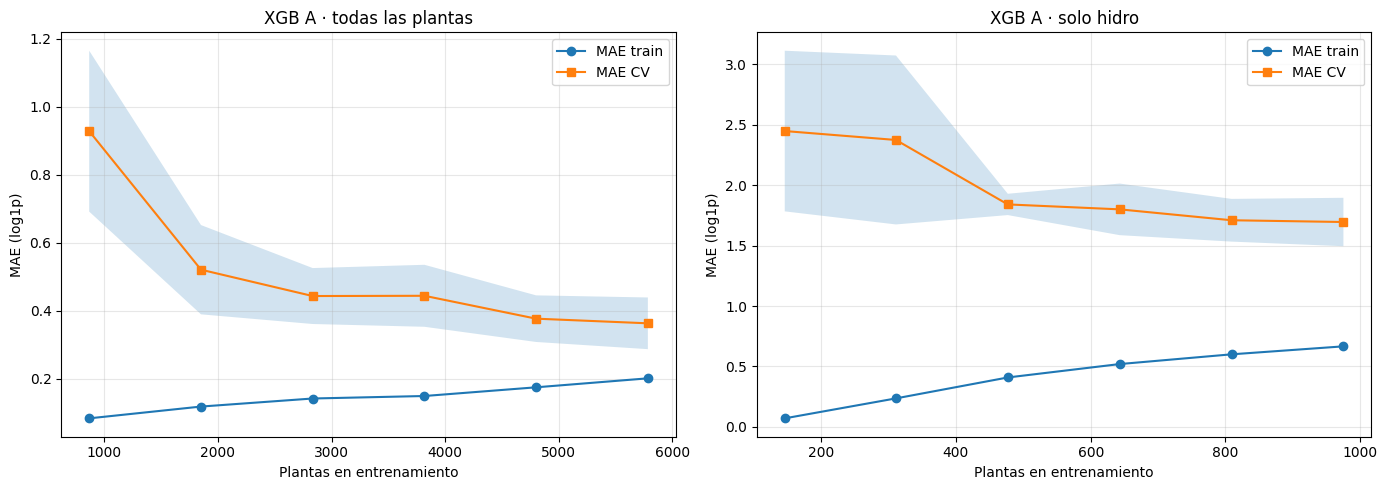

In [ ]:
# ============================================================
# CELDA 21 · Curvas de aprendizaje (solo train)
# ============================================================
from sklearn.model_selection import learning_curve
import matplotlib.pyplot as plt

(BASE / "figures").mkdir(exist_ok=True)


def diagnostico_curva(sizes, tr, va):
    """Diagnóstico basado en la TENDENCIA de las curvas, no en el gap puntual.

    Regímenes:
      - subajuste:        train sube, CV baja       → más datos ayudan
      - aprendizaje sano: train baja, CV baja       → régimen ideal
      - sobreajuste:      train baja, CV sube       → más datos empeoran
      - saturación:       train sube, CV estable    → cuello de botella en features
      - régimen mixto:    otras combinaciones
    """
    x = np.log(sizes)
    slope_tr = float(np.polyfit(x, tr, 1)[0])   # cambio por duplicación de datos
    slope_va = float(np.polyfit(x, va, 1)[0])

    def direccion(s):
        if s > 0.03:   return "sube"
        if s < -0.10:  return "baja fuerte"
        if s < -0.03:  return "baja"
        return "estable"

    d_tr, d_va = direccion(slope_tr), direccion(slope_va)

    if d_tr == "sube" and d_va in ("baja fuerte", "baja"):
        diag = "subajuste: train sube, CV baja — más datos ayudan"
    elif d_tr in ("baja", "baja fuerte") and d_va in ("baja", "baja fuerte"):
        diag = "aprendizaje sano: train y CV bajan — régimen ideal"
    elif d_tr in ("baja", "baja fuerte") and d_va == "sube":
        diag = "sobreajuste real: train baja, CV sube — más datos empeoran"
    elif d_tr == "sube" and d_va == "estable":
        diag = "saturación por features: CV no mejora con más datos, train no memoriza"
    elif d_tr == "estable" and d_va == "estable":
        diag = "saturación: ambas curvas planas"
    else:
        diag = f"régimen mixto (train {d_tr}, CV {d_va})"

    return slope_tr, slope_va, d_tr, d_va, diag


def curva(estimator, X, y, groups, cv, titulo, ax):
    sizes, tr_sc, va_sc = learning_curve(
        estimator, X, y, groups=groups, cv=cv,
        train_sizes=np.linspace(0.15, 1.0, 6),
        scoring="neg_mean_absolute_error", n_jobs=-1)
    tr, va = -tr_sc.mean(axis=1), -va_sc.mean(axis=1)
    tr_std, va_std = tr_sc.std(axis=1), va_sc.std(axis=1)

    ax.plot(sizes, tr, "o-", label="MAE train")
    ax.plot(sizes, va, "s-", label="MAE CV")
    ax.fill_between(sizes, va - va_std, va + va_std, alpha=0.2)
    ax.set_xlabel("Plantas en entrenamiento")
    ax.set_ylabel("MAE (log1p)")
    ax.set_title(titulo)
    ax.legend(); ax.grid(alpha=0.3)

    s_tr, s_va, d_tr, d_va, diag = diagnostico_curva(sizes, tr, va)
    print(f"\n=== {titulo} ===")
    print(f"sizes         : {sizes.astype(int).tolist()}")
    print(f"MAE train     : {np.round(tr, 3).tolist()}")
    print(f"MAE CV        : {np.round(va, 3).tolist()}")
    print(f"std CV        : {np.round(va_std, 3).tolist()}")
    print(f"pendiente log (train, CV): ({s_tr:+.3f}, {s_va:+.3f})")
    print(f"dirección (train, CV)    : ({d_tr}, {d_va})")
    print(f"gap final (CV − train)   : {va[-1] - tr[-1]:+.3f}")
    print(f"diagnóstico              : {diag}")


fig, axes = plt.subplots(1, 2, figsize=(14, 5))
curva(xgb_pipe(FEATS_A), X_train, y_tr_log, g_tr, cv,
      "XGB A · todas las plantas", axes[0])
h_tr = (X_train["fuel_group"] == "HYDRO").values
curva(xgb_pipe(FEATS_A), X_train[h_tr], y_tr_log[h_tr], g_tr[h_tr], cv,
      "XGB A · solo hidro", axes[1])
plt.tight_layout()
plt.savefig(BASE / "figures" / "learning_curves.png", dpi=150)
plt.show()

In [ ]:
# ============================================================
# CELDA 22 · Asimetría del error (FP/FN en regresión)
# ============================================================
# En regresión no hay FP/FN clásicos. Se traduce a:
# sobre-predicción (err>0) vs sub-predicción (err<0).
# Subestimar intensidad es el error peligroso para AWI.

err = preds["Ruteado final"] - y_te_log
grupos_te = X_test["fuel_group"].values
filas = []
for g in ["HYDRO","SOLAR","WIND","GAS","COAL","BIOMASS","OIL"]:
    m = grupos_te == g
    if m.sum() < 10: continue
    filas.append({
        "grupo": g, "n": int(m.sum()),
        "% sobre": round((err[m] > 0).mean() * 100, 1),
        "% sub":   round((err[m] < 0).mean() * 100, 1),
        "MAE sobre": round(err[m][err[m] > 0].mean(), 3) if (err[m] > 0).any() else np.nan,
        "MAE sub":   round(abs(err[m][err[m] < 0]).mean(), 3) if (err[m] < 0).any() else np.nan,
    })
tabla_err = pd.DataFrame(filas)
print("Asimetría del error por grupo (test, log1p):")
print(tabla_err.to_string(index=False))
tabla_err.to_csv(PROCESSED_DIR / "asimetria_error_test.csv", index=False)

Asimetría del error por grupo (test, log1p):
  grupo   n  % sobre  % sub  MAE sobre  MAE sub
  HYDRO 120     46.7   53.3      1.554    2.045
  SOLAR 220      0.0    0.0        NaN      NaN
   WIND 297      0.0    0.0        NaN      NaN
    GAS 193      8.8    7.8      0.105    0.482
   COAL  59     25.4   16.9      0.255    0.624
BIOMASS  71      1.4    0.0      0.294      NaN
    OIL 198      0.0    0.0        NaN      NaN


In [ ]:
# ============================================================
# CELDA 23 · Diagnóstico de sobreajuste/subajuste
# ============================================================
from sklearn.metrics import mean_absolute_error as mae

# --- 1) R² por fold HONESTO (out-of-fold, usa p_fin de CELDA 18) ---
r2_f = [r2_score(y_tr_log[va], p_fin[va]) for _, va in folds]
print(f"R² por fold (out-of-fold, honesto): {np.round(r2_f, 3)}")
print(f"Media: {np.mean(r2_f):.3f} | std: {np.std(r2_f):.3f}\n")

# --- 2) Preparar predicciones de train para cada modelo ---
b1_fit = DummyRegressor(strategy="mean").fit(X_train, y_tr_log)
b3_fit = MedianaPorCombustible().fit(X_train, y_tr_log)

# --- 3) Composición de los conjuntos ---
frac_h_train = h_tr.mean()
print("Composición de los conjuntos:")
print(f"  Train: {h_tr.sum()} hidro de {len(h_tr)} ({100*frac_h_train:.1f}%)")
print(f"  Test:  {hid_te.sum()} hidro de {len(hid_te)} ({100*hid_te.mean():.1f}%)\n")

# --- 4) Diagnóstico desagregado train vs test ---
print("Diagnóstico desagregado train vs test:")
print(f"{'modelo':<15} {'grupo':<12} {'train':>7} {'test':>7} {'gap':>8}")
print("-" * 57)

# (nombre, p_tr, p_te) — p_te viene como tercer elemento de la tupla
tripletas = [
    ("B1 media",   oof["B1 media"],             preds["B1 media"]),
    ("B3 mediana", oof["B3 mediana por fuel"],  preds["B3 mediana por fuel"]),
    ("Ruteado",    p_fin,                       preds["Ruteado final"]),
]
for nombre, p_tr, p_te in tripletas:
    # Global
    ma_tr_glob = mae(y_tr_log, p_tr)
    ma_te_glob = mae(y_te_log, p_te)
    # Hidro
    ma_tr_h = mae(y_tr_log[h_tr], p_tr[h_tr])
    ma_te_h = mae(y_te_log[hid_te], p_te[hid_te])
    # No-hidro
    ma_tr_nh = mae(y_tr_log[~h_tr], p_tr[~h_tr])
    ma_te_nh = mae(y_te_log[~hid_te], p_te[~hid_te])
    # Test re-ponderado a composición del train
    ma_te_rw = frac_h_train * ma_te_h + (1 - frac_h_train) * ma_te_nh

    print(f"{nombre:<15} {'global':<12} {ma_tr_glob:>7.3f} {ma_te_glob:>7.3f} {100*(ma_te_glob/ma_tr_glob-1):>+7.1f}%")
    print(f"{'':<15} {'hidro':<12} {ma_tr_h:>7.3f} {ma_te_h:>7.3f} {100*(ma_te_h/ma_tr_h-1):>+7.1f}%")
    print(f"{'':<15} {'no-hidro':<12} {ma_tr_nh:>7.3f} {ma_te_nh:>7.3f} {100*(ma_te_nh/ma_tr_nh-1):>+7.1f}%")
    if nombre == "Ruteado":     # el re-ponderado se reporta solo para el modelo final
        print(f"{'':<15} {'test re-pond.':<12} {ma_tr_glob:>7.3f} {ma_te_rw:>7.3f} {100*(ma_te_rw/ma_tr_glob-1):>+7.1f}%")

    print()


# --- 5) Gap en hidro (el número clave) ---
print(f"\nHidro (modelo final):")
ma_h_tr = mae(y_tr_log[h_tr], p_fin[h_tr])
ma_h_te = mae(y_te_log[hid_te], preds["Ruteado final"][hid_te])
print(f"  MAE train {ma_h_tr:.3f} | test {ma_h_te:.3f} | gap {100*(ma_h_te/ma_h_tr-1):+.1f}%")

R² por fold (out-of-fold, honesto): [0.216 0.42  0.454 0.342 0.468]
Media: 0.380 | std: 0.093

Composición de los conjuntos:
  Train: 1219 hidro de 7221 (16.9%)
  Test:  120 hidro de 1182 (10.2%)

Diagnóstico desagregado train vs test:
modelo          grupo          train    test      gap
---------------------------------------------------------
B1 media        global         0.687   0.650    -5.4%
                hidro          1.733   2.170   +25.2%
                no-hidro       0.475   0.478    +0.7%

B3 mediana      global         0.332   0.241   -27.3%
                hidro          1.833   2.198   +19.9%
                no-hidro       0.027   0.020   -24.7%

Ruteado         global         0.297   0.203   -31.8%
                hidro          1.626   1.816   +11.7%
                no-hidro       0.027   0.020   -24.7%
                test re-pond.   0.297   0.323    +8.9%


Hidro (modelo final):
  MAE train 1.626 | test 1.816 | gap +11.7%


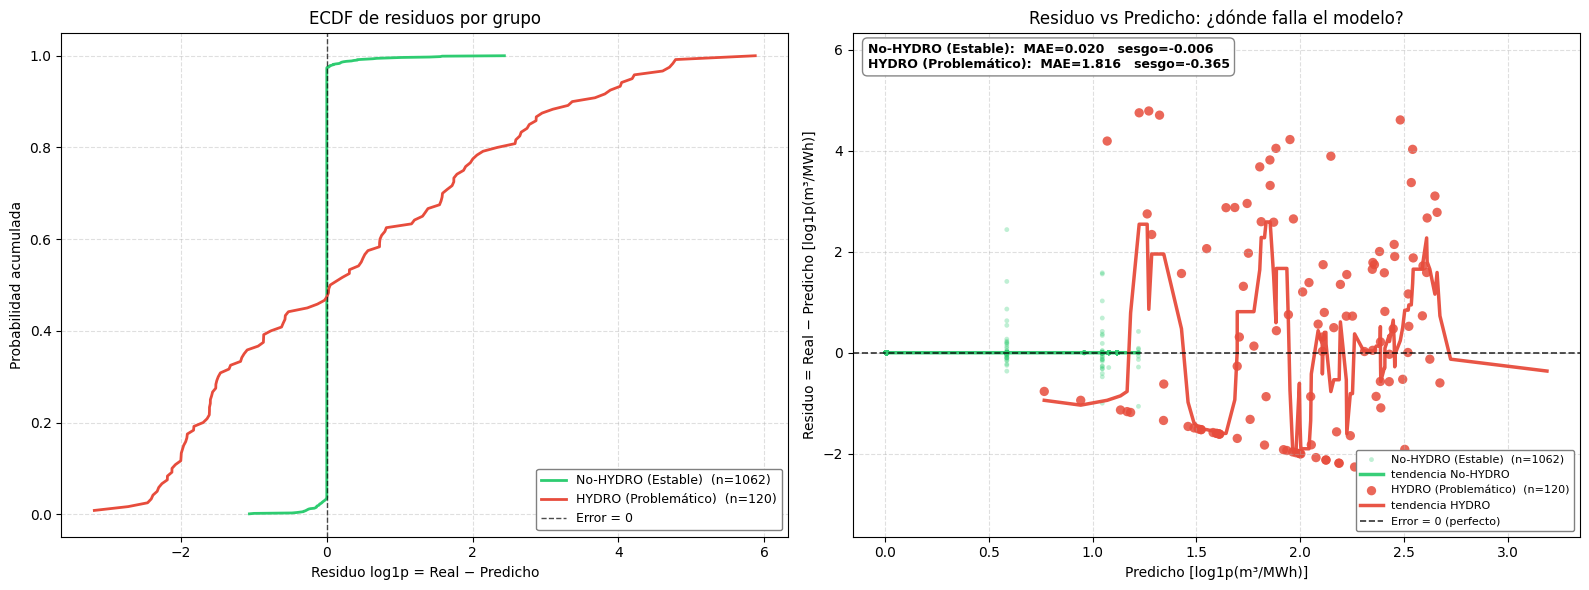

In [ ]:
# ============================================================
# CELDA 24 · ECDF + Residuo vs Predicho (test) — legible
# ============================================================
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error

grupos = [
    ("No-HYDRO (Estable)",    "#2ECC71"),
    ("HYDRO (Problemático)",  "#E74C3C"),
]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# ---------- Gráfico 1: ECDF de residuos ----------
ax = axes[0]
for grupo, color in grupos:
    sub = df_diag.loc[df_diag["Grupo Analizado"] == grupo, "residuo_log"].dropna()
    s = np.sort(sub.values)
    cdf = np.arange(1, len(s) + 1) / len(s)
    ax.plot(s, cdf, color=color, lw=2, label=f"{grupo}  (n={len(s)})")

ax.axvline(0, color="black", ls="--", lw=1, alpha=0.7, label="Error = 0")
ax.set_xlabel("Residuo log1p = Real − Predicho")
ax.set_ylabel("Probabilidad acumulada")
ax.set_title("ECDF de residuos por grupo")
ax.grid(True, ls="--", alpha=0.4)
ax.legend(loc="lower right", fontsize=9,
          facecolor="white", framealpha=1.0, edgecolor="gray")

# ---------- Gráfico 2: Residuo vs Predicho ----------
ax = axes[1]

# Scatter por grupo + línea de tendencia (rolling median)
for grupo, color, size, alpha in [
    ("No-HYDRO (Estable)",   "#2ECC71", 12, 0.30),
    ("HYDRO (Problemático)", "#E74C3C", 45, 0.85),
]:
    sub = (df_diag[df_diag["Grupo Analizado"] == grupo]
           .dropna(subset=["y_pred_log", "residuo_log"])
           .sort_values("y_pred_log"))

    ax.scatter(sub["y_pred_log"], sub["residuo_log"],
               c=color, s=size, alpha=alpha, edgecolors="none",
               label=f"{grupo}  (n={len(sub)})")

    # Línea de tendencia: revela sesgo sistemático a lo largo del rango
    if len(sub) >= 20:
        window = max(10, len(sub) // 25)
        roll = sub["residuo_log"].rolling(window=window, center=True,
                                          min_periods=1).median()
        ax.plot(sub["y_pred_log"], roll, color=color, lw=2.5, alpha=0.95,
                label=f"tendencia {grupo.split()[0]}")

# Referencia: error = 0
ax.axhline(0, color="black", ls="--", lw=1.2, alpha=0.8,
           label="Error = 0 (perfecto)")

# Stats en un único bloque opaco (sin solapamientos)
stats_lines = []
for grupo, _ in grupos:
    sub = df_diag[df_diag["Grupo Analizado"] == grupo]
    mae   = mean_absolute_error(sub["y_real_log"], sub["y_pred_log"])
    sesgo = (sub["y_pred_log"] - sub["y_real_log"]).mean()
    stats_lines.append(f"{grupo}:  MAE={mae:.3f}   sesgo={sesgo:+.3f}")

ax.text(0.02, 0.98, "\n".join(stats_lines),
        transform=ax.transAxes, va="top", ha="left",
        fontsize=9, fontweight="bold", color="black",
        bbox=dict(boxstyle="round,pad=0.4",
                  facecolor="white", edgecolor="gray", alpha=0.95))

ax.set_xlabel("Predicho [log1p(m³/MWh)]")
ax.set_ylabel("Residuo = Real − Predicho [log1p(m³/MWh)]")
ax.set_title("Residuo vs Predicho: ¿dónde falla el modelo?")
ax.grid(True, ls="--", alpha=0.4)
ax.legend(loc="lower right", fontsize=8,
          facecolor="white", framealpha=1.0, edgecolor="gray")

plt.tight_layout()
plt.show()


SHAP · modelo de hidro (final): importancia SHAP media |valor| por variable original
lon                        0.5101
bws_score                  0.1754
lat                        0.1329
cf_aware                   0.1288
capacity_mw                0.0680
capacity_factor            0.0599
net_generation_mwh         0.0583
n_generadores              0.0456
cool_hibrido               0.0000
cool_sin_registro          0.0000
cool_seco                  0.0000
cool_recirculacion         0.0000
cool_otro                  0.0000
fuel_group                 0.0000
fuel                       0.0000
cool_un_paso               0.0000
n_sistemas_enfriamiento    0.0000


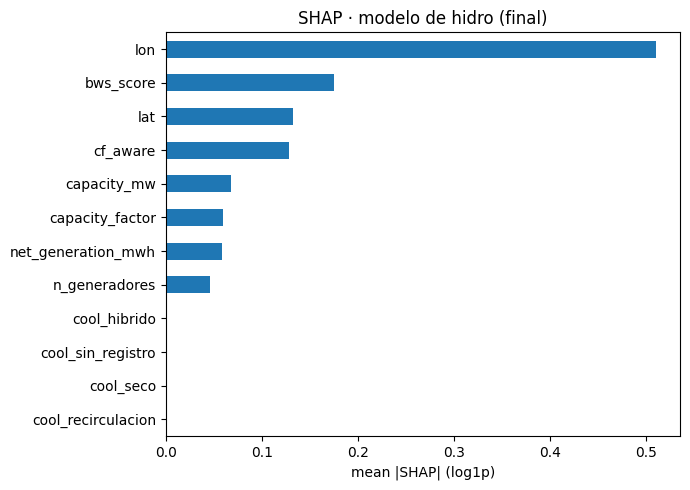

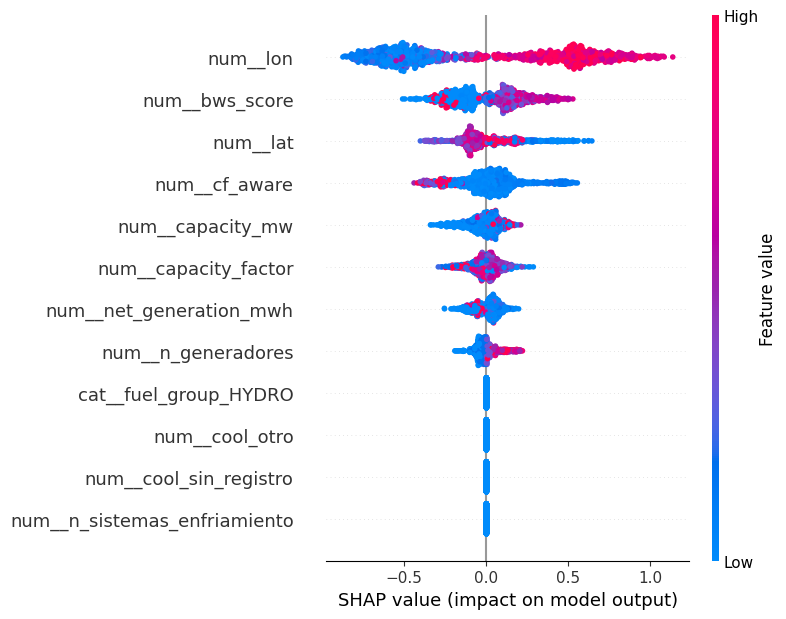

In [ ]:
# ============================================================
# CELDA 25 · SHAP (solo train; el test no se usa)
# ============================================================
import shap
import matplotlib.pyplot as plt
(BASE / "figures").mkdir(exist_ok=True)
cats = [c for c in FEATS_A if c in roles["features_categoricas"]]


def feature_original(nombre):
    """Vuelve de 'cat__fuel_group_HYDRO' a 'fuel_group' para sumar las columnas one-hot."""
    if nombre.startswith("num__"):
        return nombre[5:]
    n = nombre[5:]
    return max((c for c in cats if n.startswith(c + "_")), key=len)


def shap_agregado(pipe, X, titulo, archivo):
    prep, modelo = pipe.named_steps["prep"], pipe.named_steps["m"]
    Xt = prep.transform(X)
    nombres = prep.get_feature_names_out()
    sv = shap.TreeExplainer(modelo).shap_values(Xt)
    imp = pd.Series(np.abs(sv).mean(axis=0), index=nombres)
    por_feat = imp.groupby([feature_original(n) for n in nombres]).sum().sort_values(ascending=False)
    print(f"\n{titulo}: importancia SHAP media |valor| por variable original")
    print(por_feat.round(4).to_string())
    ax = por_feat.head(12)[::-1].plot.barh(figsize=(7, 5), title=titulo)
    ax.set_xlabel("mean |SHAP| (log1p)")
    plt.tight_layout(); plt.savefig(BASE / "figures" / archivo, dpi=150); plt.show()
    shap.summary_plot(sv, Xt, feature_names=nombres, max_display=12, show=False)
    plt.tight_layout(); plt.savefig(BASE / "figures" / ("beeswarm_" + archivo), dpi=150); plt.show()


# A) Modelo final (su parte de hidro), con las represas de train
h_tr = (X_train["fuel_group"] == "HYDRO").values
shap_agregado(modelo_final.hidro_, X_train[h_tr], "SHAP · modelo de hidro (final)", "shap_hidro.png")


In [ ]:
# ============================================================
# CELDA 26 · Control de calidad del SHAP de hidro: grupos, held-out y prueba de la hipótesis sobre `lon`
# DIAGNÓSTICO POST-HOC: usa el test solo para leer; NO cambia el modelo. Declararlo así en la Metodología.
# Reutiliza: modelo_final, feature_original (celda 25), X_train, X_test, y_tr_log, y_te_log, hid_tr, hid_te,
#            preds (celda 19).
# ============================================================
import shap
from scipy.stats import spearmanr
from sklearn.metrics import roc_auc_score

GRP_UBIC = ["lon", "lat", "bws_score", "cf_aware"]   # constantes por ubicación / cuenca (bws y cf NO son "física de la planta")
GRP_FIS  = ["capacity_mw", "capacity_factor", "net_generation_mwh", "n_generadores"]

def shap_hidro(X):
    """SHAP del componente de hidro, sumado por variable original. Devuelve (DataFrame, valor base)."""
    prep, mod = modelo_final.hidro_.named_steps["prep"], modelo_final.hidro_.named_steps["m"]
    expl = shap.TreeExplainer(mod)
    sv = expl.shap_values(prep.transform(X))
    cols = [feature_original(n) for n in prep.get_feature_names_out()]
    df_sv = pd.DataFrame(sv, columns=cols, index=X.index).T.groupby(level=0).sum().T
    return df_sv, float(np.ravel(expl.expected_value)[0])

def cuota(df_sv, grupo):
    imp = df_sv.abs().mean()
    return imp[[c for c in grupo if c in imp.index]].sum() / imp.sum()

# --- 1) Cuota de ubicación vs física: train vs test (held-out) y chequeo del valor base ---------
sv_tr, base = shap_hidro(X_train[hid_tr])
sv_te, _    = shap_hidro(X_test[hid_te])
print(f"1) Valor base SHAP = {base:.3f} | media de hidro en train = {y_tr_log[hid_tr].mean():.3f}")
print(pd.DataFrame({"train (n=%d)" % len(sv_tr): [cuota(sv_tr, GRP_UBIC), cuota(sv_tr, GRP_FIS)],
                    "test (n=%d)"  % len(sv_te): [cuota(sv_te, GRP_UBIC), cuota(sv_te, GRP_FIS)]},
                   index=["ubicación", "física de planta"]).round(3).to_string())
print("   Si la cuota de ubicación cae mucho en test, el modelo usa la ubicación de forma distinta fuera de train.")

# --- 2) Hipótesis: el SHAP de ubicación sigue la tasa regional de CEROS (artefacto de Siddik) ----
d4 = X_train[hid_tr].assign(shap_ubic=sv_tr[[c for c in GRP_UBIC if c in sv_tr.columns]].sum(axis=1).values,
                            cero=(y_tr_log[hid_tr] == 0))
print("\n2) Hidro en train: SHAP de ubicación vs % de ceros por región (n >= 10)")
for nivel in ["state", "ba_code"]:
    g = d4.groupby(nivel).agg(n=("cero", "size"), pct_ceros=("cero", "mean"), shap_ubic=("shap_ubic", "mean"))
    g = g[g["n"] >= 10]
    rho, pval = spearmanr(g["pct_ceros"], g["shap_ubic"])
    print(f"   {nivel:8s}: {len(g)} regiones | Spearman(% ceros, SHAP ubicación) = {rho:+.2f} (p={pval:.3f})")
print("   rho fuertemente negativo → la 'ubicación' del modelo codifica la tasa de ceros de cada región")
print("   (cómo se construyó el dato), no estrés hídrico ni física. rho ≈ 0 → hipótesis descartada.")

# --- 3) ¿Distingue el modelo los ceros de los no-ceros? ------------------------------------------
y_h, p_h = y_te_log[hid_te], preds["Ruteado final"][hid_te]
auc = roc_auc_score(y_h == 0, -p_h)
print(f"\n3) AUC para separar ceros de no-ceros en hidro (test): {auc:.3f}   (0.5 = azar)")


1) Valor base SHAP = 1.738 | media de hidro en train = 1.749
                  train (n=1219)  test (n=120)
ubicación                  0.803         0.793
física de planta           0.197         0.207
   Si la cuota de ubicación cae mucho en test, el modelo usa la ubicación de forma distinta fuera de train.

2) Hidro en train: SHAP de ubicación vs % de ceros por región (n >= 10)
   state   : 26 regiones | Spearman(% ceros, SHAP ubicación) = -0.77 (p=0.000)
   ba_code : 24 regiones | Spearman(% ceros, SHAP ubicación) = -0.62 (p=0.001)
   rho fuertemente negativo → la 'ubicación' del modelo codifica la tasa de ceros de cada región
   (cómo se construyó el dato), no estrés hídrico ni física. rho ≈ 0 → hipótesis descartada.

3) AUC para separar ceros de no-ceros en hidro (test): 0.675   (0.5 = azar)


**Revisión de la atribución SHAP del modelo final de hidro en las celdas 25 y 26**

Los valores SHAP se calcularon en escala `log1p` con TreeExplainer y se sumaron por variable original. Las variables se agrupan en ubicación (`lon`, `lat`, `bws_score`, `cf_aware`, que son constantes por ubicación o cuenca y no características de la planta) y física de la planta (`capacity_mw`, `capacity_factor`, `net_generation_mwh`, `n_generadores`). Los gráficos muestran que la ubicación concentra alrededor de 80 % de la atribución, con `lon` 0.51, `bws_score` 0.18, `lat` 0.13 y `cf_aware` 0.13, mientras que la física de la planta explica alrededor de 20 %. Las variables de enfriamiento y de combustible valen 0.000 porque las represas no tienen sistema de enfriamiento y comparten combustible. En el beeswarm, `lon` es casi monótono de oeste a este, y `bws_score` y `cf_aware` tienen signos SHAP opuestos, lo que indica colinealidad y no un efecto físico del estrés hídrico. La correlación de Spearman de `lon` con el target en hidro es 0.296 y la de las variables físicas es menor que 0.15, celda 11.

El control de calidad de la celda 26 deja tres resultados. Primero, la proporción de atribución de ubicación se mantiene fuera de train, con 80.3 % en train y 79.3 % en las 120 represas de test, y el valor base SHAP de 1.738 coincide con la media de hidro en train de 1.749. Segundo, se confirma la hipótesis de que `lon` codifica la tasa regional de ceros del target como artefacto de construcción del dato de la celda 12, ya que la Spearman entre el % de ceros por región y el SHAP medio de ubicación es −0.77 por estado con 26 regiones y −0.62 por BA con 24 regiones, con p ≤ 0.001. Tercero, el AUC para separar ceros de no-ceros en test es 0.675, una señal modesta.

El modelo usa la ubicación para estimar la tasa regional de ceros, no el estrés hídrico ni la física del embalse. Este es el hallazgo que cambia la interpretación, porque sin este control “la ubicación importa” se leería como un efecto físico que los datos no respaldan. Conviene mantener cautela porque son pocas regiones y el SHAP por región se calculó en train.

In [ ]:
# CELDA 27 · Diagnóstico post-hoc (NO cambia el modelo; declarar como análisis posterior al test)
y_h = y_te_log[hid_te]
media_h = y_tr_log[hid_tr].mean()                    # media de log1p de las represas de TRAIN
const = np.full(len(y_h), media_h)
pr_h = preds["Ruteado final"][hid_te]
print(f"Constante (media de hidro en train = {media_h:.3f}): MAE {mean_absolute_error(y_h, const):.3f} | R2 {r2_score(y_h, const):+.3f}")
print(f"Ruteado final                                    : MAE {mean_absolute_error(y_h, pr_h):.3f} | R2 {r2_score(y_h, pr_h):+.3f}")
print(f"Desv. estándar en hidro (log1p): reales {y_h.std():.3f} | predichas por el ruteado {pr_h.std():.3f}")
print(f"B3 predice en hidro (log1p): {preds['B3 mediana por fuel'][hid_te].mean():.3f}")

Constante (media de hidro en train = 1.749): MAE 1.929 | R2 -0.086
Ruteado final                                    : MAE 1.816 | R2 -0.011
Desv. estándar en hidro (log1p): reales 2.153 | predichas por el ruteado 0.453
B3 predice en hidro (log1p): 0.542


## 6.1 · Justificación de métricas

El problema es de regresión. Las métricas de clasificación como accuracy, precisión, recall y F1 no corresponden y no se reportan. El target es *y_water_intensity* (WUE_off) en m³/MWh, con rango de 0 a 22 346, mediana 0.008, percentil 90 en 2.39 y percentil 99 en 326.9. Esa distribución tiene dos grupos casi deterministas (solar y eólica cerca de 0.008 m³/MWh) y una cola hidroeléctrica que domina la varianza. Esa estructura impone tres decisiones metodológicas.

**Transformación log1p.** En escala original, el error de tres o cuatro represas con intensidades entre 1 000 y 22 000 m³/MWh dominaría cualquier métrica. Un modelo que las ignore parecería aceptable. log1p comprime la cola, deja el target en el rango de 0 a 10 y hace que todos los grupos contribuyan al R². Pero log1p no es la escala del target, así que se reporta además el MAE en m³/MWh para dar una idea del error en unidades físicas.

**MAE y RMSE.** El MAE es robusto a outliers. El RMSE castiga más los errores grandes y complementa al MAE al detectar fallas sistemáticas en los extremos. Reportar ambas métricas evita el sesgo de una sola. Se acompañan con R² como medida de varianza explicada y con la desagregación por fuel_group, porque el comportamiento del error es estructuralmente distinto entre grupos.

**Tres baselines como referencia.** B1 (media) responde a la pregunta de si el modelo aprende algo. B2 (Ridge con las 17 variables del conjunto A) responde a si el problema justifica un modelo no lineal. B3 (mediana por combustible, con respaldo a fuel_group y luego a la mediana global) replica el estándar de la industria y responde a si vale la pena la complejidad sobre la regla de consulta. B3 es el baseline más exigente porque la tecnología concentra casi toda la señal predictiva (sección 7.8) y ese baseline ya la captura sin aprender nada.

## 6.2 · Resultados en test frente a los tres baselines

Los resultados finales sobre el conjunto de prueba (8 estados no vistos, IA, LA, ME, MN, NE, OH, RI y TN; 1 182 plantas, de las cuales 120 son hidroeléctricas) se resumen en la Tabla

| Modelo | R² | RMSE | MAE | MAE no-hidro | MAE hidro |
|---|---|---|---|---|---|
| B1 media | −0.001 | 1.017 | 0.650 | 0.478 | 2.170 |
| B2 Ridge | 0.490 | 0.726 | 0.276 | 0.093 | 1.900 |
| B3 mediana por fuel | 0.196 | 0.912 | 0.241 | **0.020** | 2.198 |
| **Ruteado final** | **0.523** | **0.702** | **0.203** | **0.020** | **1.816** |

El modelo principal le gana a los tres baselines en las métricas globales. El R² es 0.523 frente a 0.490 de B2, 0.196 de B3 y −0.001 de B1. En RMSE la comparación es 0.702 frente a 0.726, 0.912 y 1.017. En MAE global es 0.203 frente a 0.276, 0.241 y 0.650. La mejora es consistente. El criterio R² ≥ 0.70 que la Etapa 1 declaró como éxito quedó por debajo del objetivo. El resultado honesto es 0.523.

## 6.3 · Dónde está y dónde no está la ganancia

Conviene descomponer el resultado del modelo para una mejor comprensión. En el subconjunto no hidroeléctrico el ruteado empata con B3 (MAE 0.020 en ambos). Por diseño, el ruteado usa la mediana por combustible para todo lo que no es hidro. La contribución real del ML se concentra en hidro. Allí el MAE es 1.816 frente a 2.198 de B3 (17.4 % de mejora) y frente a 1.900 de B2 (4.4 %). B3 predice 0.542 en hidro y queda peor que la constante (1.929), así que la referencia real es la constante (5.9 %).

Esa mejora del 17 % es menos impresionante de lo que parece cuando se mira el R². El R² en hidro del ruteado en test es −0.011, esencialmente cero. El modelo no explica la varianza del target dentro del grupo. La comparación post-hoc con un predictor constante (la media de hidro en train, log1p = 1.749) lo confirma. La constante obtiene MAE 1.929 y el ruteado 1.816. La mejora es de 5.9 %. Además, la desviación estándar de las predicciones del ruteado sobre las 120 represas es 0.453, mientras que la desviación estándar de los valores reales es 2.153. El modelo prácticamente no se mueve de la media. El poco movimiento que hay explica una fracción mínima del error.

En resumen, el modelo gana globalmente porque replica el baseline de literatura en no hidro, que ya es muy fuerte, y en hidro apenas bate al predictor constante. Como sistema es defendible. Como avance sustancial sobre el estado del arte, no. Esa distinción hay que declararla.

## 6.4 · Desempeño por grupo de combustible

La Tabla 6.2 muestra el MAE (log1p) por grupo en test, solo grupos con al menos 50 plantas.

| Grupo | B1 media | B2 Ridge | B3 mediana | Ruteado final |
|---|---|---|---|---|
| BIOMASS | 0.439 | 0.086 | 0.004 | 0.004 |
| COAL | 0.475 | 0.278 | 0.171 | 0.171 |
| GAS | 0.088 | 0.119 | 0.047 | 0.047 |
| **HYDRO** | 2.170 | 1.900 | 2.198 | **1.816** |
| OIL | 0.485 | 0.098 | 0.000 | 0.000 |
| SOLAR | 0.627 | 0.074 | 0.000 | 0.000 |
| WIND | 0.631 | 0.042 | 0.000 | 0.000 |

La estructura del error es muy informativa. Solar, eólica y las plantas de petróleo con un único tipo de combustible se predicen exactamente con la mediana por combustible (MAE 0.000). Son deterministas por construcción. Gas, biomasa y carbón tienen error bajo con el ruteado. Todo el error restante se concentra en hidro. De las 20 peores predicciones en el test, las 20 son hidroeléctricas y en conjunto aportan el 83 % del error absoluto total del modelo. En escala original, el MAE global del ruteado es 8.36 m³/MWh con mediana de error absoluto de 0.000. La mayoría de las plantas se predicen prácticamente exactas. El MAE en no hidro es de apenas 0.080 m³/MWh.

## 6.5 · Análisis de errores y casos límite

**Asimetría del error en test.** En hidro, el modelo sobre-predice en 46.7 % de los casos y sub-predice en 53.3 %. El MAE de la sobre-predicción es 1.554 y el de la sub-predicción es 2.045. No hay sesgo sistemático. Hay ausencia de señal. Subestimar la intensidad hídrica es el error más peligroso para el AWI porque subestima el impacto ambiental. Por eso el sesgo hacia abajo en magnitud es la parte más preocupante del resultado.

**Los cinco peores casos, todos hidro.** Con identificadores 785, 3421, 50999, 50636 y 2268, el error va de 424 a 1 587 m³/MWh. El modelo predice entre 2.6 y 11.7. El valor real está entre 426 y 1 590. Son subestimaciones de 60 a 461 veces. Estos casos aportan el 83 % del error absoluto total en m³/MWh, escala relevante para el AWI porque es lineal en el agua. En log1p el MAE de hidro es 1.816.

**Variabilidad entre estados del test.** El MAE (log1p) del ruteado por estado de test es altamente heterogéneo. TN 0.886, ME 0.636, NE 0.267, MN 0.141, LA 0.112, OH 0.079, IA 0.039 y RI 0.019. Los dos peores (TN y ME) son precisamente los estados con más carga hidroeléctrica en el test (28 y 49 represas respectivamente). Esto anticipa lo que se discutirá en 6.7. El modelo no extrapola a regiones nuevas.

**Análisis del comportamiento de las peores plantas.** La Tabla 6.3 muestra las 5 peores predicciones en m³/MWh.

| plant_id | state | y_true | y_pred | err_m3 |
|---|---|---|---|---|
| 785 | NE | 1 590.09 | 3.45 | 1 586.64 |
| 3421 | TN | 1 201.33 | 10.98 | 1 190.36 |
| 50999 | ME | 711.86 | 11.71 | 700.14 |
| 50636 | MN | 477.97 | 6.04 | 471.93 |
| 2268 | NE | 426.08 | 2.56 | 423.51 |

Lo relevante es por qué falla. En lugar de equivocarse de magnitud, se mantiene cerca del valor medio. En escala log1p, el valor real está en 6.1 a 7.4, el modelo predice 1.3 a 2.6 y la media de hidro en train es 1.749. En dos de esos cinco casos el modelo se mueve incluso en la dirección opuesta a la realidad.

## 6.6 · Diagnóstico de sobreajuste y subajuste

**Curvas de aprendizaje.** Se calcularon sobre train para XGBoost directo (todas las plantas) y XGBoost restringido a hidro, con las mismas particiones agrupadas por state. En ambos casos el diagnóstico es el mismo, subajuste y no sobreajuste.

XGB directo. El MAE train sube de 0.083 a 0.201. El MAE CV baja de 0.928 a 0.363. El modelo aprende cada vez más despacio y generaliza cada vez mejor. Es la firma del subajuste, no del sobreajuste.

XGB hidro. El MAE train sube de 0.070 a 0.666. El MAE CV baja de 2.449 a 1.696. El patrón es idéntico.

Ninguna de las dos curvas muestra el patrón clásico de sobreajuste, con train baja y CV sube. Con 7 221 plantas de entrenamiento, el tamaño de datos no es el problema. El problema es que no hay más señal física disponible para hidro. Agregar plantas no va a bajar el MAE de CV.

**R² out-of-fold por fold.** El R² de la validación cruzada honesta (out-of-fold, con p_fin de la Celda 18) es [0.216, 0.420, 0.454, 0.342, 0.468], con media 0.380 y desviación estándar 0.093. El 0.408 de la tabla de CV es el R² sobre todas las predicciones out-of-fold juntas, no el promedio por fold. Es estable, sin un fold que se comporte dramáticamente peor, pero modesto.

**Gap train vs test.** El MAE global de train del ruteado es 0.297 y el de test es 0.203, un 31.8 % menor en test. Un gap negativo de ese tamaño parece sospechoso. La explicación es que el test tiene proporcionalmente menos hidro, 10.2 % frente al 16.9 % de train. Re-ponderando el MAE de test a la composición del train (fracción hidro = 0.169), el MAE test re-ponderado es 0.323, un 8.9 % por encima del train. Ese es el gap real, generalización correcta sin sobreajuste. En hidro específicamente, el gap es +11.7 % (train 1.626, test 1.816), modesto y esperable al cambiar de estados.

En resumen, el modelo no sobreajusta. El diagnóstico es que la componente hidro está subajustada y que las features disponibles no contienen la señal física necesaria para predecir intensidades hídricas individuales de represas. Esto conecta directamente con la sección 6.7.

## 6.7 · Control de calidad con SHAP

**Alcance.** SHAP (TreeExplainer, escala log1p) sobre el componente de hidro del modelo final, con las represas de train (celda 25) y, como lectura posterior que no ajusta nada, con las 120 represas de test (celda 26). Las variables se agrupan en ubicación (lon, lat, bws_score, cf_aware) y física de la planta (capacity_mw, capacity_factor, net_generation_mwh, n_generadores).

**Atribución.** La ubicación pesa 80.3 % en train y 79.3 % en test, y la física cerca de 20 %. Las variables de enfriamiento y de combustible valen 0.000 porque las represas no tienen sistema de enfriamiento y comparten combustible. El valor base SHAP (1.738) coincide con la media de hidro en train (1.749). El beeswarm de lon es casi monótono de oeste a este, y bws_score y cf_aware empujan en sentidos opuestos, lo que apunta a colinealidad y no a un efecto físico.

**Hallazgo de control de calidad.** La ubicación que usa el modelo codifica un artefacto regional de los datos. El 45.2 % de las represas de train valen exactamente 0 según el método de Siddik et al. (celda 12), y esa tasa de ceros cambia por región. El Spearman entre el % de ceros de la región y el SHAP medio de ubicación es −0.77 por estado (26 regiones) y −0.62 por BA (24 regiones), con p ≤ 0.001. El modelo usa la ubicación para adivinar la tasa de ceros de la región, no el estrés hídrico ni la física del embalse. El AUC para separar ceros de no-ceros en test es 0.675, señal modesta. Sin este control, la atribución SHAP se habría leído como "la ubicación importa por física", que es falso. Cautela: son pocas regiones y el SHAP por región se calculó en train.

**Consistencia con la ablación.** En la ablación de la sección 7, quitar toda la ubicación empeora el MAE de hidro en +0.176 con state y +0.173 con ba_code (7.7), y SHAP confirma que el modelo la usa. Que la ubicación ayude en la CV es compatible con que lo que aprende sea la tasa regional de ceros.

**Qué sí está demostrado.** En test, hidro tiene R² = −0.011, desviación de las predicciones 0.453 frente a 2.153 reales y un MAE de 1.816 frente a 1.929 de una constante, una mejora de 5.9 % (celda 27). En la CV de la ablación, XGBoost en hidro mejora el MAE frente a la constante en +0.190 (IC95 % [+0.146, +0.233]) con state y +0.181 con ba_code (7.7). La señal en hidro es débil, y lo aprendido es en gran parte el artefacto regional de ceros.

## 6.8 · Limitaciones

1. El criterio de éxito de la Etapa 1 no se cumple. El R² ≥ 0.70 declarado como objetivo del sistema no se alcanzó. El resultado en test es 0.523. El modelo es defendible, pero no como avance sustancial sobre el estado del arte en la predicción de intensidad hídrica.

2. La componente hidro explica casi nada de la varianza. R² = −0.011 en test y mejora de apenas 5.9 % sobre una constante (MAE 1.816 frente a 1.929). En la CV de la ablación (sección 7) la ganancia sobre la constante es +0.190 con state y +0.181 con ba_code. Lo que aprende es en gran parte la tasa regional de ceros del artefacto de Siddik et al. (Spearman −0.77 con el SHAP de ubicación).

3. La CV por state, y por ba_code en la ablación, puede ser optimista: no retira regiones enteras, state y ba_code no están anidados (un estado puede repartirse entre BA) y los hiperparámetros se ajustaron con folds por state. La validación con bloques espaciales no forma parte de este análisis; se reporta en el notebook de mejoras.

4. El desbalance estructural del target no se puede corregir con más datos del mismo tipo. El 45.2 % de las plantas hidro en train valen exactamente 0. Es un artefacto del método de Siddik et al. para asignar intensidad a represas, no un valor físico real. El 32 % de las represas en test valen 0. Este artefacto no se puede eliminar sin cambiar de fuente de datos y condiciona que cualquier modelo que aprenda el target log1p se comporte como un predictor cercano a la media en hidro.

5. El WUE_off cercano a 0 de regiones hidroeléctricas sube artificialmente al ranking del SCARF. Como se señala en el notebook 01, 590 plantas hidroeléctricas tienen intensidad exactamente 0 por el artefacto, y eso favorece a las regiones con más hidro. Conviene aclararlo cuando se muestren los rankings.

6. Solo 56 de 69 regiones del SCARF tienen todas las piezas. Falta WSF o WUE_off en 13. Los rankings deben reportarse sobre las 56 completas y declarar la cobertura.

7. El modelo principal se congeló sobre el split por state. Los resultados de test (R² 0.523) ya están calculados sobre ese esquema; la ablación (sección 7) muestra un desempeño similar bajo ba_code.

8. El modelo en log1p subestima la media en hidro: los casos extremos de 6.5 son subestimaciones de 60 a 461 veces. Se reporta el MAE en log1p y en m³/MWh, y el sesgo no se corrige en esta etapa. Si el SCARF va a consumir estas predicciones, debe corregirse antes (el notebook de mejoras).

## 6.9 · Síntesis

El modelo principal le gana a los tres baselines en las métricas globales (R² 0.523 frente a 0.490, 0.196 y −0.001), pero esa ventaja es el baseline de literatura replicado fuera de hidro más una mejora pequeña dentro de hidro (MAE 1.816 frente a 1.929 de una constante, 5.9 %). Lo defendible es lo siguiente. (i) La ablación (sección 7) muestra que la tabla de consulta por combustible explica cerca de 90 a 97 % de la mejora de MAE sobre la media, y que XGBoost en hidro, Optuna y la ubicación aportan de forma pequeña pero consistente en la CV. (ii) En hidro el modelo se apoya en variables de ubicación (≈ 80 % de la atribución SHAP, estable en train y test) que siguen la tasa regional de ceros del artefacto de Siddik et al. (Spearman −0.77). (iii) Las curvas de aprendizaje indican subajuste de la componente hidro, no sobreajuste. (iv) El criterio R² ≥ 0.70 no se alcanza. Las limitaciones (6.8) incluyen el artefacto de ceros, el posible optimismo de la CV por state y el sesgo hacia abajo en escala original, que no se corrige en esta etapa.


# 7 · Estudio de ablación

**Objetivo.** Medir la contribución real de cada componente del pipeline final quitándolo (o añadiéndolo) de a uno, manteniendo todo lo demás igual. Responde a: ¿qué parte del desempeño se debe a la tabla de consulta, al ruteo, a XGBoost en hidro, a Optuna, al `log1p`, al preprocesamiento y a cada familia de variables (cada una proviene de una fuente de datos distinta)?

## 7.1 · Diseño

| Componente | Variante "sin el componente" | Pregunta que responde |
|---|---|---|
| Hiperparámetros (Optuna) | parámetros por defecto | ¿Vale la pena el ajuste? |
| XGBoost en hidro | constante = media de hidro del train | ¿Aprende algo más que la media? |
| No linealidad | Ridge en hidro | ¿Se necesita un modelo de árboles? |
| Ruteo | XGBoost directo con todas las plantas | ¿Sirve separar hidro del resto? |
| Granularidad de la tabla de consulta | mediana por `fuel_group` en vez de por `fuel` | ¿Importa distinguir los 33 combustibles? |
| Transformación `log1p` | hidro entrenado con el target crudo | ¿El `log1p` ayuda o solo cambia la escala de la métrica? |
| Escalado / imputación | sin `StandardScaler` / NaN nativo de XGBoost | ¿El preprocesamiento aporta con árboles? |
| Variables: coordenadas (Siddik T2) | sin `lat`, `lon` | |
| Variables: `bws_score` (WRI Aqueduct) | sin `bws_score` | |
| Variables: `cf_aware` (Siddik T5) | sin `cf_aware` | |
| Variables: ubicación completa | sin `lat`, `lon`, `bws_score`, `cf_aware` | ¿Cuánto vale toda la ubicación? |
| Variables: física de la planta (eGRID) | sin capacidad, factor de planta, generación neta, n.º de generadores | |
| Variables: enfriamiento (EIA-860) | sin `cool_*` ni `n_sistemas_enfriamiento` | |

Se hacen dos lecturas complementarias: **quitar uno** desde el modelo final, y **construir** una escalera acumulativa B1 → B3 → +hidro constante → +XGBoost (defecto) → +Optuna.

## 7.2 · Protocolo

- **Solo train.** El test ya se consumió; aquí se usa únicamente de forma descriptiva (7.6), sin tomar decisiones con él.
- **20 particiones** `GroupShuffleSplit` (20 % de grupos fuera, semilla 2053) por `state` y por `ba_code`. Las mismas particiones para todas las variantes: la comparación es **pareada**. Se descartan particiones con menos de 15 represas en validación.
- **Un solo modelo con interruptores** (`PipelineAblation`): con los valores por defecto reproduce el modelo final, de modo que cada variante cambia una sola cosa.
- **Métricas:** MAE y R² en `log1p`; MAE en hidro y no-hidro; MAE de hidro en m³/MWh; razón entre la media predicha y la real en hidro (sesgo hacia abajo).
- **Veredicto** (positivo = el componente ayuda): *aporta* si el IC95 % bootstrap de la ganancia de MAE global es > 0 y al menos el 75 % de las particiones va en esa dirección; *estorba* si ocurre lo contrario; *sin efecto detectable* en los demás casos.

**Limitaciones.** (i) Las particiones se solapan, así que los IC son optimistas. (ii) Los hiperparámetros se ajustaron con todas las variables y con folds por `state`: ligera ventaja para el modelo completo al quitar variables sin reajustar. (iii) La ablación mide contribución *en este dataset*, incluido su artefacto de ceros en hidro, no importancia causal. (iv) El `log1p` cambia la escala de la métrica: por eso se reportan también el MAE en m³/MWh y la razón de medias.


## 7.3 · Implementación (celda 28)

In [ ]:
# ============================================================
# CELDA 28 · Pipeline con interruptores, métricas y utilidades de la ablación (solo train)
# Reutiliza: roles, FEATS_A, PARAMS_HIDRO (celda 18), PARAMS_DEFECTO (celda 17), MedianaPorCombustible,
#            X_train, y_tr_log, hid_tr, PROCESSED_DIR.
# ============================================================
import numpy as np, pandas as pd
import xgboost as xgb
from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import r2_score, mean_absolute_error
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler


def make_prep_var(feats, escalar=True, imputar=True):
    """Igual que make_prep, con interruptores para quitar el escalado y/o la imputación numérica."""
    num = [c for c in roles["features_numericas"] if c in feats]
    cat = [c for c in roles["features_categoricas"] if c in feats]
    pasos = ([("imp", SimpleImputer(strategy="median"))] if imputar else []) + \
            ([("sc", StandardScaler())] if escalar else [])
    return ColumnTransformer([
        ("num", Pipeline(pasos) if pasos else "passthrough", num),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="constant", fill_value="missing")),
                          ("oh", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), cat)])


class PipelineAblation(BaseEstimator, RegressorMixin):
    """Pipeline final con interruptores. Con los valores por defecto == RuteadoFinal (celda 18).
    ruteo     : True  -> lookup fuera de hidro + modelo de hidro | False -> XGBoost directo (params por defecto)
    hidro     : "xgb" | "ridge" | "const" (media de hidro del train)
    lookup    : "fuel" (33 combustibles) | "grupo" (fuel_group)
    log_target: False -> el modelo de hidro se entrena con el target crudo (se vuelve a log1p para medir)
    """
    def __init__(self, feats=None, params=None, ruteo=True, hidro="xgb", lookup="fuel",
                 log_target=True, escalar=True, imputar=True):
        self.feats, self.params, self.ruteo, self.hidro = feats, params, ruteo, hidro
        self.lookup, self.log_target, self.escalar, self.imputar = lookup, log_target, escalar, imputar

    def _xgb(self, feats, params):
        return Pipeline([("prep", make_prep_var(feats, self.escalar, self.imputar)),
                         ("m", xgb.XGBRegressor(**params, random_state=2053, n_jobs=-1, tree_method="hist"))])

    def fit(self, X, y_log):
        y_log = np.asarray(y_log)
        feats = self.feats if self.feats is not None else FEATS_A
        params = self.params if self.params is not None else PARAMS_HIDRO
        h = (X["fuel_group"] == "HYDRO").values
        y_fit = y_log if self.log_target else np.expm1(y_log)
        if not self.ruteo:
            self.directo_ = self._xgb(feats, PARAMS_DEFECTO).fit(X, y_log)
            return self
        if self.lookup == "fuel":
            self.base_ = MedianaPorCombustible().fit(X, y_log)
        else:
            d = pd.DataFrame({"g": X["fuel_group"].values, "y": y_log})
            self.m_g_, self.m_glob_ = d.groupby("g")["y"].median().to_dict(), float(np.median(y_log))
        if self.hidro == "xgb":
            self.hidro_ = self._xgb(feats, params).fit(X[h], y_fit[h])
        elif self.hidro == "ridge":
            self.hidro_ = Pipeline([("prep", make_prep_var(feats, self.escalar, self.imputar)),
                                    ("m", Ridge(alpha=1.0))]).fit(X[h], y_fit[h])
        else:
            self.const_ = float(y_fit[h].mean())
        return self

    def predict(self, X):
        if not self.ruteo:
            return self.directo_.predict(X)
        if self.lookup == "fuel":
            p = self.base_.predict(X)
        else:
            p = np.array([self.m_g_.get(g, self.m_glob_) for g in X["fuel_group"]])
        h = (X["fuel_group"] == "HYDRO").values
        if h.any():
            ph = np.full(h.sum(), self.const_) if self.hidro == "const" else self.hidro_.predict(X[h])
            p[h] = ph if self.log_target else np.log1p(np.clip(ph, 0, None))
        return p


# ---------- familias de variables (cada una con su fuente) ----------
def _en_A(lst): return [c for c in lst if c in FEATS_A]
G_COORD = _en_A(["lat", "lon"])
G_BWS   = _en_A(["bws_score"])
G_CF    = _en_A(["cf_aware"])
G_FIS   = _en_A(["capacity_mw", "capacity_factor", "net_generation_mwh", "n_generadores"])
G_COOL  = [c for c in FEATS_A if c.startswith("cool_") or c == "n_sistemas_enfriamiento"]
sin = lambda *grupos: [c for c in FEATS_A if c not in set(sum(grupos, []))]

VARIANTES = {
    "Modelo final":                                    lambda: PipelineAblation(),
    "− Optuna (parámetros por defecto)":               lambda: PipelineAblation(params=PARAMS_DEFECTO),
    "− XGBoost en hidro (constante = media)":          lambda: PipelineAblation(hidro="const"),
    "− no linealidad (Ridge en hidro)":                lambda: PipelineAblation(hidro="ridge"),
    "− ruteo (XGBoost directo)":                       lambda: PipelineAblation(ruteo=False),
    "− granularidad fuel (lookup por fuel_group)":     lambda: PipelineAblation(lookup="grupo"),
    "− log1p (target crudo en hidro)":                 lambda: PipelineAblation(log_target=False),
    "− escalado":                                      lambda: PipelineAblation(escalar=False),
    "− imputación (NaN nativo)":                       lambda: PipelineAblation(imputar=False),
    "− escalado − imputación":                         lambda: PipelineAblation(escalar=False, imputar=False),
    "− coordenadas lat/lon (Siddik T2)":               lambda: PipelineAblation(feats=sin(G_COORD)),
    "− bws_score (WRI Aqueduct)":                      lambda: PipelineAblation(feats=sin(G_BWS)),
    "− cf_aware (Siddik T5)":                          lambda: PipelineAblation(feats=sin(G_CF)),
    "− ubicación completa (lat, lon, bws, cf)":        lambda: PipelineAblation(feats=sin(G_COORD, G_BWS, G_CF)),
    "− física de la planta (eGRID)":                   lambda: PipelineAblation(feats=sin(G_FIS)),
    "− enfriamiento (EIA-860)":                        lambda: PipelineAblation(feats=sin(G_COOL)),
    # extremos de la escalera
    "B1 media global":                                 lambda: DummyRegressor(strategy="mean"),
    "B3 mediana por fuel":                             lambda: MedianaPorCombustible(),
}
# pares (etiqueta, "sin el componente", "con el componente"): positivo = el componente ayuda
FINAL = "Modelo final"
PARES_LOO = [(k, k, FINAL) for k in VARIANTES if k.startswith("−")]
ESCALERA = [("L0→L1 · tabla de consulta por fuel (B1→B3)",       "B1 media global",                          "B3 mediana por fuel"),
            ("L1→L2 · hidro = media en vez de mediana por fuel", "B3 mediana por fuel",                      "− XGBoost en hidro (constante = media)"),
            ("L2→L3 · XGBoost en hidro (parámetros por defecto)", "− XGBoost en hidro (constante = media)",  "− Optuna (parámetros por defecto)"),
            ("L3→L4 · ajuste de hiperparámetros (Optuna)",       "− Optuna (parámetros por defecto)",        FINAL)]


# ---------- métricas, runner y comparación pareada ----------
METRICAS_CMP = ["MAE", "MAE_hidro", "MAE_no_hidro", "R2", "MAE_m3_hidro"]

def metricas(y_log_v, p_log, hv):
    yo, po = np.expm1(y_log_v), np.clip(np.expm1(p_log), 0, None)
    nh = ~hv
    return {"R2": r2_score(y_log_v, p_log),
            "MAE": mean_absolute_error(y_log_v, p_log),
            "MAE_no_hidro": mean_absolute_error(y_log_v[nh], p_log[nh]),
            "MAE_hidro": mean_absolute_error(y_log_v[hv], p_log[hv]),
            "MAE_m3_hidro": mean_absolute_error(yo[hv], po[hv]),
            "razon_media_hidro": po[hv].mean() / max(yo[hv].mean(), 1e-9)}

def correr(variantes, esquema, n_splits=20, test_size=0.2, min_hidro=15):
    g = X_train[esquema].astype(str).values
    splits = [(a, b) for a, b in GroupShuffleSplit(n_splits=n_splits, test_size=test_size, random_state=2053)
              .split(X_train, y_tr_log, g) if hid_tr[b].sum() >= min_hidro]
    res = {n: [] for n in variantes}
    for k, (tr_i, va_i) in enumerate(splits, 1):
        for n, fab in variantes.items():
            m = fab().fit(X_train.iloc[tr_i], y_tr_log[tr_i])
            res[n].append(metricas(y_tr_log[va_i], m.predict(X_train.iloc[va_i]), hid_tr[va_i]))
        print(f"  [{esquema}] partición {k}/{len(splits)} lista", end="\r")
    print()
    return {n: pd.DataFrame(v) for n, v in res.items()}

RNG = np.random.default_rng(2053)
def ic_boot(x, B=2000):
    x = np.asarray(x)
    return np.percentile([x[RNG.integers(0, len(x), len(x))].mean() for _ in range(B)], [2.5, 97.5])

def ganancias(res, sin_comp, con_comp):
    """Diferencia pareada por partición; POSITIVO = la versión CON el componente es mejor."""
    out = {}
    for m in METRICAS_CMP:
        a, b = res[sin_comp][m].values, res[con_comp][m].values
        out[m] = (b - a) if m == "R2" else (a - b)
    return out

def veredicto(d):
    lo, hi = ic_boot(d); frac = (np.asarray(d) > 0).mean()
    if lo > 0 and frac >= 0.75: return "aporta"
    if hi < 0 and frac <= 0.25: return "estorba"
    return "sin efecto detectable"

def tabla_ganancia(res, pares):
    filas = []
    for etiqueta, sin_c, con_c in pares:
        g = ganancias(res, sin_c, con_c)
        fila = {"componente / paso": etiqueta, "veredicto": veredicto(g["MAE"])}
        for m, d in g.items():
            lo, hi = ic_boot(d)
            fila[m], fila[m + "_lo"], fila[m + "_hi"] = d.mean(), lo, hi
        filas.append(fila)
    return pd.DataFrame(filas)

def mostrar(df):
    out = df[["componente / paso", "veredicto"]].copy()
    for m in METRICAS_CMP:
        out[m] = [f"{a:+.3f} [{b:+.3f}, {c:+.3f}]" for a, b, c in zip(df[m], df[m + "_lo"], df[m + "_hi"])]
    return out

def absolutas(res):
    return pd.DataFrame({n: {**d.drop(columns="razon_media_hidro").mean().to_dict(),
                             "razon_media_hidro (mediana)": d["razon_media_hidro"].median()}
                         for n, d in res.items()}).T.round(3)

for _k, _g in [("− coordenadas lat/lon (Siddik T2)", G_COORD), ("− bws_score (WRI Aqueduct)", G_BWS),
               ("− cf_aware (Siddik T5)", G_CF), ("− física de la planta (eGRID)", G_FIS),
               ("− enfriamiento (EIA-860)", G_COOL)]:
    if not _g:                       # el grupo no existe en FEATS_A (p. ej. Aqueduct opcional no corrió)
        VARIANTES.pop(_k, None)
PARES_LOO = [(k, k, FINAL) for k in VARIANTES if k.startswith("−")]
print(f"{len(VARIANTES)} variantes definidas; {len(PARES_LOO)} componentes en 'quitar uno'; {len(ESCALERA)} pasos en la escalera.")
print("Grupos de variables:", {"coord": G_COORD, "bws": G_BWS, "cf": G_CF, "física": G_FIS, "enfriamiento": G_COOL})


18 variantes definidas; 15 componentes en 'quitar uno'; 4 pasos en la escalera.
Grupos de variables: {'coord': ['lat', 'lon'], 'bws': ['bws_score'], 'cf': ['cf_aware'], 'física': ['capacity_mw', 'capacity_factor', 'net_generation_mwh', 'n_generadores'], 'enfriamiento': ['cool_un_paso', 'cool_recirculacion', 'cool_seco', 'cool_hibrido', 'cool_otro', 'cool_sin_registro', 'n_sistemas_enfriamiento']}


## 7.4 · Resultados: quitar uno y escalera acumulativa (celda 29)

In [ ]:
# ============================================================
# CELDA 29 · Correr la ablación (quitar uno + escalera) con `state` y `ba_code`  (solo train)
# Tarda unos minutos: 2 esquemas × 20 particiones × ~18 variantes.
# ============================================================
RES, TAB_LOO, TAB_ESC = {}, {}, {}
for esquema in ["state", "ba_code"]:
    print(f"\n=== Esquema de partición: {esquema} ===")
    RES[esquema] = correr(VARIANTES, esquema)
    TAB_LOO[esquema] = tabla_ganancia(RES[esquema], PARES_LOO)
    TAB_ESC[esquema] = tabla_ganancia(RES[esquema], ESCALERA)

    print("\nValores absolutos por variante (media de las particiones):")
    print(absolutas(RES[esquema]).to_string())
    print("\nQUITAR UNO · ganancia del componente (positivo = el componente ayuda; [IC95 % bootstrap]):")
    print(mostrar(TAB_LOO[esquema]).to_string(index=False))
    print("\nESCALERA · ganancia de cada paso:")
    print(mostrar(TAB_ESC[esquema]).to_string(index=False))

    TAB_LOO[esquema].to_csv(PROCESSED_DIR / f"ablacion_quitar_uno_{esquema}.csv", index=False)
    TAB_ESC[esquema].to_csv(PROCESSED_DIR / f"ablacion_escalera_{esquema}.csv", index=False)
    absolutas(RES[esquema]).to_csv(PROCESSED_DIR / f"ablacion_absolutos_{esquema}.csv")

# ¿Coinciden los veredictos entre esquemas?
comp = pd.DataFrame({e: TAB_LOO[e].set_index("componente / paso")["veredicto"] for e in TAB_LOO})
comp["consistente"] = comp["state"] == comp["ba_code"]
print("\nVeredictos por esquema (quitar uno):")
print(comp.to_string())



=== Esquema de partición: state ===
  [state] partición 20/20 lista

Valores absolutos por variante (media de las particiones):
                                                R2    MAE  MAE_no_hidro  MAE_hidro  MAE_m3_hidro  razon_media_hidro (mediana)
Modelo final                                 0.377  0.330         0.030      1.731       152.835                        0.048
− Optuna (parámetros por defecto)            0.287  0.341         0.030      1.797       158.690                        0.110
− XGBoost en hidro (constante = media)       0.308  0.365         0.030      1.921       153.534                        0.037
− no linealidad (Ridge en hidro)             0.352  0.342         0.030      1.803       153.223                        0.037
− ruteo (XGBoost directo)                    0.303  0.382         0.083      1.779       155.274                        0.080
− granularidad fuel (lookup por fuel_group)  0.377  0.329         0.030      1.731       152.835                   

## 7.5 · Gráfico de contribuciones (celda 30)

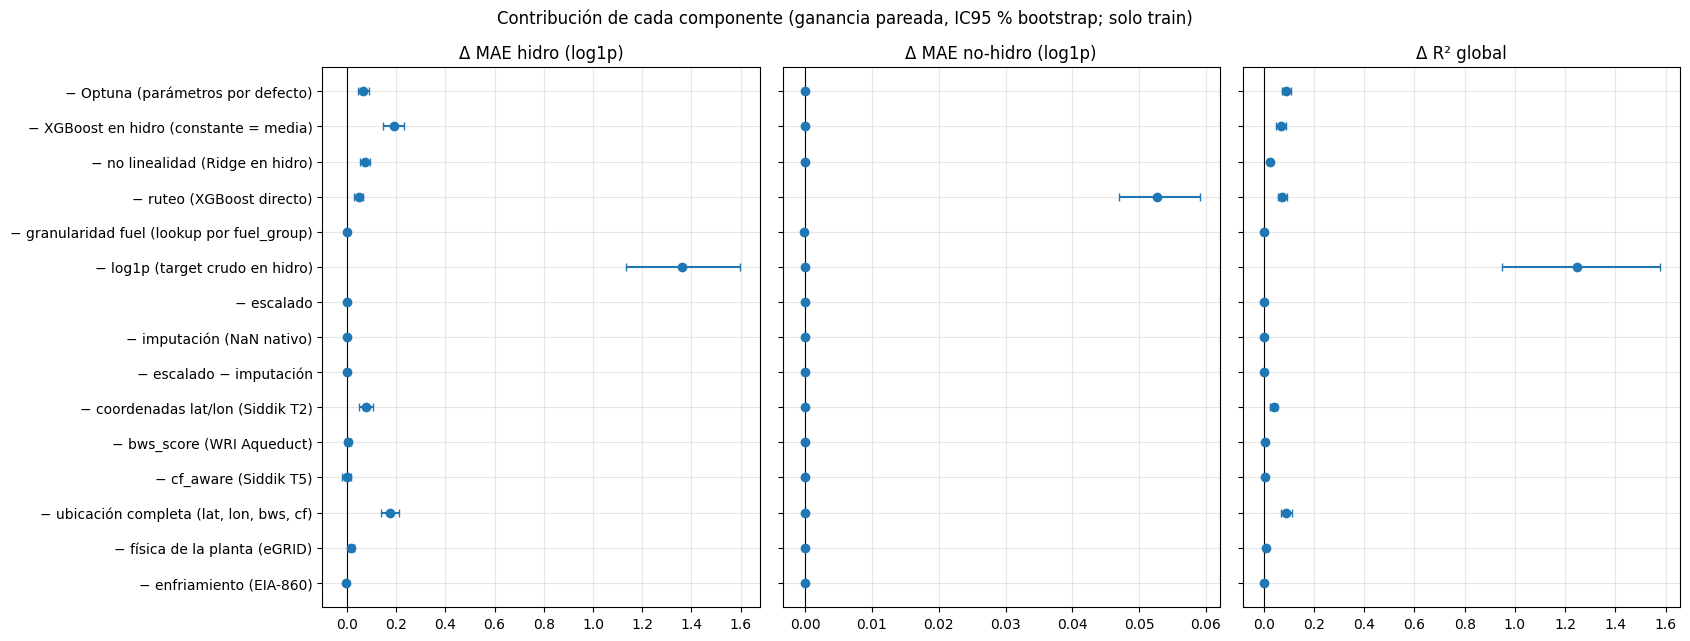

In [ ]:
# ============================================================
# CELDA 30 · Gráfico de contribuciones (esquema `state`; positivo = el componente ayuda)
# ============================================================
import matplotlib.pyplot as plt
t = TAB_LOO["state"].copy()
y = np.arange(len(t))
fig, axes = plt.subplots(1, 3, figsize=(17, 6.5), sharey=True)
for ax, m, tit in zip(axes, ["MAE_hidro", "MAE_no_hidro", "R2"],
                      ["Δ MAE hidro (log1p)", "Δ MAE no-hidro (log1p)", "Δ R² global"]):
    ax.errorbar(t[m], y, xerr=[t[m] - t[m + "_lo"], t[m + "_hi"] - t[m]], fmt="o", capsize=3)
    ax.axvline(0, color="k", lw=0.8)
    ax.set_title(tit); ax.grid(alpha=0.3)
axes[0].set_yticks(y); axes[0].set_yticklabels(t["componente / paso"]); axes[0].invert_yaxis()
fig.suptitle("Contribución de cada componente (ganancia pareada, IC95 % bootstrap; solo train)")
plt.tight_layout()
(BASE / "figures").mkdir(exist_ok=True)
plt.savefig(BASE / "figures" / "ablacion_pipeline.png", dpi=150)
plt.show()


## 7.6 · Confirmación descriptiva en test (celda 31)

In [ ]:
# ============================================================
# CELDA 31 · Confirmación DESCRIPTIVA en test (no se usa para decidir ni para cambiar nada)
# Cada variante se reentrena con todo train y se mide una vez en los 8 estados no vistos.
# Reutiliza: VARIANTES, X_train, y_tr_log, X_test, y_te_log, hid_te.
# ============================================================
filas = {}
for n, fab in VARIANTES.items():
    m = fab().fit(X_train, y_tr_log)
    filas[n] = metricas(y_te_log, m.predict(X_test), hid_te)
tab_test = pd.DataFrame(filas).T.round(3)
ref = tab_test.loc[FINAL]
tab_test["Δ MAE_hidro vs final"] = (tab_test["MAE_hidro"] - ref["MAE_hidro"]).round(3)
tab_test["Δ MAE_no_hidro vs final"] = (tab_test["MAE_no_hidro"] - ref["MAE_no_hidro"]).round(3)
print("TEST (descriptivo; positivo en Δ = la variante es PEOR que el modelo final):")
print(tab_test.to_string())
tab_test.to_csv(PROCESSED_DIR / "ablacion_test_descriptivo.csv")


TEST (descriptivo; positivo en Δ = la variante es PEOR que el modelo final):
                                                R2    MAE  MAE_no_hidro  MAE_hidro  MAE_m3_hidro  razon_media_hidro  Δ MAE_hidro vs final  Δ MAE_no_hidro vs final
Modelo final                                 0.523  0.203         0.020      1.816        81.603              0.087                 0.000                    0.000
− Optuna (parámetros por defecto)            0.488  0.204         0.020      1.827        86.314              0.215                 0.011                    0.000
− XGBoost en hidro (constante = media)       0.489  0.214         0.020      1.929        82.402              0.057                 0.113                    0.000
− no linealidad (Ridge en hidro)             0.502  0.208         0.020      1.870        82.103              0.117                 0.054                    0.000
− ruteo (XGBoost directo)                    0.391  0.293         0.118      1.844        89.134            

## 7.7 · Lectura de resultados

Las expectativas se fijaron **antes** de ver los resultados, a partir de las secciones 5 y 6. Las cifras observadas son las de la celda 29 (entrenamiento, 20 particiones) y la celda 31 (test, descriptivo). "Δ" es la ganancia del componente (positivo = el componente ayuda), con IC95 % bootstrap entre corchetes.

| Componente | Expectativa a priori | Observado (`state`) | Observado (`ba_code`) | En test |
|---|---|---|---|---|
| Ruteo | Aporta, sobre todo fuera de hidro | **Aporta.** ΔMAE +0.052 [+0.046, +0.059]; casi todo en no-hidro (+0.053) y algo en hidro (+0.048) | **Aporta.** ΔMAE +0.052 [+0.039, +0.067]; no-hidro +0.055, hidro +0.034 | MAE no-hidro 0.020 con lookup frente a 0.118 con XGBoost directo |
| Granularidad `fuel` vs `fuel_group` | Aporta poco o nada | **Sin diferencia:** las métricas coinciden a tres decimales | **Sin diferencia** | Idéntico (0.020) |
| XGBoost en hidro vs constante-media | Ganancia pequeña pero positiva | **Aporta.** ΔMAE hidro +0.190 [+0.146, +0.233]; ΔR² +0.069 | **Aporta.** ΔMAE hidro +0.181 [+0.127, +0.230] | +0.113 de MAE hidro (1.816 frente a 1.929) |
| No linealidad (Ridge en hidro) | Sin efecto o pequeño | Aporta: ΔMAE hidro +0.072 [+0.052, +0.093] | **Sin efecto detectable:** +0.030 [−0.006, +0.069] | Ridge es peor en +0.054 |
| Optuna | Pequeño pero positivo | **Aporta.** ΔMAE hidro +0.066 [+0.044, +0.090]; ΔR² +0.090 | **Aporta.** +0.062 [+0.032, +0.090]; ΔR² +0.088 | Solo +0.011 de MAE hidro |
| `log1p` | Mejora el MAE en `log1p` por construcción | **Aporta con mucho margen**, también en m³/MWh: ΔMAE hidro +1.362; ΔMAE m³ +108.9 [+86.0, +135.0]; razón de medias 0.989 sin `log1p` frente a 0.048 con él | **Aporta:** ΔMAE hidro +1.376; ΔMAE m³ +91.5 | R² −0.021 sin `log1p`; MAE m³ 160.9 frente a 81.6 |
| Escalado / imputación | Sin efecto | **Sin efecto** (resultados idénticos) | **Sin efecto** | Idéntico |
| Enfriamiento | Sin efecto en hidro | **Sin efecto:** −0.003 [−0.008, +0.003] | **Sin efecto:** +0.000 [−0.005, +0.007] | +0.002 |
| `lat`, `lon` | Aporta | **Aporta:** ΔMAE hidro +0.079 [+0.048, +0.107] | **Aporta:** +0.056 [+0.014, +0.095] | +0.086 |
| `bws_score` | Aporta poco | Sin efecto detectable (+0.004 [−0.007, +0.016]) | Aporta (+0.023 [+0.010, +0.035]) | −0.008 (quitarlo mejora) |
| `cf_aware` | Aporta poco | Sin efecto detectable | Sin efecto detectable | +0.026 |
| Ubicación completa | Aporta | **Aporta:** ΔMAE hidro +0.176 [+0.139, +0.211]; ΔR² +0.088 | **Aporta:** +0.173 [+0.111, +0.230]; ΔR² +0.085 | +0.036 |
| Física de la planta | Aporta poco | Aporta, magnitud mínima: +0.019 [+0.007, +0.031] | Sin efecto detectable (+0.009 [−0.009, +0.025]) | −0.042 (quitarla mejora) |

**Cómo leer estos resultados.**

1. **Lo robusto (mismo veredicto en ambos esquemas, 12 de 15 componentes):** el ruteo, XGBoost frente a la constante, Optuna, el `log1p` y la ubicación (`lat`/`lon` y el conjunto completo) aportan; el escalado, la imputación, el enfriamiento y `cf_aware` no aportan.
2. **Lo no concluyente (veredicto distinto entre esquemas):** Ridge frente a XGBoost, `bws_score` y la física de la planta. En test, quitar `bws_score` o la física incluso mejora ligeramente el MAE de hidro, así que sus efectos están dentro del ruido.
3. **La etiqueta "estorba" de la granularidad `fuel` es un artefacto numérico.** El efecto es −0.000 [−0.000, −0.000], es decir, cero a seis decimales: las dos tablas producen predicciones indistinguibles. La regla de veredicto de la celda 28 no tenía tolerancia mínima; se corrige en el notebook de mejoras.
4. **El enfriamiento no tiene efecto en hidro por construcción**, no porque no importe en general: fuera de hidro el modelo ruteado usa una tabla de consulta que no lee `cool_*`. Esta ablación no puede probar si el enfriamiento ayuda a las térmicas; esa pregunta se evalúa en el notebook de mejoras (tabla combustible × tipo de enfriamiento).
5. **El `log1p` cambia el problema.** Sin él, la media predicha en hidro es casi la real (razón 0.989), pero el MAE en m³/MWh casi se duplica (261.7 frente a 152.8 en train): unas pocas represas con valores de miles de m³/MWh dominan el error cuadrático. La corrección del sesgo no se resuelve quitando el `log1p`, sino con un estimador de la media robusto a la cola (el notebook de mejoras).

## 7.8 · Escalera acumulativa: de dónde viene el desempeño

| Paso | ΔMAE global `state` | ΔMAE global `ba_code` | Lectura |
|---|---|---|---|
| L0→L1 · tabla de consulta por combustible (B1→B3) | **+0.337** [+0.311, +0.366] | **+0.364** [+0.339, +0.389] | Toda la ganancia está fuera de hidro (+0.434 y +0.452); en hidro la mediana por combustible empeora (−0.100 y −0.048) |
| L1→L2 · hidro = media en vez de mediana por combustible | +0.000 [−0.024, +0.025] | −0.023 [−0.047, +0.001] | Sin efecto en MAE, pero sube el R² (+0.250 y +0.180) |
| L2→L3 · XGBoost en hidro, parámetros por defecto | +0.024 [+0.012, +0.035] | +0.023 [+0.012, +0.036] | Mejora en `log1p`; empeora el MAE en m³ en `state` (−5.2) |
| L3→L4 · Optuna | +0.012 [+0.007, +0.016] | +0.012 [+0.007, +0.017] | Pequeño pero consistente |

La tabla de consulta por combustible explica **≈ 90 % (`state`) y ≈ 97 % (`ba_code`)** de la mejora total de MAE entre la media global y el modelo final. Todo el aprendizaje de máquina en hidro (L2→L4) suma ≈ 0.036 de MAE global. Esto confirma que la contribución del modelo final es en lo esencial la regla de literatura replicada fuera de hidro, y que lo que añade XGBoost es pequeño.

## 7.9 · Contraste con el artículo

El artículo plantea la pregunta de investigación como **falsable**: se responde afirmativamente si el modelo alcanza R² ≥ 0.70 en particiones espaciales retenidas (la sección XI-A lo presenta también como referencia orientativa que se revisaría en la Etapa 2).

| Criterio | Resultado |
|---|---|
| R² global en test (8 estados no vistos) | 0.523 |
| R² global, CV por `state` / `ba_code` (celda 29) | 0.377 / 0.368 |
| R² en hidro (test) | −0.011 |

El umbral de 0.70 **no se alcanza** para la intensidad hídrica por planta. Hay dos matices para el artículo: (i) el R² global está dominado por la tecnología, no por la ubicación (la regla B3 sola da R² 0.196 en test y la ganancia de ubicación se concentra en hidro, donde la señal es débil); (ii) el umbral de R² es poco informativo para un target con 45 % de ceros por construcción, y conviene complementarlo, en la revisión de la Etapa 2, con métricas de lo que consume el AWI (error de WUE_off regional y correlación de ranking). Este resultado es coherente con el rango reportado en Wang et al. (R² desde 0.057 hasta 0.914 según la heterogeneidad), pero no con la expectativa tipo Guidi et al. (0.77).

Tres puntos que conviene aclarar en el texto del artículo:

- **Alcance de los targets.** En este notebook se modela la intensidad hídrica por planta (insumo de WUE_off). PUE y WSF entran como valores tabulados (Masanet et al. 2018 y la tabla de WSF), no como salidas de un modelo, por lo que la respuesta a la pregunta de investigación es parcial.
- **Variables.** La Tabla I del artículo incluye estado, autoridad de balance, subcuenca HUC8, generación PCA y proporción de generación; el modelo final usa combustible, `lat`, `lon`, `bws_score`, `cf_aware`, capacidad, factor de planta, generación neta, n.º de generadores y variables de enfriamiento. Estado, autoridad de balance, HUC8, generación PCA y proporción de generación no son variables del modelo final (`state` es el grupo de la partición), y se añaden estrés hídrico (`bws_score`, `cf_aware`) y enfriamiento. Esas diferencias deben documentarse y justificarse en el artículo.
- **Fuga.** La exclusión de columnas derivadas del target (consumo de agua, CO₂) del artículo sigue vigente; la ablación no introduce variables nuevas.
